# 08 · Logistic Regression: From Probabilities to Decision Boundaries
*AI Foundations · Notebook 08 of 19*

Linear regression answers "how much?". A huge number of real questions are instead **yes/no**:
Is this email spam? Will this patient need intensive care? Will this student qualify for the
national round? **Logistic regression** is the simplest model that answers such questions with a
*probability*. It builds a linear score from the inputs, reads that score as **log-odds**, and
squashes it into $(0, 1)$ with the **sigmoid** function. Its importance goes far beyond its own
applications: a single artificial neuron with a sigmoid output *is* logistic regression, and the
loss you will derive here (cross-entropy) trains almost every modern classifier, from image
models to large language models.

**What you will learn**
- Why a straight line is the wrong tool for yes/no targets, and how *odds* and *log-odds* lead directly to the sigmoid
- The sigmoid's properties (with proofs), its relatives (tanh, arctan, probit), and how to compute it without overflow
- Decision thresholds and the geometry of the decision boundary: normal vector, signed distance, confidence
- Why mean squared error fails here, how **binary cross-entropy** falls out of maximum likelihood, and a proof that it is convex
- The gradient via the chain rule (with its famous cancellation), checked with finite differences and PyTorch autograd
- Training by hand (two full epochs on an 8-student dataset), then in code, and feature scaling, learning rates and Newton's method
- What happens when the classes are perfectly separable (the weights grow forever) and how L2 regularization fixes it
- An end-to-end **Titanic** project: leakage-free feature engineering, mini-batch gradient descent with early stopping,
  a comparison with scikit-learn, evaluation beyond accuracy (baselines, confusion matrix, precision/recall/F1,
  ROC/AUC, precision–recall curves, threshold tuning, calibration) and odds-ratio interpretation
- A preview of multi-class classification (one-vs-rest vs softmax)

**Prerequisites:** Python and NumPy, derivatives, the chain rule and gradient descent (Notebook 04), linear
regression trained with gradient descent, including learning rates, epochs and mini-batches (Notebook 05),
cross-entropy is introduced in Notebook 07, but everything needed here is re-derived, and basic pandas for Section 10.
**Estimated time:** ~6 h (it is long on purpose: read it in two or three sittings).

**How to use this notebook:** run cells top to bottom (Runtime → Run all works).
Exercises are marked ✏️, and each has an automatic checker and a hidden solution
(click "Solution" to expand). Quick-check questions have hidden answers.

**Contents**
1. From regression to classification
2. Probabilities, odds and log-odds
3. The sigmoid function
4. From probabilities to decisions: thresholds and boundaries
5. Choosing a loss: why not MSE, and where cross-entropy comes from
6. Gradients by the chain rule
7. Training with gradient descent: by hand, then in code
8. Separable data: when the weights never stop growing
9. Bonus: Newton's method and IRLS
10. End-to-end project: survival on the Titanic
11. Beyond two classes: a preview
12. Quiz
13. Summary and going further

In [1]:
# Setup: imports, reproducibility, plotting style, helpers
import math
import random
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import scipy
from scipy import special, stats
import sklearn
import torch
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)   # only for code that uses NumPy's global generator, and we create our own generators below
torch.manual_seed(SEED)

# Plot style used throughout the notebook
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
C_POS, C_NEG = PALETTE[0], PALETTE[1]      # class 1 = blue circles, class 0 = orange squares (in every plot)
INK, INK_SOFT = "#0b0b0b", "#52514e"       # model curves and annotations
PROB_CMAP = LinearSegmentedColormap.from_list("prob", [C_NEG, "#f0efec", C_POS])  # p=0 orange, 0.5 gray, 1 blue
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.prop_cycle": plt.cycler(color=PALETTE),
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
np.set_printoptions(precision=5, linewidth=110)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__} | scipy {scipy.__version__} | scikit-learn {sklearn.__version__} | "
      f"torch {torch.__version__}")


# --- tiny test harness for the exercises ---
def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")


def add_bias(X):
    """Prepend a column of ones to a 1-D or 2-D feature array: (m,) or (m, d) -> (m, d+1)."""
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]
    return np.column_stack([np.ones(len(X)), X])


def scatter_classes(ax, X2, y, labels=("class 0", "class 1"), s=40):
    """Scatter 2-D points by label: class 1 = blue circles, class 0 = orange squares."""
    X2, y = np.asarray(X2), np.asarray(y)
    ax.scatter(X2[y == 0, 0], X2[y == 0, 1], marker="s", s=s * 0.9, color=C_NEG, edgecolor="white",
               linewidth=0.8, label=labels[0], zorder=3)
    ax.scatter(X2[y == 1, 0], X2[y == 1, 1], marker="o", s=s, color=C_POS, edgecolor="white",
               linewidth=0.8, label=labels[1], zorder=3)

Python 3.13.15 | numpy 2.5.3 | pandas 2.3.3 | matplotlib 3.11.2 | scipy 1.18.1 | scikit-learn 1.9.1 | torch 2.14.1+cu130


## 1. From regression to classification

### 1.1 Yes/no questions are everywhere

In regression the target $y$ is a number that can take any real value: a price, a temperature,
a test score. In **binary classification** the target takes exactly two values, which we encode
as $y \in \{0, 1\}$:

| Question | $y = 1$ (positive class) | $y = 0$ (negative class) |
|---|---|---|
| Is this email spam? | spam | not spam |
| Is this tumor malignant? | malignant | benign |
| Will this student qualify for the national round? | qualifies | does not qualify |
| Did this Titanic passenger survive? | survived | did not survive |

Which class gets the label 1 is a *convention*: we usually give 1 to the event we are asking
about (the "positive" class). "Positive" does not mean "good": a malignant tumor is the positive class.
What matters is that you choose once and stay consistent, because every formula below is written
for "the probability that $y = 1$".

### 1.2 A tiny dataset: who qualifies?

Eight students in a math club report how many hours per week they practice ($x$) and whether
they qualified for the national round of an olympiad ($y$). We will use these eight students all
the way through Section 9, so it is worth looking at them carefully.

In [2]:
# The 8-student toy dataset used throughout Sections 1-9
x_toy = np.arange(1, 9, dtype=float)                      # practice hours per week: 1, 2, ..., 8
y_toy = np.array([0, 0, 0, 0, 1, 0, 1, 1], dtype=float)   # 1 = qualified for the national round

toy = pd.DataFrame({"student": [f"S{i}" for i in range(1, 9)], "hours x": x_toy.astype(int),
                    "qualified y": y_toy.astype(int)})
display(toy.set_index("student").T)
print(f"m = {len(x_toy)} students, {int(y_toy.sum())} qualified (base rate {y_toy.mean():.3f})")

student,S1,S2,S3,S4,S5,S6,S7,S8
hours x,1,2,3,4,5,6,7,8
qualified y,0,0,0,0,1,0,1,1


m = 8 students, 3 qualified (base rate 0.375)


More practice clearly helps, but the data are not perfectly tidy: S5 (5 hours) qualified while
S6 (6 hours) did not. Real data always contain this kind of noise (a good or bad day, prior
experience, luck). A useful model should therefore not say "qualified: yes/no" with total
certainty. It should say something like "with 6 hours per week, the chance of qualifying is
about 65%".

### 1.3 First attempt: fit a straight line

We already know how to fit a line $\hat y = wx + b$ by least squares (Notebook 05). Nothing stops us
from treating the labels 0 and 1 as numbers and fitting a line to them. Let us try, and then ask
whether the outputs make sense as probabilities.

In [3]:
# Least-squares line through the 0/1 labels (np.linalg.lstsq solves min ||A theta - y||^2)
A_toy = add_bias(x_toy)                                   # shape (8, 2): columns [1, x]
b_ls, w_ls = np.linalg.lstsq(A_toy, y_toy, rcond=None)[0]
print(f"least-squares line: y_hat = {w_ls:.4f} * x + ({b_ls:.4f})")
for hours in [0, 1, 2, 8, 10, 12]:
    print(f"  x = {hours:>2} h  ->  y_hat = {w_ls * hours + b_ls:+.4f}")
print(f"the line crosses 0.5 at x = {(0.5 - b_ls) / w_ls:.2f} h")

least-squares line: y_hat = 0.1548 * x + (-0.3214)
  x =  0 h  ->  y_hat = -0.3214
  x =  1 h  ->  y_hat = -0.1667
  x =  2 h  ->  y_hat = -0.0119
  x =  8 h  ->  y_hat = +0.9167
  x = 10 h  ->  y_hat = +1.2262
  x = 12 h  ->  y_hat = +1.5357
the line crosses 0.5 at x = 5.31 h


The line says $\hat y = 0.1548x - 0.3214$. Read as a probability of qualifying, this is nonsense
at both ends: a student who practices 1 hour gets $-0.1667$ (a *negative* probability), and one
who practices 10 hours gets $1.2262$ (more than 100%). The data only cover 1 to 8 hours, but a
model of probabilities should never leave $[0, 1]$, no matter what $x$ is.

There is a second, subtler problem. Suppose a ninth student joins who practices 20 hours per week and,
unsurprisingly, qualifies. This student tells us almost nothing new about *where* the
transition from "no" to "yes" happens. Watch what the least-squares line does anyway. For comparison we
also draw the **logistic regression** curve, the S-shaped model this notebook is about. For now we let
scikit-learn fit it. By Section 7 you will be able to do it yourself.

In [4]:
from sklearn.linear_model import LogisticRegression

x_extra = np.r_[x_toy, 20.0]                              # a ninth student: 20 h per week, qualified
y_extra = np.r_[y_toy, 1.0]
b_ls2, w_ls2 = np.linalg.lstsq(add_bias(x_extra), y_extra, rcond=None)[0]


def logistic_boundary(x, y):
    """Fit unregularized logistic regression (C=inf) and return (w, b, boundary x where p = 0.5)."""
    clf = LogisticRegression(C=np.inf, tol=1e-10, max_iter=10_000).fit(x[:, None], y)
    w, b = clf.coef_[0, 0], clf.intercept_[0]
    return w, b, -b / w


w_lr1, b_lr1, cut_lr1 = logistic_boundary(x_toy, y_toy)
w_lr2, b_lr2, cut_lr2 = logistic_boundary(x_extra, y_extra)
print(f"0.5-crossing of the least-squares line : {(0.5 - b_ls) / w_ls:.4f} h  ->  {(0.5 - b_ls2) / w_ls2:.4f} h")
print(f"0.5-crossing of the logistic curve     : {cut_lr1:.4f} h  ->  {cut_lr2:.4f} h")
print(f"least-squares prediction for the 7-hour student after adding the 20-hour one: {w_ls2 * 7 + b_ls2:.3f}")

0.5-crossing of the least-squares line : 5.3077 h  ->  7.1618 h
0.5-crossing of the logistic curve     : 5.5157 h  ->  5.5157 h
least-squares prediction for the 7-hour student after adding the 20-hour one: 0.490


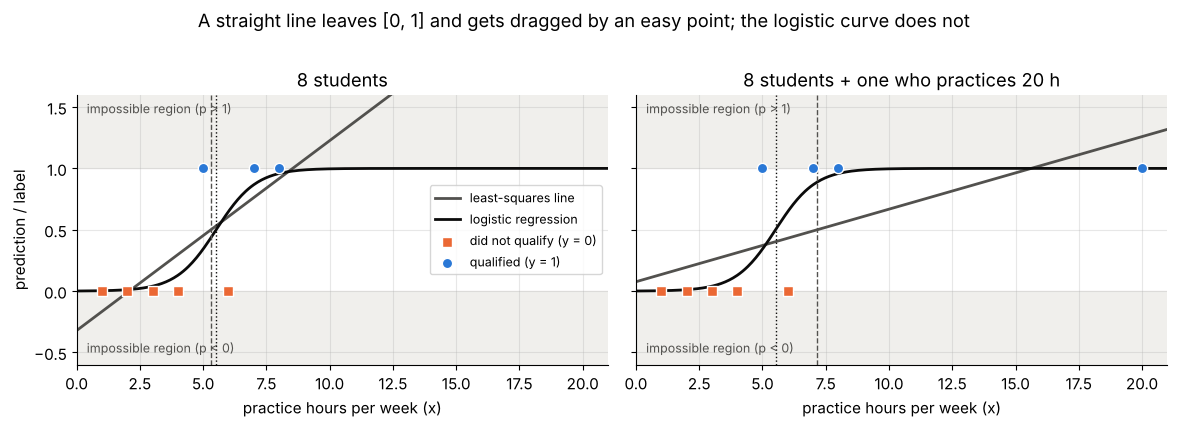

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
grid_x = np.linspace(0, 21, 400)
for ax, (xs, ys, bl, wl, wlr, blr, title) in zip(axes, [
        (x_toy, y_toy, b_ls, w_ls, w_lr1, b_lr1, "8 students"),
        (x_extra, y_extra, b_ls2, w_ls2, w_lr2, b_lr2, "8 students + one who practices 20 h")]):
    ax.axhspan(-0.6, 0, color="#f0efec", zorder=0)
    ax.axhspan(1, 1.6, color="#f0efec", zorder=0)
    ax.plot(grid_x, wl * grid_x + bl, color=INK_SOFT, lw=2, label="least-squares line")
    ax.plot(grid_x, special.expit(wlr * grid_x + blr), color=INK, lw=2, label="logistic regression")
    ax.scatter(xs[ys == 0], ys[ys == 0], marker="s", s=50, color=C_NEG, edgecolor="white", zorder=3, label="did not qualify (y = 0)")
    ax.scatter(xs[ys == 1], ys[ys == 1], marker="o", s=55, color=C_POS, edgecolor="white", zorder=3, label="qualified (y = 1)")
    ax.axvline((0.5 - bl) / wl, color=INK_SOFT, lw=1, ls="--")
    ax.axvline(-blr / wlr, color=INK, lw=1, ls=":")
    ax.set(xlim=(0, 21), ylim=(-0.6, 1.6), xlabel="practice hours per week (x)", title=title)
    ax.text(0.4, 1.45, "impossible region (p > 1)", fontsize=9, color=INK_SOFT)
    ax.text(0.4, -0.5, "impossible region (p < 0)", fontsize=9, color=INK_SOFT)
axes[0].set_ylabel("prediction / label")
axes[0].legend(loc="center right", fontsize=9)
fig.suptitle("A straight line leaves [0, 1] and gets dragged by an easy point, but the logistic curve does not", y=1.01)
plt.tight_layout()
plt.show()

The vertical lines mark where each model crosses 0.5 (dashed: line, dotted: logistic). Adding one
easy, far-away student moves the least-squares crossing from **5.31 h to 7.16 h**, so the line now
predicts $0.490 < 0.5$ for the 7-hour student who *did* qualify. The logistic crossing stays at
**5.5157 h** (unchanged to four decimals). Why the difference?

* Least squares penalizes *every* deviation from the target, including predictions that are "too
  right". For the 20-hour student the original line would predict $0.1548 \cdot 20 - 0.3214 \approx 2.77$,
  which counts as an error of 1.77, so the refit line tilts to shrink it (it now predicts 1.26 at
  20 h, at the expense of the 7-hour student).
* The logistic curve can only approach 1. For a student who is already predicted to qualify with
  probability $\approx 1$, the model has nothing left to fix, so that student exerts almost no pull.
  (Section 6 makes this precise: each student's pull on the parameters is proportional to the
  prediction error $\hat p - y$.)

> **Common pitfall.** "Linear regression plus a 0.5 cut-off" *is* a classifier, and sometimes it
> even works. But its outputs are not probabilities, and its boundary is pulled around by points
> that are far from the boundary and already classified correctly.

### 1.4 What we actually want: a model of $P(y = 1 \mid x)$

Each label is a coin flip whose bias depends on $x$. The right probability model for a 0/1
outcome is the **Bernoulli distribution**: if $P(y = 1) = p$, then

$$
P(y) = p^{\,y}\,(1 - p)^{1 - y}, \qquad y \in \{0, 1\}.
$$

Plug in $y = 1$ and you get $p$. Plug in $y = 0$ and you get $1 - p$. This compact "exponent trick"
will turn into the loss function in Section 5. The mean of a Bernoulli variable is
$\mathbb{E}[y] = 1\cdot p + 0\cdot(1-p) = p$, and its variance is $p(1-p)$.

So the model we want is

$$
y \mid x \;\sim\; \text{Bernoulli}\big(p(x)\big), \qquad p(x) = P(y = 1 \mid x) = \mathbb{E}[\,y \mid x\,].
$$

Notice the last equality: *predicting a probability is the same as predicting the conditional mean
of $y$*, which is exactly what regression does. Linear regression failed only because a line
cannot respect the constraint $0 < p(x) < 1$. We need a model whose output

1. always lies strictly between 0 and 1,
2. changes smoothly and monotonically as the evidence (here, practice hours) increases,
3. is still built from a simple linear score $z = wx + b$, which can be any real number.

Sections 2 and 3 build exactly such a model.

**Quick check.** A model outputs $P(y=1\mid x) = 0.8$ for 100 different students who all practice
the same number of hours. About how many of them do you expect to qualify, and how much would that
count typically fluctuate?

<details>
<summary>Answer</summary>

About $100 \times 0.8 = 80$. The count is a sum of 100 independent Bernoulli(0.8) variables, so its
variance is $100 \times 0.8 \times 0.2 = 16$ and its standard deviation is $\sqrt{16} = 4$: counts
between roughly 72 and 88 would be unremarkable. A probability is a statement about *frequencies*,
not a promise about any single student.
</details>

### 1.5 Vocabulary and notation

Keep this reference table nearby: every term is explained in detail when it first appears.

| Term | Meaning |
|---|---|
| binary classification | predicting which of two classes ($y \in \{0,1\}$) an example belongs to |
| logistic regression | a model of $P(y=1\mid\mathbf{x})$ as the sigmoid of a linear score |
| logit / score $z$ | the linear part $z = \mathbf{w}^\top\mathbf{x} + b$, which equals the log-odds of class 1 |
| sigmoid (logistic function) $\sigma$ | $\sigma(z) = 1/(1+e^{-z})$, maps any real $z$ into $(0,1)$ |
| odds, log-odds | $p/(1-p)$ and $\log\frac{p}{1-p}$ |
| decision threshold $t$ | predict class 1 when $\hat p \ge t$ (default $t = 0.5$) |
| decision boundary | the set of inputs where $\hat p = t$ (for $t = 0.5$ it is $\mathbf{w}^\top\mathbf{x} + b = 0$) |
| loss function | a number measuring how wrong the predictions are, and training minimizes it |
| binary cross-entropy (BCE, log loss) | the standard loss for logistic regression, $-[y\log\hat p + (1-y)\log(1-\hat p)]$ |
| convex function | a function whose chords lie on or above its graph, so every local minimum is global |
| gradient descent (batch / mini-batch / stochastic) | repeated steps against the gradient, computed on all / some / one example(s) |
| epoch | one full pass over the training set |
| learning rate $\eta$, regularization strength $\lambda$ | hyperparameters chosen by the user, not learned |

| Symbol | Meaning | Shape |
|---|---|---|
| $m$, $d$ | number of examples, number of features | scalars |
| $\mathbf{x}_i$, $y_i$ | features and label of example $i$ | $\mathbb{R}^d$, $\{0,1\}$ |
| $X$ | feature matrix (row $i$ is $\mathbf{x}_i^\top$) | $\mathbb{R}^{m\times d}$ |
| $\tilde X$ | $X$ with a leading column of ones (for the bias) | $\mathbb{R}^{m\times(d+1)}$ |
| $\mathbf{w}$, $b$ | weights and bias | $\mathbb{R}^d$, $\mathbb{R}$ |
| $\boldsymbol\theta = (b, \mathbf{w})$ | all parameters stacked, so that $z_i = \tilde{\mathbf{x}}_i^\top\boldsymbol\theta$ | $\mathbb{R}^{d+1}$ |
| $z_i$ | logit of example $i$ | $\mathbb{R}$ |
| $\hat p_i = \sigma(z_i)$ | predicted probability that $y_i = 1$ | $(0,1)$ |
| $\hat y_i \in \{0,1\}$ | hard prediction after applying a threshold | $\{0,1\}$ |
| $\mathcal{L}(\boldsymbol\theta)$ | average loss over the training set | $\mathbb{R}$ |

Many books write $\hat y$ for the predicted *probability*. Here we keep two symbols apart:
$\hat p$ is a probability, $\hat y$ is a 0/1 decision.

## 2. Probabilities, odds and log-odds

The trick behind logistic regression is to stop modelling the probability $p$ directly and model a
*transformed* version of it that lives on the whole real line. The transformation goes in two steps:
probability → odds → log-odds.

### 2.1 Odds

The **odds** of an event with probability $p$ are

$$
\text{odds}(p) = \frac{p}{1 - p}.
$$

Odds compare "how often it happens" with "how often it does not". If $p = 0.75$, the odds are
$0.75/0.25 = 3$: the event happens 3 times for every 1 time it does not ("3 to 1"). Even odds
($p = 0.5$) means odds of 1, and $p = 0.2$ gives odds of $0.25$ ("1 to 4"). To go back, solve
$o = p/(1-p)$ for $p$: $p = o/(1+o)$.

Odds already escape the upper limit: as $p \to 1$, the odds grow without bound. But they are still
stuck above 0, and they are lopsided: all probabilities below one half are squeezed into $(0, 1)$,
while those above one half are stretched over $(1, \infty)$.

### 2.2 Log-odds (the logit)

Taking the logarithm fixes both problems. The **log-odds**, or **logit**, is

$$
\operatorname{logit}(p) = \log\frac{p}{1-p}, \qquad p \in (0, 1).
$$

(Throughout this notebook, $\log$ is the natural logarithm.) As $p$ goes from 0 to 1, the logit
runs over **all real numbers**, from $-\infty$ to $+\infty$. It is also perfectly symmetric:

$$
\operatorname{logit}(1 - p) = \log\frac{1-p}{p} = -\operatorname{logit}(p), \qquad \operatorname{logit}(0.5) = \log 1 = 0.
$$

So "more likely than not" means positive log-odds, "less likely than not" means negative log-odds,
and a coin flip sits at exactly 0.

p,0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99
odds p/(1-p),0.0101,0.0526,0.1111,0.3333,1.0,3.0000,9.0000,19.0000,99.0000
log-odds,-4.5951,-2.9444,-2.1972,-1.0986,0.0,1.0986,2.1972,2.9444,4.5951


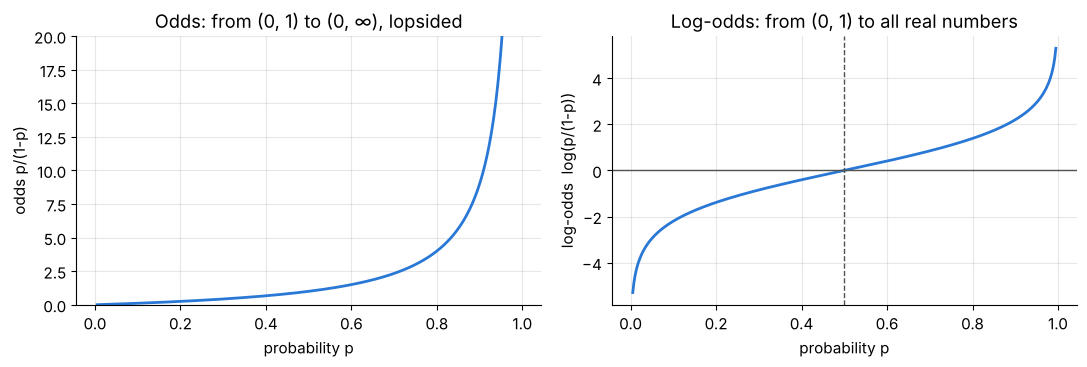

In [6]:
p_vals = np.array([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
odds_vals = p_vals / (1 - p_vals)
odds_table = pd.DataFrame({"p": p_vals, "odds p/(1-p)": odds_vals, "log-odds": np.log(odds_vals)})
display(odds_table.round(4).set_index("p").T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
p_grid = np.linspace(0.005, 0.995, 400)
axes[0].plot(p_grid, p_grid / (1 - p_grid), color=PALETTE[0], lw=2)
axes[0].set(ylim=(0, 20), xlabel="probability p", ylabel="odds p/(1-p)", title="Odds: from (0, 1) to (0, ∞), lopsided")
axes[1].plot(p_grid, special.logit(p_grid), color=PALETTE[0], lw=2)
axes[1].axhline(0, color=INK_SOFT, lw=1)
axes[1].axvline(0.5, color=INK_SOFT, lw=1, ls="--")
axes[1].set(xlabel="probability p", ylabel="log-odds  log(p/(1-p))", title="Log-odds: from (0, 1) to all real numbers")
plt.tight_layout()
plt.show()

Look at the symmetry in the table: $p = 0.1$ and $p = 0.9$ have log-odds $-2.1972$ and $+2.1972$.
Also notice how the logit *stretches the extremes*: going from $p = 0.95$ to $p = 0.99$ is a small
step in probability but a big step in log-odds ($2.9444 \to 4.5951$). On the log-odds scale,
"very sure" and "extremely sure" are far apart, which is exactly how evidence behaves.

### 2.3 The modelling idea: make the log-odds linear

A linear score $z = wx + b$ can be any real number, and so can the log-odds. So let us simply
declare them equal:

$$
\log\frac{p(x)}{1 - p(x)} = z = wx + b.
$$

This is the entire modelling assumption of logistic regression: **the log-odds of class 1 is a linear
function of the features.** Now solve for $p$, one step at a time:

$$
\frac{p}{1-p} = e^{z}
\;\;\Longrightarrow\;\; p = e^{z}(1-p)
\;\;\Longrightarrow\;\; p\,(1 + e^{z}) = e^{z}
\;\;\Longrightarrow\;\; p = \frac{e^{z}}{1 + e^{z}} = \frac{1}{1 + e^{-z}}.
$$

(For the last equality, divide numerator and denominator by $e^{z}$.) The function

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

is the **logistic sigmoid**, and we have just shown that it is the *inverse of the logit*:
$\sigma(\operatorname{logit}(p)) = p$ and $\operatorname{logit}(\sigma(z)) = z$. The full model is

$$
P(y = 1 \mid x) = \hat p = \sigma(wx + b) = \frac{1}{1 + e^{-(wx + b)}},
$$

and with $d$ features, $\hat p = \sigma(\mathbf{w}^\top\mathbf{x} + b)$. This is why $z$ is called the
**logit** of the model: it *is* the predicted log-odds. The sigmoid is not an arbitrary
S-shaped curve someone liked. It is forced on us by the decision to model log-odds linearly.

> **Key idea.** Logistic regression is linear regression *on the log-odds scale*. Everything that is
> "linear" about the model (the score $z$, the decision boundary) lives on that scale, and the
> sigmoid translates the score into a probability at the very end.

### 2.4 Reading the coefficients: odds ratios

What does the weight $w$ mean? Increase $x$ by one unit. The log-odds increase by exactly $w$, so
the odds get **multiplied** by $e^{w}$:

$$
\frac{\text{odds}(x + 1)}{\text{odds}(x)} = \frac{e^{w(x+1) + b}}{e^{wx + b}} = e^{w}.
$$

The number $e^{w}$ is the **odds ratio** for a one-unit increase in $x$. It is the same at every
$x$, which makes it a convenient summary. Let us use the fitted toy model from Section 1.3
(scikit-learn gave $w \approx 1.2624$, $b \approx -6.9630$, and Section 7 derives these numbers ourselves).

In [7]:
w_fit, b_fit = w_lr1, b_lr1          # fitted on the 8 students in Section 1.3
print(f"w = {w_fit:.4f}, b = {b_fit:.4f}, odds ratio per extra hour e^w = {np.exp(w_fit):.4f}")

hours = np.arange(3, 9, dtype=float)
z_h = w_fit * hours + b_fit
p_h = special.expit(z_h)              # scipy's sigmoid: expit(z) = 1 / (1 + exp(-z))
ratio_table = pd.DataFrame({
    "hours x": hours.astype(int), "log-odds z": z_h, "odds": np.exp(z_h), "p": p_h,
    "odds ratio vs previous hour": np.r_[np.nan, np.exp(np.diff(z_h))],
    "change in p vs previous hour": np.r_[np.nan, np.diff(p_h)],
})
display(ratio_table.round(4))
print(f"largest possible slope dp/dx = w/4 = {w_fit / 4:.4f} per hour (reached where p = 0.5)")

w = 1.2624, b = -6.9630, odds ratio per extra hour e^w = 3.5339


,hours x,log-odds z,odds,p,odds ratio vs previous hour,change in p vs previous hour
0,3,-3.1758,0.0418,0.0401,NaN,NaN
1,4,-1.9134,0.1476,0.1286,3.5339,0.0885
2,5,-0.6510,0.5215,0.3428,3.5339,0.2142
3,6,0.6114,1.8430,0.6483,3.5339,0.3055
4,7,1.8738,6.5131,0.8669,3.5339,0.2186
5,8,3.1362,23.0165,0.9584,3.5339,0.0915


largest possible slope dp/dx = w/4 = 0.3156 per hour (reached where p = 0.5)


Each extra hour of practice multiplies the odds of qualifying by $e^{1.2624} \approx 3.53$, whatever
the starting point. The *probability*, however, changes by different amounts: $+0.2142$ from 4 to
5 hours, $+0.3055$ from 5 to 6 hours, $+0.2186$ from 6 to 7 hours, and only $+0.0915$ from 7 to 8
hours. The probability moves fastest near $p = 0.5$ and slowly near 0 or 1. Differentiating gives
the exact rule (we prove $\sigma' = \sigma(1-\sigma)$ in Section 3):

$$
\frac{d\hat p}{dx} = w\,\hat p\,(1 - \hat p) \;\le\; \frac{w}{4},
$$

because $\hat p(1-\hat p) \le 1/4$. This is the handy **divide-by-4 rule**: a coefficient $w$ changes
the probability by *at most* $w/4$ per unit of $x$ (here $0.3156$ per hour).

> **Common pitfall.** "An odds ratio of 3.53 means 3.53 times as likely." No: going from 5 to 6
> hours, the probability goes from $0.3428$ to $0.6483$, a ratio of only about 1.89. Odds ratios and
> probability ratios (risk ratios) are close only when the event is rare ($p$ small, so odds $\approx p$).

**Quick check.** A model has log-odds $z = 0.4x - 1$. What is the probability at $x = 0$, and by what
factor do the odds change when $x$ increases by 5?

<details>
<summary>Answer</summary>

At $x = 0$: $z = -1$, so $\hat p = \sigma(-1) = 1/(1+e) \approx 0.2689$. Increasing $x$ by 5 adds
$0.4 \times 5 = 2$ to the log-odds, so the odds are multiplied by $e^{2} \approx 7.39$.
</details>

In [8]:
# ✏️ Exercise 1: odds-ratio arithmetic
def prob_after_change(p0, w, dx):
    """A logistic model has coefficient w for feature x. A case currently has probability p0.
    Return the new probability after x increases by dx (other features unchanged).
    Works for floats and for NumPy arrays (element-wise)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert np.isclose(prob_after_change(0.5, np.log(3), 1), 0.75), "p0=0.5, odds x3 -> 0.75"
    assert np.isclose(prob_after_change(0.2, np.log(2), 2), 0.5), "odds 0.25 * 2^2 = 1 -> p = 0.5"
    assert np.isclose(prob_after_change(0.9, -np.log(9), 1), 0.5), "a negative w lowers the probability"
    assert np.isclose(prob_after_change(0.3, 1.7, 0), 0.3), "dx = 0 must not change anything"
    out = prob_after_change(np.array([0.1, 0.5, 0.9]), 1.0, -1.0)
    assert np.allclose(out, [0.0392703, 0.2689414, 0.7680307], atol=1e-6), f"vectorized case: got {out}"

run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def prob_after_change(p0, w, dx):
    p0 = np.asarray(p0, dtype=float)
    new_logodds = np.log(p0 / (1 - p0)) + w * dx   # move along the log-odds scale
    return 1 / (1 + np.exp(-new_logodds))          # back to a probability
```
Work on the log-odds scale, where the change is simply additive ($+w\,\Delta x$), then map back with the
sigmoid. Multiplying the odds by $e^{w\Delta x}$ and using $p = o/(1+o)$ is the same computation.
</details>

### 2.5 A second road to the sigmoid: Bayes' rule

There is a deeper reason why the sigmoid appears. Suppose we knew how practice hours are distributed
*within* each class: a density $f_1(x)$ for students who qualify and $f_0(x)$ for those who do not,
with prior probabilities $\pi_1 = P(y=1)$ and $\pi_0 = 1 - \pi_1$. Bayes' rule gives

$$
P(y = 1 \mid x) = \frac{\pi_1 f_1(x)}{\pi_1 f_1(x) + \pi_0 f_0(x)}
= \frac{1}{1 + \dfrac{\pi_0 f_0(x)}{\pi_1 f_1(x)}}
= \sigma\big(a(x)\big), \qquad a(x) = \log\frac{\pi_1 f_1(x)}{\pi_0 f_0(x)}.
$$

This is *always* true: a posterior probability is the sigmoid of the posterior log-odds $a(x)$. The only
question is what $a(x)$ looks like. Take the classic case of two normal distributions with the same
spread, $f_k = \mathcal{N}(\mu_k, s^2)$. Then

$$
a(x) = \log\frac{\pi_1}{\pi_0} - \frac{(x-\mu_1)^2}{2s^2} + \frac{(x-\mu_0)^2}{2s^2}
= \underbrace{\frac{\mu_1 - \mu_0}{s^2}}_{w}\,x \;+\; \underbrace{\frac{\mu_0^2 - \mu_1^2}{2s^2} + \log\frac{\pi_1}{\pi_0}}_{b},
$$

because the $x^2$ terms cancel. The posterior log-odds is *exactly linear*, so the posterior is
*exactly* a logistic regression. Let us check this numerically with $\mu_0 = 2.5$, $\mu_1 = 6.5$,
$s = 1.5$ and $\pi_1 = 0.375$.

implied logistic parameters: w = 1.7778, b = -8.5108
max |Bayes posterior - logistic curve| on the grid: 3.33e-16


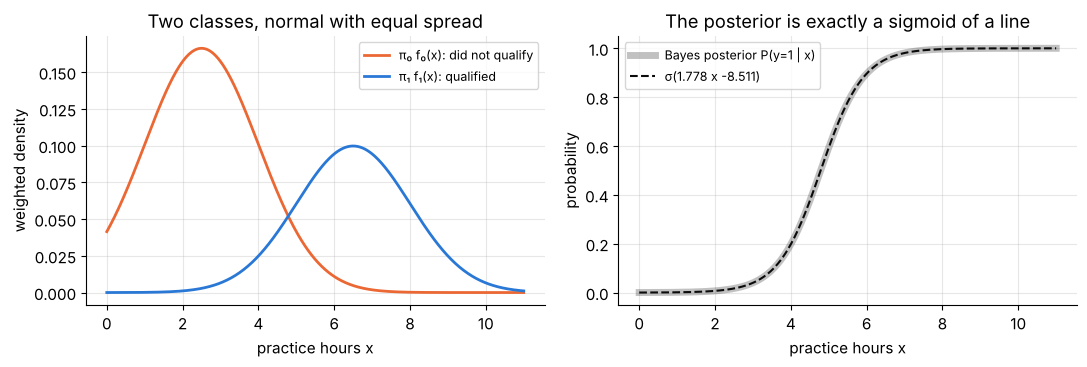

In [9]:
mu0, mu1, s, pi1 = 2.5, 6.5, 1.5, 0.375
w_bayes = (mu1 - mu0) / s**2
b_bayes = (mu0**2 - mu1**2) / (2 * s**2) + np.log(pi1 / (1 - pi1))
print(f"implied logistic parameters: w = {w_bayes:.4f}, b = {b_bayes:.4f}")

xg = np.linspace(0, 11, 500)
joint1 = pi1 * stats.norm.pdf(xg, mu1, s)            # pi_1 * f_1(x)
joint0 = (1 - pi1) * stats.norm.pdf(xg, mu0, s)      # pi_0 * f_0(x)
posterior = joint1 / (joint1 + joint0)                # Bayes' rule
logistic = special.expit(w_bayes * xg + b_bayes)
print(f"max |Bayes posterior - logistic curve| on the grid: {np.max(np.abs(posterior - logistic)):.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(xg, joint0, color=C_NEG, lw=2, label="π₀ f₀(x): did not qualify")
axes[0].plot(xg, joint1, color=C_POS, lw=2, label="π₁ f₁(x): qualified")
axes[0].set(xlabel="practice hours x", ylabel="weighted density", title="Two classes, normal with equal spread")
axes[0].legend(fontsize=9)
axes[1].plot(xg, posterior, color=INK, lw=5, alpha=0.25, label="Bayes posterior P(y=1 | x)")
axes[1].plot(xg, logistic, color=INK, lw=1.5, ls="--", label=f"σ({w_bayes:.3f} x {b_bayes:+.3f})")
axes[1].set(xlabel="practice hours x", ylabel="probability", title="The posterior is exactly a sigmoid of a line")
axes[1].legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

The two curves on the right coincide (the largest difference is at the level of floating-point
rounding). Two lessons:

1. Logistic regression is the *exactly correct* model whenever the classes are normal with a shared
   spread (and, more generally, for many other distribution families).
2. Logistic regression never models $f_0$ or $f_1$ at all. It goes straight for $P(y=1\mid x)$, so
   it does not need the normality assumption to be useful.

> **Going deeper.** Models that describe how the data are generated ($P(x\mid y)$ and $P(y)$) are called
> **generative** (here: Gaussian class densities, also known as linear discriminant analysis). Models
> that describe only $P(y \mid x)$ are **discriminative**, and logistic regression is the classic example.
> If the two classes had *different* spreads, the $x^2$ terms would not cancel and the log-odds would be
> quadratic, but logistic regression can still capture that if you give it $x^2$ as an extra feature
> (Section 7.7). A classic comparison of the two approaches is Ng & Jordan (2002), listed at the end.

## 3. The sigmoid function

### 3.1 Shape and a few values worth memorizing

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

* When $z$ is large and positive, $e^{-z} \approx 0$, so $\sigma(z) \approx 1/(1 + 0) = 1$.
* When $z$ is large and negative, $e^{-z}$ is huge, so $\sigma(z) \approx 0$.
* At $z = 0$, $e^{0} = 1$, so $\sigma(0) = 1/2$: a score of zero means a 50/50 guess.

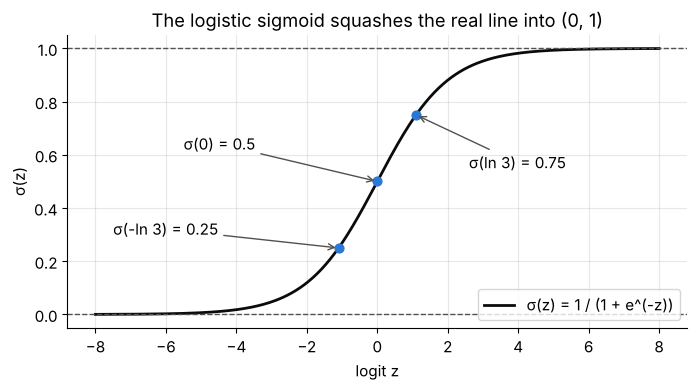

z,-6.0,-4.0,-2.0,-1.0,0.0,1.0,2.0,4.0,6.0
σ(z),0.0025,0.018,0.1192,0.2689,0.5,0.7311,0.8808,0.982,0.9975


In [10]:
z_grid = np.linspace(-8, 8, 400)
sig_grid = 1 / (1 + np.exp(-z_grid))          # fine for |z| <= 8, and Section 3.4 handles extreme z

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(z_grid, sig_grid, color=INK, lw=2, label="σ(z) = 1 / (1 + e^(-z))")
ax.axhline(1, color=INK_SOFT, lw=1, ls="--")
ax.axhline(0, color=INK_SOFT, lw=1, ls="--")
ax.scatter([0, np.log(3), -np.log(3)], [0.5, 0.75, 0.25], color=PALETTE[0], zorder=3, s=40)
ax.annotate("σ(0) = 0.5", (0, 0.5), xytext=(-5.5, 0.62), arrowprops=dict(arrowstyle="->", color=INK_SOFT))
ax.annotate("σ(ln 3) = 0.75", (np.log(3), 0.75), xytext=(2.6, 0.55), arrowprops=dict(arrowstyle="->", color=INK_SOFT))
ax.annotate("σ(-ln 3) = 0.25", (-np.log(3), 0.25), xytext=(-7.5, 0.3), arrowprops=dict(arrowstyle="->", color=INK_SOFT))
ax.set(xlabel="logit z", ylabel="σ(z)", title="The logistic sigmoid squashes the real line into (0, 1)")
ax.legend(loc="lower right")
plt.show()

table_z = np.array([-6, -4, -2, -1, 0, 1, 2, 4, 6], dtype=float)
display(pd.DataFrame({"z": table_z, "σ(z)": 1 / (1 + np.exp(-table_z))}).round(4).set_index("z").T)

> **Olympiad tip.** For by-hand questions, a few values go a long way: $\sigma(0) = 0.5$,
> $\sigma(\pm 1) \approx 0.7311 / 0.2689$, $\sigma(\pm 2) \approx 0.8808 / 0.1192$, $\sigma(\ln 3) = 0.75$
> exactly, $\sigma(\ln 9) = 0.9$ exactly. In general $\sigma(\ln k) = k/(k+1)$, because $e^{-\ln k} = 1/k$.

### 3.2 Properties, with proofs

**(P1) Range.** Since $e^{-z} > 0$, the denominator $1 + e^{-z}$ is greater than 1, so
$0 < \sigma(z) < 1$ for every real $z$. The values 0 and 1 are approached but **never reached**:
a logistic model never outputs a probability of exactly 0 or 1.

**(P2) Symmetry: $\sigma(-z) = 1 - \sigma(z)$.** Multiply the numerator and denominator of $\sigma(-z)$ by $e^{-z}$:

$$
\sigma(-z) = \frac{1}{1 + e^{z}} = \frac{e^{-z}}{e^{-z} + 1} = \frac{(1 + e^{-z}) - 1}{1 + e^{-z}} = 1 - \frac{1}{1 + e^{-z}} = 1 - \sigma(z).
$$

Meaning: flipping the sign of the score swaps the two class probabilities. Geometrically, the graph is
point-symmetric about $(0, \tfrac12)$. We will use this identity constantly, for example
$1 - \hat p = \sigma(-z)$.

**(P3) Derivative: $\sigma'(z) = \sigma(z)\,\big(1 - \sigma(z)\big)$.** Write $\sigma(z) = (1 + e^{-z})^{-1}$ and use the chain rule:

$$
\sigma'(z) = -(1 + e^{-z})^{-2}\cdot\big(-e^{-z}\big) = \frac{e^{-z}}{(1 + e^{-z})^2}
= \underbrace{\frac{1}{1 + e^{-z}}}_{\sigma(z)}\cdot\underbrace{\frac{e^{-z}}{1 + e^{-z}}}_{1 - \sigma(z)} .
$$

The second factor equals $1 - \sigma(z)$ by the same "add and subtract 1" step as in (P2). This identity is
the reason logistic regression has such a clean gradient (Section 6): the derivative of the sigmoid is
written in terms of the sigmoid itself, so we never need to compute an extra exponential.

**(P4) Monotone, with maximal slope $1/4$ at $z = 0$.** Both factors in (P3) are positive, so $\sigma$ is strictly
increasing. With $s = \sigma(z) \in (0,1)$, the slope $s(1-s) = \tfrac14 - (s - \tfrac12)^2 \le \tfrac14$, with equality
exactly when $s = \tfrac12$, i.e. $z = 0$. Differentiating once more, $\sigma''(z) = \sigma'(z)\,(1 - 2\sigma(z))$, which
changes sign at $z = 0$: that is the single **inflection point** of the S.

**(P5) Saturation.** Far from 0 the curve is almost flat: $\sigma'(2) \approx 0.105$, $\sigma'(5) \approx 0.0066$,
$\sigma'(10) \approx 0.000045$. A sigmoid that is pushed deep into its flat tails passes almost no gradient
back to whatever produced $z$. This becomes important when we compare loss functions in Section 5.

**(P6) Relation to tanh: $\sigma(z) = \tfrac12\big(1 + \tanh(z/2)\big)$.** Since
$\tanh u = \dfrac{e^{u} - e^{-u}}{e^{u} + e^{-u}}$, we get $\tfrac12(1 + \tanh u) = \dfrac{e^{u}}{e^{u} + e^{-u}} = \dfrac{1}{1 + e^{-2u}}$.
Set $u = z/2$. So tanh is just a stretched and shifted logistic.

**(P7) Inverse.** From Section 2.3, $\sigma^{-1}(p) = \operatorname{logit}(p) = \log\frac{p}{1-p}$.

Let us check (P2), (P3) and (P6) numerically, and plot the derivative.

P2  max |σ(-z) - (1 - σ(z))|        : 1.5e-16
P3  max |finite diff - σ(1-σ)|      : 7.2e-11
P6  max |σ(z) - (1 + tanh(z/2))/2|  : 1.1e-16
σ'( 0) = 0.250000
σ'( 2) = 0.104994
σ'( 5) = 0.006648
σ'(10) = 0.000045


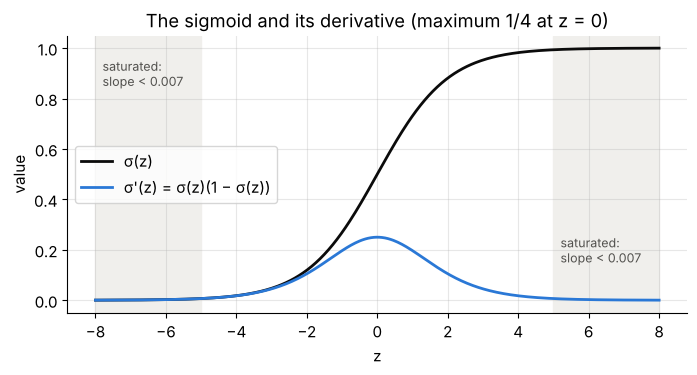

In [11]:
z_chk = np.linspace(-6, 6, 13)
sig = lambda z: 1 / (1 + np.exp(-z))
h = 1e-6
fd_slope = (sig(z_chk + h) - sig(z_chk - h)) / (2 * h)            # central finite difference
print("P2  max |σ(-z) - (1 - σ(z))|        :", f"{np.max(np.abs(sig(-z_chk) - (1 - sig(z_chk)))):.1e}")
print("P3  max |finite diff - σ(1-σ)|      :", f"{np.max(np.abs(fd_slope - sig(z_chk) * (1 - sig(z_chk)))):.1e}")
print("P6  max |σ(z) - (1 + tanh(z/2))/2|  :", f"{np.max(np.abs(sig(z_chk) - 0.5 * (1 + np.tanh(z_chk / 2)))):.1e}")
for zz in [0, 2, 5, 10]:
    print(f"σ'({zz:>2}) = {sig(zz) * (1 - sig(zz)):.6f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(z_grid, sig_grid, color=INK, lw=2, label="σ(z)")
ax.plot(z_grid, sig_grid * (1 - sig_grid), color=PALETTE[0], lw=2, label="σ'(z) = σ(z)(1 − σ(z))")
ax.axvspan(-8, -5, color="#f0efec", zorder=0)
ax.axvspan(5, 8, color="#f0efec", zorder=0)
ax.text(-7.8, 0.85, "saturated:\nslope < 0.007", fontsize=9, color=INK_SOFT)
ax.text(5.2, 0.15, "saturated:\nslope < 0.007", fontsize=9, color=INK_SOFT)
ax.set(xlabel="z", ylabel="value", title="The sigmoid and its derivative (maximum 1/4 at z = 0)")
ax.legend(loc="center left")
plt.show()

### 3.3 The sigmoid family: logistic, tanh, arctan, probit

"Sigmoid" literally means "S-shaped". Mathematicians use it for a whole **family** of functions that are
defined on all real numbers, increasing, bounded, and have a single inflection point. The logistic function
is the most famous member, and in machine learning "the sigmoid" almost always means the logistic
function. Other members:

| function | formula | range | tails approach the limits like |
|---|---|---|---|
| logistic | $\sigma(z) = 1/(1+e^{-z})$ | $(0, 1)$ | $e^{-\lvert z\rvert}$ |
| hyperbolic tangent | $\tanh z = (e^{z} - e^{-z})/(e^{z} + e^{-z})$ | $(-1, 1)$ | $e^{-2\lvert z\rvert}$ |
| arctangent | $\arctan z$ | $(-\pi/2, \pi/2)$ | $1/\lvert z\rvert$ (slow, heavy tails) |
| normal CDF ("probit") | $\Phi(z) = P(\mathcal{N}(0,1) \le z)$ | $(0, 1)$ | $e^{-z^2/2}$ (very fast) |

To compare their *shapes* fairly, the right panel below rescales each one to the range $(0, 1)$ and
matches its slope at 0 to the logistic's slope $1/4$. (By (P6), the rescaled tanh coincides exactly with
the logistic, so it is not drawn twice.)

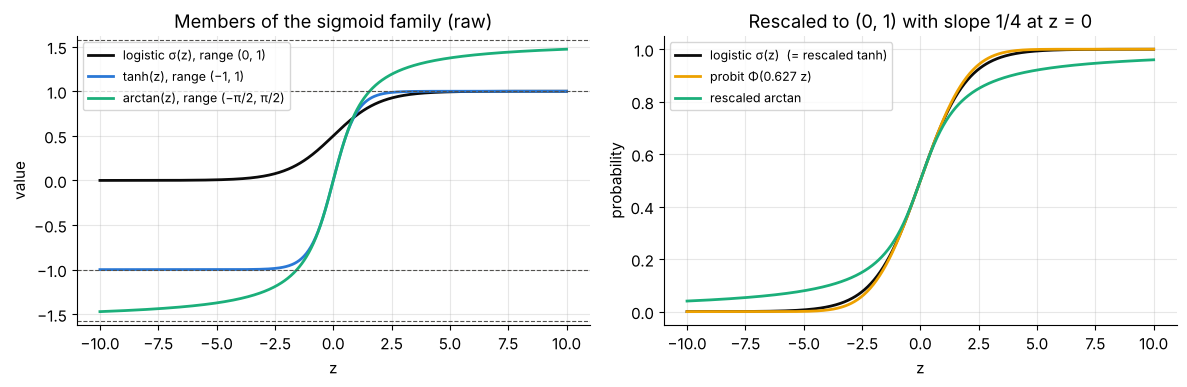

max |σ(1.702 z) − Φ(z)| = 0.0095


In [12]:
k_probit = np.sqrt(2 * np.pi) / 4      # slope of Phi(k z) at 0 is k / sqrt(2 pi), so set it to 1/4
k_arctan = np.pi / 4                   # slope of 1/2 + arctan(k z)/pi at 0 is k / pi, so set it to 1/4
zz = np.linspace(-10, 10, 600)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(zz, special.expit(zz), color=INK, lw=2, label="logistic σ(z), range (0, 1)")
axes[0].plot(zz, np.tanh(zz), color=PALETTE[0], lw=2, label="tanh(z), range (−1, 1)")
axes[0].plot(zz, np.arctan(zz), color=PALETTE[2], lw=2, label="arctan(z), range (−π/2, π/2)")
for level in [1, -1, np.pi / 2, -np.pi / 2]:
    axes[0].axhline(level, color=INK_SOFT, lw=0.8, ls="--")
axes[0].set(xlabel="z", ylabel="value", title="Members of the sigmoid family (raw)")
axes[0].legend(fontsize=9, loc="upper left")

axes[1].plot(zz, special.expit(zz), color=INK, lw=2, label="logistic σ(z)  (= rescaled tanh)")
axes[1].plot(zz, stats.norm.cdf(k_probit * zz), color=PALETTE[3], lw=2, label="probit Φ(0.627 z)")
axes[1].plot(zz, 0.5 + np.arctan(k_arctan * zz) / np.pi, color=PALETTE[2], lw=2, label="rescaled arctan")
axes[1].set(xlabel="z", ylabel="probability", title="Rescaled to (0, 1) with slope 1/4 at z = 0")
axes[1].legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

z_dense = np.linspace(-10, 10, 200_001)
print(f"max |σ(1.702 z) − Φ(z)| = {np.max(np.abs(special.expit(1.702 * z_dense) - stats.norm.cdf(z_dense))):.4f}")

All of these could squash a score into a probability-like number. Why does machine learning use the
logistic one?

1. **Interpretability.** It is the inverse of the log-odds (Section 2.3), so coefficients become odds ratios.
2. **A clean gradient.** Its derivative $\sigma(1-\sigma)$ cancels perfectly against the logarithms in the
   cross-entropy loss, leaving the gradient $(\hat p - y)\,\mathbf{x}$ (Section 6).
3. **Theory.** It is the exact posterior for normal classes with shared spread (Section 2.5), and more
   generally the "canonical" choice for Bernoulli data in the theory of generalized linear models.

In practice the alternatives behave similarly in the middle and differ in the tails. **Probit regression**
(using $\Phi$) gives almost the same fitted probabilities as logistic regression: $\sigma(1.702z)$ and
$\Phi(z)$ never differ by more than about 0.0095. The **arctan** link has heavy tails, so a single
mislabeled point far from the boundary costs it less, which makes it more robust to label noise. And
**tanh**, which is $2\sigma(2z) - 1$, is popular as a hidden-layer activation in neural networks because
its output is centered at 0.

### 3.4 Computing the sigmoid safely

A computer stores numbers with finite precision, and `exp` overflows quickly: in 64-bit floating point,
$e^{z}$ is `inf` for $z > 709.78$. Logits of size 1000 sound absurd, but they do appear (for example with
unscaled features or in the separable case of Section 8). Let us see what the two textbook formulas
$\frac{1}{1+e^{-z}}$ and $\frac{e^{z}}{1+e^{z}}$ do there.

In [13]:
z_ext = np.array([-1000.0, -40.0, 0.0, 40.0, 1000.0])
with np.errstate(all="ignore"):              # silence NumPy's overflow warnings so we can inspect the results
    naive_a = 1 / (1 + np.exp(-z_ext))       # exp(1000) overflows to inf inside, 1/inf happens to give 0
    naive_b = np.exp(z_ext) / (1 + np.exp(z_ext))   # inf / inf = nan
print("z                 :", z_ext)
print("1/(1+exp(-z))     :", naive_a)
print("exp(z)/(1+exp(z)) :", naive_b)
try:
    with np.errstate(over="raise"):          # turn the silent overflow into an error to prove it happened
        1 / (1 + np.exp(-z_ext))
except FloatingPointError as err:
    print("with over='raise':", type(err).__name__, "->", err)

z                 : [-1000.   -40.     0.    40.  1000.]
1/(1+exp(-z))     : [0.00000e+00 4.24835e-18 5.00000e-01 1.00000e+00 1.00000e+00]
exp(z)/(1+exp(z)) : [0.00000e+00 4.24835e-18 5.00000e-01 1.00000e+00         nan]
with over='raise': FloatingPointError -> overflow encountered in exp


The first formula *happens* to return the right numbers, but only because `1/inf` is 0. Along the way
NumPy overflowed (and normally prints a `RuntimeWarning`). The second formula returns `nan` for $z = 1000$.
The cure is to make sure we only ever exponentiate **non-positive** numbers:

$$
\sigma(z) = \begin{cases} \dfrac{1}{1 + e^{-z}}, & z \ge 0,\\[2ex] \dfrac{e^{z}}{1 + e^{z}}, & z < 0. \end{cases}
$$

Both branches are the same function, but each uses $e^{-|z|} \in (0, 1]$, which can never overflow.

> **Common pitfall.** `np.where(z >= 0, 1/(1+np.exp(-z)), np.exp(z)/(1+np.exp(z)))` does **not** fix the
> problem: `np.where` evaluates *both* branches on *all* elements before choosing, so the overflow still
> happens. Compute `e = np.exp(-np.abs(z))` once and build both branches from it.

In [14]:
def sigmoid(z):
    """Numerically stable logistic sigmoid. Works on scalars and arrays of any shape."""
    z = np.asarray(z, dtype=float)
    e = np.exp(-np.abs(z))                   # always in (0, 1]: no overflow possible
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


print("our sigmoid       :", sigmoid(z_ext))
print("scipy expit       :", special.expit(z_ext))
print("torch.sigmoid     :", torch.sigmoid(torch.tensor(z_ext)).numpy())
z_rand = np.random.default_rng(SEED).normal(0, 30, size=100_000)
print("max |ours - expit| on 100,000 random logits:", np.max(np.abs(sigmoid(z_rand) - special.expit(z_rand))))

our sigmoid       : [0.00000e+00 4.24835e-18 5.00000e-01 1.00000e+00 1.00000e+00]
scipy expit       : [0.00000e+00 4.24835e-18 5.00000e-01 1.00000e+00 1.00000e+00]
torch.sigmoid     : [0.00000e+00 4.24835e-18 5.00000e-01 1.00000e+00 1.00000e+00]
max |ours - expit| on 100,000 random logits: 2.220446049250313e-16


There is a second, quieter precision problem: **$1 - \sigma(z)$ for large positive $z$.** The true value of
$1 - \sigma(40)$ is about $4.2\times10^{-18}$, but $\sigma(40)$ is so close to 1 that it rounds to *exactly* 1.0 in
float64 (the gap between 1 and the next float is about $2.2\times10^{-16}$). Subtracting then gives 0, and the
logarithm of 0 is $-\infty$. Property (P2) saves us: compute $1 - \sigma(z)$ as $\sigma(-z)$, and compute
logarithms of sigmoids directly with

$$
\log\sigma(z) = -\log\big(1 + e^{-z}\big) = -\operatorname{softplus}(-z), \qquad \operatorname{softplus}(u) = \log(1 + e^{u}),
$$

where NumPy's `np.logaddexp(0, u)` evaluates $\log(e^0 + e^u) = \operatorname{softplus}(u)$ stably.

In [15]:
with np.errstate(divide="ignore"):
    print("log(1 - sigmoid(40))    :", np.log(1 - sigmoid(40.0)))   # catastrophic: 1 - 1.0 = 0
print("log(sigmoid(-40))       :", np.log(sigmoid(-40.0)))          # same quantity, computed safely
print("-np.logaddexp(0, 40)    :", -np.logaddexp(0, 40.0))          # log(sigmoid(-40)) via softplus

log(1 - sigmoid(40))    : -inf
log(sigmoid(-40))       : -40.0
-np.logaddexp(0, 40)    : -40.0


Section 5 builds the loss function on exactly this trick. First, practise it.

In [16]:
# ✏️ Exercise 2: a numerically stable log-sigmoid
def log_sigmoid(z):
    """Return log(sigmoid(z)) element-wise, accurately and without overflow, for any real z (NumPy array)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    z = np.array([-1000.0, -40.0, -1.0, 0.0, 1.0, 40.0, 1000.0])
    out = log_sigmoid(z)
    assert out.shape == z.shape, "output must have the same shape as the input"
    assert np.all(np.isfinite(out)), f"outputs must be finite, got {out}"
    expected = np.array([-1000.0, -40.0, -1.3132617, -0.6931472, -0.3132617, -4.248354e-18, 0.0])
    assert np.allclose(out, expected, rtol=1e-6, atol=1e-12), f"got {out}"
    assert out[5] < 0, "log(sigmoid(40)) is tiny but strictly negative (about -4.2e-18), not 0"
    assert np.allclose(log_sigmoid(z) - log_sigmoid(-z), z), "identity log σ(z) - log σ(-z) = z must hold"

run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def log_sigmoid(z):
    z = np.asarray(z, dtype=float)
    return -np.logaddexp(0.0, -z)          # log σ(z) = -log(1 + e^{-z}) = -softplus(-z)
```
An equivalent hand-made version is `np.minimum(z, 0) - np.log1p(np.exp(-np.abs(z)))`: for $z \ge 0$ it is
$-\log(1+e^{-z})$, and for $z < 0$ it is $z - \log(1+e^{z})$, which is the same quantity rewritten so that
only $e^{-|z|}$ is ever computed. `log1p(u)` computes $\log(1+u)$ accurately even when $u$ is tiny.
</details>

**Quick check.** Without a calculator: what is $\sigma(3) + \sigma(-3)$? And if $\sigma(z) = 0.2$, what is $\sigma'(z)$?

<details>
<summary>Answer</summary>

$\sigma(3) + \sigma(-3) = \sigma(3) + 1 - \sigma(3) = 1$ by (P2). And $\sigma'(z) = 0.2 \times 0.8 = 0.16$ by (P3),
and you do not even need to know $z$.
</details>

## 4. From probabilities to decisions: thresholds and boundaries

### 4.1 The decision rule, and why 0.5 is the same as $z = 0$

A probability is not yet a decision. To turn $\hat p$ into a hard label we pick a **threshold** $t$:

$$
\hat y = \begin{cases} 1, & \hat p \ge t, \\ 0, & \hat p < t. \end{cases}
$$

The default is $t = 0.5$: predict whichever class is more likely. Because $\sigma$ is strictly increasing and
$\sigma(0) = 0.5$,

$$
\hat p \ge 0.5 \iff \sigma(z) \ge \sigma(0) \iff z \ge 0 \iff wx + b \ge 0 .
$$

So at the default threshold you never need the sigmoid to *classify*: just look at the sign of the score.
For a general threshold, apply the inverse function (the logit) to both sides:
$\hat p \ge t \iff z \ge \operatorname{logit}(t)$. With one feature and $w > 0$ this becomes a **cut-off** on $x$:

$$
x \;\ge\; x^{*}(t) = \frac{\operatorname{logit}(t) - b}{w}.
$$

The set of inputs where the model is exactly at the threshold is called the **decision boundary**. With one
feature it is a single point. With two features it is a line, with three a plane, and in general a
hyperplane. Let us look at three thresholds for the toy model from Section 2.4.

,threshold t,logit(t),cut-off x*(t) [h],predicted labels S1..S8,false positives,false negatives,accuracy
0,0.25,-1.0986,4.6454,00001111,1,0,0.875
1,0.50,0.0000,5.5157,00000111,1,1,0.750
2,0.75,1.0986,6.3859,00000011,0,1,0.875


true labels S1..S8      : 00001011


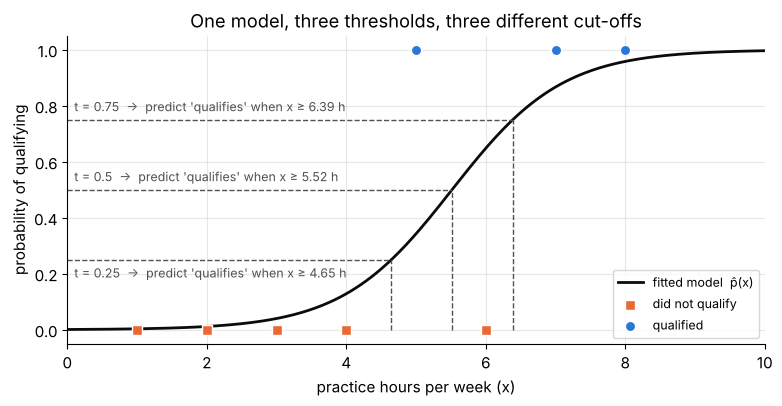

In [17]:
thresholds = [0.25, 0.5, 0.75]
rows = []
for t in thresholds:
    z_t = special.logit(t)
    cut = (z_t - b_fit) / w_fit
    y_pred = (x_toy >= cut).astype(int)
    rows.append({"threshold t": t, "logit(t)": z_t, "cut-off x*(t) [h]": cut,
                 "predicted labels S1..S8": "".join(map(str, y_pred)),
                 "false positives": int(np.sum((y_pred == 1) & (y_toy == 0))),
                 "false negatives": int(np.sum((y_pred == 0) & (y_toy == 1))),
                 "accuracy": np.mean(y_pred == y_toy)})
display(pd.DataFrame(rows).round(4))
print("true labels S1..S8      :", "".join(str(int(v)) for v in y_toy))

fig, ax = plt.subplots(figsize=(9, 4))
xg = np.linspace(0, 10, 400)
ax.plot(xg, sigmoid(w_fit * xg + b_fit), color=INK, lw=2, label="fitted model  p̂(x)")
for t, va in zip(thresholds, ["top", "bottom", "bottom"]):
    cut = (special.logit(t) - b_fit) / w_fit
    ax.plot([0, cut], [t, t], color=INK_SOFT, lw=1, ls="--")
    ax.plot([cut, cut], [0, t], color=INK_SOFT, lw=1, ls="--")
    ax.text(0.1, t + (0.02 if va == "bottom" else -0.02), f"t = {t}  →  predict 'qualifies' when x ≥ {cut:.2f} h",
            fontsize=9, color=INK_SOFT, va=va)
ax.scatter(x_toy[y_toy == 0], y_toy[y_toy == 0], marker="s", s=50, color=C_NEG, edgecolor="white", zorder=3, label="did not qualify")
ax.scatter(x_toy[y_toy == 1], y_toy[y_toy == 1], marker="o", s=55, color=C_POS, edgecolor="white", zorder=3, label="qualified")
ax.set(xlim=(0, 10), ylim=(-0.05, 1.05), xlabel="practice hours per week (x)", ylabel="probability of qualifying",
       title="One model, three thresholds, three different cut-offs")
ax.legend(loc="lower right", fontsize=9)
plt.show()

Raising the threshold moves the cut-off to the right (the model must be more confident before saying
"qualifies"). On these eight students, $t = 0.25$ makes one false positive (S6), $t = 0.75$ makes one false
negative (S5), and $t = 0.5$ makes one of each. With only eight students, do not read anything into the
accuracies. The point is that **the threshold decides which kind of mistake you make**.

**Choosing the threshold from costs.** Suppose a false negative (missing a positive) costs $C_{FN}$ and a false
positive costs $C_{FP}$. If the model's probability $\hat p$ is trustworthy, predicting 1 has expected cost
$(1 - \hat p)\,C_{FP}$, and predicting 0 has expected cost $\hat p\,C_{FN}$. Predict 1 exactly when that is cheaper:

$$
(1 - \hat p)\,C_{FP} \le \hat p\,C_{FN} \iff \hat p \ge \frac{C_{FP}}{C_{FP} + C_{FN}} = t^{*}.
$$

Equal costs give $t^* = 0.5$. In a medical screening test where missing a disease is 9 times worse than a false
alarm, $t^* = 1/(1 + 9) = 0.1$: flag anyone with at least a 10% chance. This argument only works if the
probabilities are **calibrated** (when the model says 10%, it is right about 10% of the time). Section 10.13 checks
this on real data.

**Quick check.** A model has logit $z = 2x - 3$. For which $x$ does it predict class 1 at threshold $t = 0.8$?

<details>
<summary>Answer</summary>

$\hat p \ge 0.8 \iff z \ge \operatorname{logit}(0.8) = \ln 4 \approx 1.386$, so $2x - 3 \ge 1.386$, i.e. $x \ge 2.193$.
(At $t = 0.5$ the cut-off would be $x \ge 1.5$.)
</details>

### 4.2 The geometry of the boundary in two dimensions

With two features $\mathbf{x} = (x_1, x_2)$ the score is $z = w_1x_1 + w_2x_2 + b = \mathbf{w}^\top\mathbf{x} + b$, and the
default boundary $\{\mathbf{x} : \mathbf{w}^\top\mathbf{x} + b = 0\}$ is a **straight line**. Three facts explain
everything about how logistic regression "sees" the plane.

**Fact 1: $\mathbf{w}$ is perpendicular (normal) to the boundary and points toward class 1.** If $\mathbf{a}$ and
$\mathbf{c}$ both lie on the boundary, subtracting $\mathbf{w}^\top\mathbf{a} + b = 0$ and $\mathbf{w}^\top\mathbf{c} + b = 0$
gives $\mathbf{w}^\top(\mathbf{a} - \mathbf{c}) = 0$: $\mathbf{w}$ is orthogonal to every direction along the line.
Moving from $\mathbf{x}$ to $\mathbf{x} + \varepsilon\mathbf{w}$ changes the score by $\varepsilon\lVert\mathbf{w}\rVert^2 > 0$, so
$\mathbf{w}$ points to the side where $z > 0$, the class-1 side.

**Fact 2: the score is a scaled signed distance.** The signed distance from $\mathbf{x}$ to the boundary is

$$
d(\mathbf{x}) = \frac{\mathbf{w}^\top\mathbf{x} + b}{\lVert\mathbf{w}\rVert}, \qquad\text{so}\qquad z = \lVert\mathbf{w}\rVert\, d(\mathbf{x})
\quad\text{and}\quad \hat p = \sigma\big(\lVert\mathbf{w}\rVert\, d(\mathbf{x})\big).
$$

*Proof.* Let $\mathbf{x}_\perp$ be the foot of the perpendicular from $\mathbf{x}$ onto the line, so
$\mathbf{x} = \mathbf{x}_\perp + d\,\mathbf{w}/\lVert\mathbf{w}\rVert$ for some number $d$ (its absolute value is the
distance, and its sign says which side). Since $\mathbf{w}^\top\mathbf{x}_\perp + b = 0$,
$\mathbf{w}^\top\mathbf{x} + b = d\,\mathbf{w}^\top\mathbf{w}/\lVert\mathbf{w}\rVert = d\,\lVert\mathbf{w}\rVert$. Dividing by $\lVert\mathbf{w}\rVert$
gives the formula.

**Fact 3: only the distance matters, and $\lVert\mathbf{w}\rVert$ is the "confidence knob".** Points at the same signed
distance get the same probability, so the level curves of $\hat p$ are lines parallel to the boundary. The size
$\lVert\mathbf{w}\rVert$ controls how fast the probability rises as you move away from the boundary. In particular,
multiplying $(\mathbf{w}, b)$ by any $c > 0$ leaves the boundary where it is but makes every prediction more extreme.
Section 8 shows how this innocent fact causes trouble.

Let us draw a concrete model, $\mathbf{w} = (1.5,\, 2.0)$ and $b = -1$, so $\lVert\mathbf{w}\rVert = 2.5$. We also scatter 200
synthetic points *generated from this very model* (we will try to recover it from the data in Section 7.6).
Think of $x_1$ and $x_2$ as two standardized measurements of a student, such as practice hours and a mock-contest score.

In [18]:
w_true2d, b_true2d = np.array([1.5, 2.0]), -1.0
rng_2d = np.random.default_rng(SEED)
X2d = rng_2d.normal(0.0, 1.0, size=(200, 2))                                  # 200 points, 2 features
y2d = (rng_2d.random(200) < sigmoid(X2d @ w_true2d + b_true2d)).astype(float)  # labels ~ Bernoulli(p_true)
print(f"synthetic 2-D data: X2d {X2d.shape}, {int(y2d.sum())} points in class 1")

pt_A = np.array([2.0, 1.0])
z_A = pt_A @ w_true2d + b_true2d
d_A = z_A / np.linalg.norm(w_true2d)
foot_A = pt_A - d_A * w_true2d / np.linalg.norm(w_true2d)
print(f"point A = {pt_A}: z = {z_A:.2f}, signed distance d = {d_A:.2f}, p_hat = {sigmoid(z_A):.4f}, "
      f"foot of perpendicular = {foot_A.round(2)}")
print(f"origin  : z = {b_true2d:.2f}, signed distance d = {b_true2d / np.linalg.norm(w_true2d):.2f}, p_hat = {sigmoid(b_true2d):.4f}")

synthetic 2-D data: X2d (200, 2), 74 points in class 1


point A = [2. 1.]: z = 4.00, signed distance d = 1.60, p_hat = 0.9820, foot of perpendicular = [ 1.04 -0.28]
origin  : z = -1.00, signed distance d = -0.40, p_hat = 0.2689


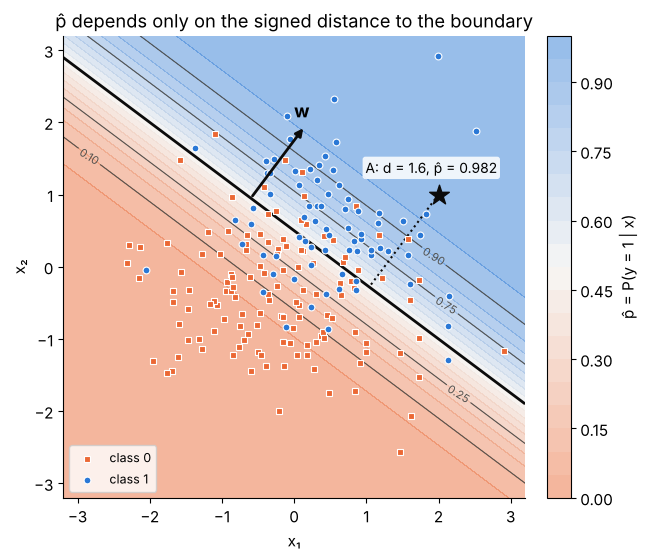

In [19]:
def plot_prob_surface(ax, w, b, lim=3.2, levels=(0.1, 0.25, 0.75, 0.9), show_colorbar=False, alpha=0.85,
                      label_levels=True):
    """Shade p_hat = sigmoid(w.x + b) over a square, draw the boundary (p=0.5) and a few level lines."""
    g = np.linspace(-lim, lim, 300)
    G1, G2 = np.meshgrid(g, g)
    P = sigmoid(w[0] * G1 + w[1] * G2 + b)
    im = ax.contourf(G1, G2, P, levels=np.linspace(0, 1, 21), cmap=PROB_CMAP, alpha=alpha)
    cs = ax.contour(G1, G2, P, levels=list(levels), colors=INK_SOFT, linewidths=0.8)
    if label_levels:
        ax.clabel(cs, fmt="%.2f", fontsize=8)
    ax.contour(G1, G2, P, levels=[0.5], colors=INK, linewidths=2)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal", xlabel="x₁", ylabel="x₂")
    ax.grid(False)
    if show_colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="p̂ = P(y = 1 | x)")
    return im


fig, ax = plt.subplots(figsize=(7.2, 6))
plot_prob_surface(ax, w_true2d, b_true2d, show_colorbar=True, alpha=0.5)
scatter_classes(ax, X2d, y2d, labels=("class 0", "class 1"), s=24)
start = np.array([-0.6, 0.95])                     # a point on the boundary: 1.5(-0.6) + 2(0.95) - 1 = 0
ax.annotate("", xy=start + 0.5 * w_true2d, xytext=start, arrowprops=dict(arrowstyle="-|>", color=INK, lw=2))
ax.text(*(start + 0.5 * w_true2d + np.array([-0.15, 0.12])), "w", fontsize=13, fontweight="bold")
ax.plot(*zip(pt_A, foot_A), color=INK, lw=1.5, ls=":")
ax.scatter(*pt_A, marker="*", s=220, color=INK, zorder=4)
ax.text(pt_A[0] - 0.1, pt_A[1] + 0.3, f"A: d = {d_A:.1f}, p̂ = {sigmoid(z_A):.3f}", fontsize=10, ha="center",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.85))
ax.set_title("p̂ depends only on the signed distance to the boundary")
ax.legend(loc="lower left", fontsize=9)
plt.show()

Point $A = (2, 1)$ has score $z = 1.5\cdot 2 + 2\cdot 1 - 1 = 4$ and lies at signed distance $d = 4/2.5 = 1.6$ on
the class-1 side, so $\hat p = \sigma(4) = 0.982$. The origin has $z = -1$, so it lies at distance $0.4$ on the
class-0 side with $\hat p = \sigma(-1) = 0.2689$. The thin labelled lines (0.10, 0.25, 0.75, 0.90) are parallel
to the bold boundary, exactly as Fact 3 predicts. Notice also that the synthetic labels are *noisy*: some blue
circles sit on the orange side and vice versa, because the labels were drawn at random from the model's
probabilities.

Now the confidence knob: the same boundary with $(\mathbf{w}, b)$ multiplied by $c = 0.5$, $1$ and $4$.

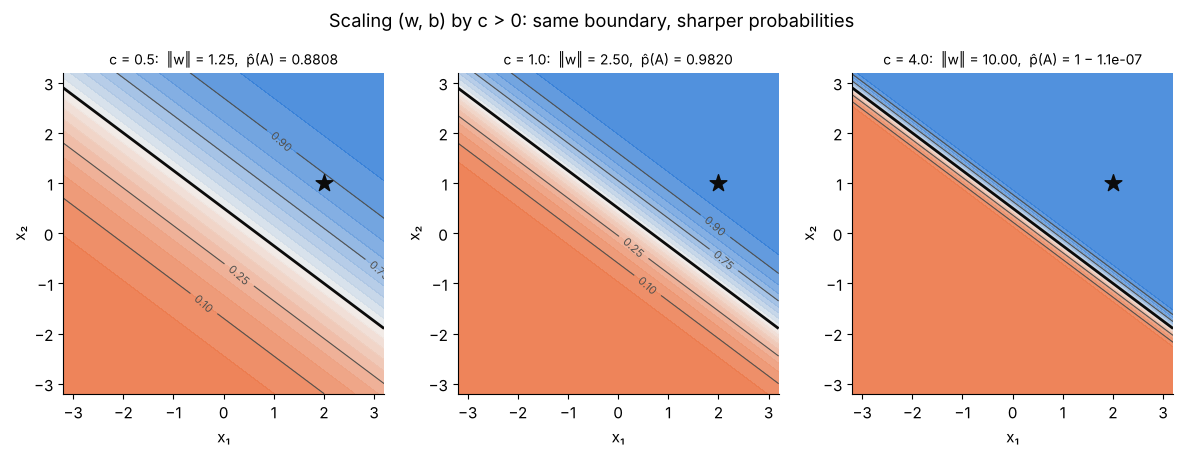

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, c in zip(axes, [0.5, 1.0, 4.0]):
    plot_prob_surface(ax, c * w_true2d, c * b_true2d, label_levels=(c < 2))
    ax.scatter(*pt_A, marker="*", s=160, color=INK, zorder=4)
    p_A = sigmoid(c * z_A)
    p_txt = f"{p_A:.4f}" if p_A < 0.9999 else f"1 − {1 - p_A:.1e}"     # avoid printing 0.99999989 as "1.0000"
    ax.set_title(f"c = {c}:  ‖w‖ = {c * np.linalg.norm(w_true2d):.2f},  p̂(A) = {p_txt}", fontsize=10)
fig.suptitle("Scaling (w, b) by c > 0: same boundary, sharper probabilities", y=1.02)
plt.tight_layout()
plt.show()

In $d$ dimensions nothing changes: the boundary $\mathbf{w}^\top\mathbf{x} + b = 0$ is a hyperplane with normal vector
$\mathbf{w}$, and $\hat p$ depends only on the signed distance to it. That is why logistic regression is called a
**linear classifier**. It can still draw *curved* boundaries in the original inputs if we feed it transformed
features such as $x_1^2$ or $x_1x_2$ (Section 7.7). Stacking many logistic units, each with its own linear
boundary, is the idea behind neural networks.

In [21]:
# ✏️ Exercise 3: signed distance to the decision boundary
def signed_distance(X, w, b):
    """X: (m, d) array of points, w: (d,) weights, b: bias.
    Return the (m,) array of signed distances (w.x + b)/||w|| to the hyperplane w.x + b = 0
    (positive on the side that w points to)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    w, b = np.array([1.5, 2.0]), -1.0
    out = signed_distance(np.array([[2.0, 1.0], [0.0, 0.0], [-0.6, 0.95]]), w, b)
    assert out.shape == (3,), f"expected shape (3,), got {np.shape(out)}"
    assert np.allclose(out, [1.6, -0.4, 0.0]), f"got {out}"
    X = np.random.default_rng(0).normal(size=(50, 4))
    w4, b4 = np.array([0.3, -1.0, 2.0, 0.5]), 0.7
    d = signed_distance(X, w4, b4)
    assert np.allclose(signed_distance(X, 7 * w4, 7 * b4), d), "scaling (w, b) by c > 0 must not change distances"
    feet = X - d[:, None] * w4 / np.linalg.norm(w4)                      # project onto the hyperplane
    assert np.allclose(feet @ w4 + b4, 0), "moving each point by -d along the unit normal must land on the plane"

run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def signed_distance(X, w, b):
    X, w = np.asarray(X, dtype=float), np.asarray(w, dtype=float)
    return (X @ w + b) / np.linalg.norm(w)
```
`X @ w` computes all $m$ scores at once, and dividing by $\lVert\mathbf{w}\rVert$ turns scores into distances (Fact 2).
</details>

**Quick check.** What happens to the boundary and to the predicted probabilities if you multiply both $\mathbf{w}$ and
$b$ by $-1$?

<details>
<summary>Answer</summary>

The boundary $\mathbf{w}^\top\mathbf{x} + b = 0$ is the same set of points, but every score changes sign, so every
probability becomes $\sigma(-z) = 1 - \hat p$: the model now predicts the *opposite* class everywhere. The normal
vector flips to point at the other side.
</details>

## 5. Choosing a loss: why not MSE, and where cross-entropy comes from

We have a model, $\hat p_i = \sigma(z_i)$ with $z_i = wx_i + b$. To *train* it we need a single number, the
**loss**, that measures how badly the predictions match the labels, so that gradient descent can push it down.

### 5.1 Why not mean squared error?

The obvious first idea is the loss from linear regression:

$$
\mathcal{L}_{\text{MSE}}(w, b) = \frac{1}{m}\sum_{i=1}^{m}\big(\hat p_i - y_i\big)^2 = \frac{1}{m}\sum_{i=1}^{m}\big(\sigma(wx_i + b) - y_i\big)^2 .
$$

It is not crazy (it is even used sometimes, under the name *Brier score*, to *evaluate* probabilities), but as a
*training* loss for logistic regression it has two serious defects.

**Defect 1: vanishing gradients when the model is confidently wrong.** Look at one example with $y = 1$ and
differentiate with respect to the logit $z$, using $\sigma' = \sigma(1-\sigma)$:

$$
\frac{d}{dz}\big(\sigma(z) - 1\big)^2 = 2\big(\sigma(z) - 1\big)\,\sigma(z)\big(1 - \sigma(z)\big) = -2\,\sigma(z)\big(1-\sigma(z)\big)^2 .
$$

If the model is *confidently wrong* ($z \ll 0$, so $\sigma(z) \approx 0$), the factor $\sigma(z)$ makes this
derivative almost zero: the example that most needs fixing barely contributes to the update. The loss we
will derive below (binary cross-entropy) has derivative $\sigma(z) - 1 \approx -1$ in the same situation.

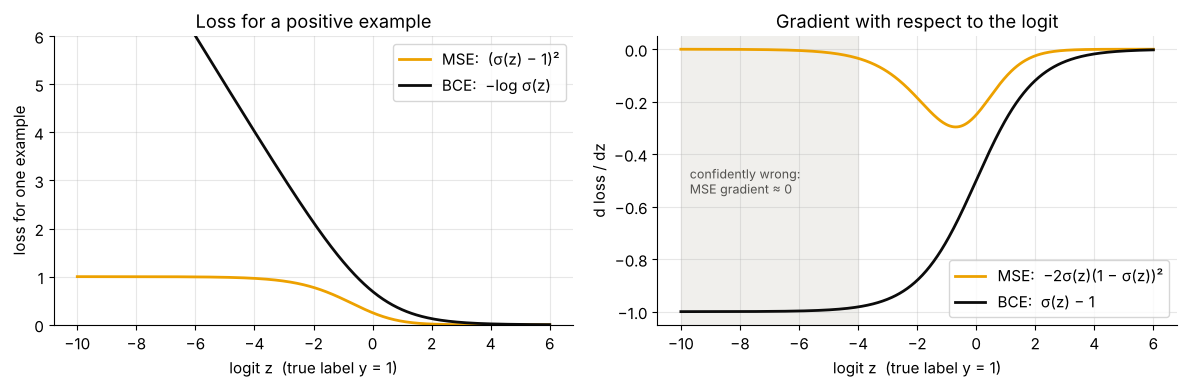

,p_hat,MSE loss,MSE dL/dz,BCE loss,BCE dL/dz
z,,,,,
-10.0,4.54e-05,1,-9.08e-05,10,-1
-5.0,0.00669,0.987,-0.0132,5.01,-0.993
-2.0,0.119,0.776,-0.185,2.13,-0.881
0.0,0.5,0.25,-0.25,0.693,-0.5
2.0,0.881,0.0142,-0.025,0.127,-0.119


In [22]:
z_line = np.linspace(-10, 6, 500)
s_line = sigmoid(z_line)
mse_loss_y1 = (s_line - 1) ** 2
mse_grad_y1 = -2 * s_line * (1 - s_line) ** 2
bce_loss_y1 = np.logaddexp(0, -z_line)          # -log(sigmoid(z)), computed stably
bce_grad_y1 = s_line - 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(z_line, mse_loss_y1, color=PALETTE[3], lw=2, label="MSE:  (σ(z) − 1)²")
axes[0].plot(z_line, bce_loss_y1, color=INK, lw=2, label="BCE:  −log σ(z)")
axes[0].set(ylim=(0, 6), xlabel="logit z  (true label y = 1)", ylabel="loss for one example", title="Loss for a positive example")
axes[0].legend()
axes[1].plot(z_line, mse_grad_y1, color=PALETTE[3], lw=2, label="MSE:  −2σ(z)(1 − σ(z))²")
axes[1].plot(z_line, bce_grad_y1, color=INK, lw=2, label="BCE:  σ(z) − 1")
axes[1].axvspan(-10, -4, color="#f0efec", zorder=0)
axes[1].text(-9.7, -0.55, "confidently wrong:\nMSE gradient ≈ 0", fontsize=9, color=INK_SOFT)
axes[1].set(xlabel="logit z  (true label y = 1)", ylabel="d loss / dz", title="Gradient with respect to the logit")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

rows = []
for zz in [-10.0, -5.0, -2.0, 0.0, 2.0]:
    s_ = sigmoid(zz)
    vals = {"p_hat": s_, "MSE loss": (s_ - 1) ** 2, "MSE dL/dz": -2 * s_ * (1 - s_) ** 2,
            "BCE loss": np.logaddexp(0, -zz), "BCE dL/dz": s_ - 1}
    rows.append({"z": zz, **{k: f"{v:.3g}" for k, v in vals.items()}})   # 3 significant digits
display(pd.DataFrame(rows).set_index("z"))

At $z = -10$ the model gives the true class a probability of $0.0000454$. MSE's loss is capped at about 1 and its
gradient is $-9.08\times 10^{-5}$. Cross-entropy's loss is about 10 and its gradient is $-1$, more than ten thousand
times stronger. The left panel also shows **Defect 2** in miniature: the MSE curve is bounded and S-shaped, and a
bounded function that is not constant can never be convex. Convexity is worth a short detour.

**Convex functions.** A function $f$ is **convex** if the chord between any two points of its graph lies on or
above the graph:

$$
f\big(\lambda \mathbf{a} + (1-\lambda)\mathbf{c}\big) \;\le\; \lambda f(\mathbf{a}) + (1-\lambda) f(\mathbf{c})\qquad\text{for all } \mathbf{a}, \mathbf{c} \text{ and } \lambda\in[0,1].
$$

For a twice-differentiable function of one variable this is equivalent to $f'' \ge 0$ everywhere, and for several
variables, to the Hessian matrix being positive semidefinite everywhere. Picture gradient descent as a ball
rolling downhill. On a convex loss the landscape is a single bowl: every local minimum is a global minimum, so
wherever the ball starts it ends up at the bottom. On a non-convex loss the landscape can have several valleys,
and the ball may settle in a poor one.

**Defect 2: MSE with a sigmoid is not convex, and can trap gradient descent.** Here is a concrete case. Twelve
students. Two newcomers practised very little (0.5 and 1 hour) but qualified anyway (perhaps thanks to earlier
training). We run plain gradient descent on both losses, from two different starting points.

In [23]:
x12 = np.array([0.5, 0.5, 1.0, 1.0, 1.5, 2.0, 3.0, 6.0, 6.5, 7.0, 9.0, 10.0])
y12 = np.array([1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1], dtype=float)


def mse_loss_wb(w, b, x, y):
    """Mean squared error of sigmoid(w x + b) against y. The arguments w and b may be arrays of the same shape (a grid)."""
    P = sigmoid(np.multiply.outer(w, x) + np.expand_dims(b, -1))
    return np.mean((P - y) ** 2, axis=-1)


def bce_loss_wb(w, b, x, y):
    """Binary cross-entropy of sigmoid(w x + b) against y, in the stable logit form (Section 5.4)."""
    Z = np.multiply.outer(w, x) + np.expand_dims(b, -1)
    return np.mean(np.logaddexp(0, Z) - y * Z, axis=-1)


def grad_wb(w, b, x, y, kind):
    """Gradient (dL/dw, dL/db) of the MSE or BCE loss for a 1-feature logistic model."""
    p = sigmoid(w * x + b)
    g = 2 * (p - y) * p * (1 - p) if kind == "mse" else (p - y)    # dL_i/dz_i
    return np.array([np.mean(g * x), np.mean(g)])


def run_gd_wb(theta0, x, y, kind, lr, steps):
    """Plain gradient descent on (w, b). Returns the whole path, shape (steps + 1, 2)."""
    path = [np.array(theta0, dtype=float)]
    for _ in range(steps):
        path.append(path[-1] - lr * grad_wb(*path[-1], x, y, kind))
    return np.array(path)


starts = {"start 1: (w, b) = (0, 0)": (0.0, 0.0), "start 2: (w, b) = (−1, 1)": (-1.0, 1.0)}
paths = {}
for kind, lr in [("mse", 1.0), ("bce", 0.2)]:
    for name, th0 in starts.items():
        P = run_gd_wb(th0, x12, y12, kind, lr, 3000)
        paths[(kind, name)] = P
        loss_fn = mse_loss_wb if kind == "mse" else bce_loss_wb
        w_end, b_end = P[-1]
        print(f"{kind.upper()} | {name}: ends at w = {w_end:+.3f}, b = {b_end:+.3f}, "
              f"loss = {loss_fn(w_end, b_end, x12, y12):.4f}, |gradient| = {np.linalg.norm(grad_wb(w_end, b_end, x12, y12, kind)):.1e}")

MSE | start 1: (w, b) = (0, 0): ends at w = +0.500, b = -1.602, loss = 0.1521, |gradient| = 1.0e-16
MSE | start 2: (w, b) = (−1, 1): ends at w = -1.844, b = +1.226, loss = 0.5078, |gradient| = 2.1e-08
BCE | start 1: (w, b) = (0, 0): ends at w = +0.571, b = -1.494, loss = 0.4539, |gradient| = 5.7e-16


BCE | start 2: (w, b) = (−1, 1): ends at w = +0.571, b = -1.494, loss = 0.4539, |gradient| = 5.7e-16


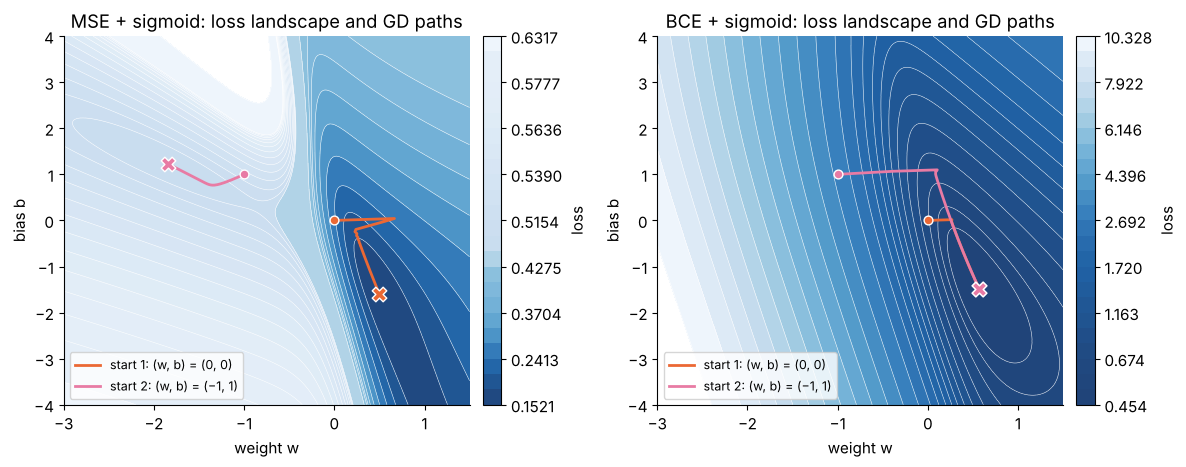

In [24]:
W, B = np.meshgrid(np.linspace(-3, 1.5, 220), np.linspace(-4, 4, 220))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, kind, loss_fn in [(axes[0], "mse", mse_loss_wb), (axes[1], "bce", bce_loss_wb)]:
    Lgrid = loss_fn(W, B, x12, y12)
    levels = np.quantile(Lgrid, np.linspace(0.0, 0.97, 25))
    cf = ax.contourf(W, B, Lgrid, levels=levels, cmap="Blues_r", alpha=0.9)
    ax.contour(W, B, Lgrid, levels=levels, colors="white", linewidths=0.4)
    for (k, name), P in paths.items():
        if k != kind:
            continue
        color = PALETTE[1] if name.startswith("start 1") else PALETTE[4]
        ax.plot(P[:, 0], P[:, 1], color=color, lw=2, label=name)
        ax.scatter(*P[0], color=color, s=40, edgecolor="white", zorder=4)
        ax.scatter(*P[-1], color=color, marker="X", s=110, edgecolor="white", zorder=5)
    ax.set(xlabel="weight w", ylabel="bias b", title=f"{kind.upper()} + sigmoid: loss landscape and GD paths")
    ax.grid(False)
    ax.legend(loc="lower left", fontsize=9)
    plt.colorbar(cf, ax=ax, fraction=0.046, pad=0.03, label="loss")
plt.tight_layout()
plt.show()

With MSE, the two runs end in **different valleys**. From $(0, 0)$, gradient descent reaches a sensible model
($w \approx 0.500$, loss $0.1521$). From $(-1, 1)$ it settles at $w \approx -1.844$, $b \approx 1.226$: a model claiming that
*more practice lowers the chance of qualifying*, with a loss of $0.5078$, worse even than always predicting $0.5$
(which scores $0.25$). The gradient there is essentially zero, so gradient descent has no reason to move.
Both defects are at work: at that point the five students with 6+ hours are predicted to fail with near
certainty, their MSE gradients have vanished, and the remaining students hold the model in place.

With cross-entropy, both runs reach the same point ($w \approx 0.571$, $b \approx -1.494$). A tidy way to *see* convexity
is to walk along the straight segment between the two MSE end points and plot each loss along the way. A convex
function restricted to a line is a convex function of one variable, so it can only have a single dip.

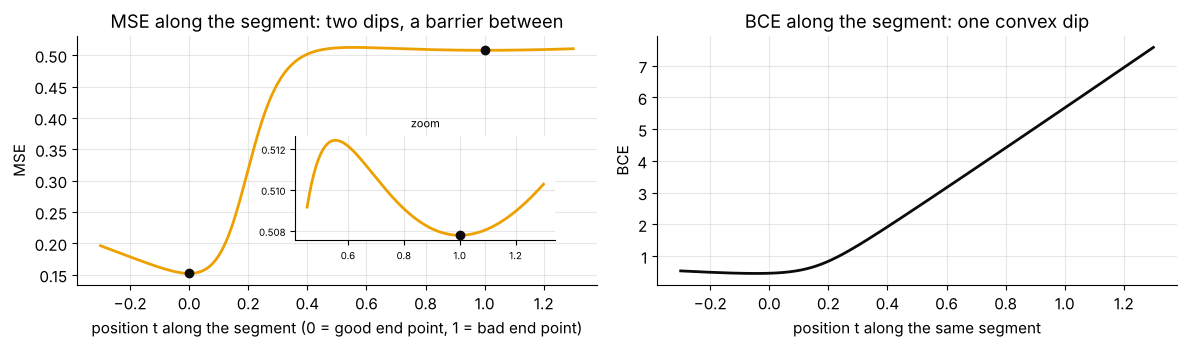

In [25]:
th_good, th_bad = paths[("mse", "start 1: (w, b) = (0, 0)")][-1], paths[("mse", "start 2: (w, b) = (−1, 1)")][-1]
tt = np.linspace(-0.3, 1.3, 400)
seg = (1 - tt)[:, None] * th_good + tt[:, None] * th_bad          # points on the line through both minima

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(tt, mse_loss_wb(seg[:, 0], seg[:, 1], x12, y12), color=PALETTE[3], lw=2)
axes[0].scatter([0, 1], mse_loss_wb(np.array([th_good[0], th_bad[0]]), np.array([th_good[1], th_bad[1]]), x12, y12),
                color=INK, zorder=3)
axes[0].set(xlabel="position t along the segment (0 = good end point, 1 = bad end point)", ylabel="MSE",
            title="MSE along the segment: two dips, a barrier between")
zoom = axes[0].inset_axes([0.42, 0.18, 0.5, 0.42])          # magnify the shallow second dip
t_zoom = tt[tt >= 0.45]
zoom.plot(t_zoom, mse_loss_wb(seg[tt >= 0.45, 0], seg[tt >= 0.45, 1], x12, y12), color=PALETTE[3], lw=2)
zoom.scatter([1], [mse_loss_wb(th_bad[0], th_bad[1], x12, y12)], color=INK, zorder=3)
zoom.set_title("zoom", fontsize=8)
zoom.tick_params(labelsize=7)
axes[1].plot(tt, bce_loss_wb(seg[:, 0], seg[:, 1], x12, y12), color=INK, lw=2)
axes[1].set(xlabel="position t along the same segment", ylabel="BCE", title="BCE along the segment: one convex dip")
plt.tight_layout()
plt.show()

> **Key idea.** Squared error plus a sigmoid gives a loss that can be flat exactly where the model is most wrong
> and that can have spurious valleys. We want a loss that (a) punishes confident mistakes hard, (b) has a gradient
> that does not vanish for them, and (c) is convex in the parameters. Maximum likelihood delivers all three.

### 5.2 Maximum likelihood: where cross-entropy comes from

Section 1.4 modelled each label as a biased coin: $y_i \sim \text{Bernoulli}(\hat p_i)$ with $\hat p_i = \sigma(wx_i + b)$.
For given parameters, the probability that the model assigns to the label we *actually observed* is
$\hat p_i^{\,y_i}(1-\hat p_i)^{1-y_i}$: that is $\hat p_i$ if $y_i = 1$ and $1 - \hat p_i$ if $y_i = 0$. Assuming the examples are
independent, the probability of the whole set of observed labels is the product, called the **likelihood**:

$$
L(w, b) = \prod_{i=1}^{m} \hat p_i^{\,y_i}\,(1 - \hat p_i)^{1 - y_i}.
$$

The **principle of maximum likelihood**: choose the parameters that make the observed data most probable. A
good model gives high probability to what actually happened. Let us compare two candidate models on the
8 students.

In [26]:
def likelihood_table(w, b, x, y):
    """Per-example probability that the model (w, b) assigns to the observed label."""
    p_hat = sigmoid(w * x + b)
    prob_obs = np.where(y == 1, p_hat, 1 - p_hat)
    return p_hat, prob_obs


cands = {"model A: w = 1.25, b = −7": (1.25, -7.0), "model B: w = 0.5, b = −2": (0.5, -2.0)}
tab = pd.DataFrame({"x": x_toy.astype(int), "y": y_toy.astype(int)})
for name, (w_c, b_c) in cands.items():
    p_hat, prob_obs = likelihood_table(w_c, b_c, x_toy, y_toy)
    tab[f"p_hat ({name[:7]})"] = p_hat
    tab[f"P(observed y) ({name[:7]})"] = prob_obs
display(tab.round(4).set_index("x"))
for name, (w_c, b_c) in cands.items():
    _, prob_obs = likelihood_table(w_c, b_c, x_toy, y_toy)
    print(f"{name}:  likelihood = {np.prod(prob_obs):.6f},  log-likelihood = {np.sum(np.log(prob_obs)):.4f},  "
          f"mean negative log-likelihood = {-np.mean(np.log(prob_obs)):.4f}")

,y,p_hat (model A),P(observed y) (model A),p_hat (model B),P(observed y) (model B)
x,,,,,
1,0,0.0032,0.9968,0.1824,0.8176
2,0,0.0110,0.9890,0.2689,0.7311
3,0,0.0373,0.9627,0.3775,0.6225
4,0,0.1192,0.8808,0.5000,0.5000
5,1,0.3208,0.3208,0.6225,0.6225
6,0,0.6225,0.3775,0.7311,0.2689
7,1,0.8520,0.8520,0.8176,0.8176
8,1,0.9526,0.9526,0.8808,0.8808


model A: w = 1.25, b = −7:  likelihood = 0.082171,  log-likelihood = -2.4990,  mean negative log-likelihood = 0.3124
model B: w = 0.5, b = −2:  likelihood = 0.022425,  log-likelihood = -3.7976,  mean negative log-likelihood = 0.4747


Model A assigns the observed labels a joint probability about 3.7 times larger than model B does
($0.0822$ versus $0.0224$), so maximum likelihood prefers A. Look at where B loses: it is too timid about the
students with few hours (it gives S1 only $0.8176$ for the label it should be sure about), while A pays mainly for
the two "surprising" students S5 and S6. Notice how small these numbers already are with
only 8 examples. That leads to the next step.

**Take logarithms.** Instead of maximizing $L$ we maximize $\log L$. This changes nothing about the *location* of
the maximum ($\log$ is strictly increasing), and it helps in three ways:

1. **Products become sums:** $\log L = \sum_i \big[\,y_i\log\hat p_i + (1 - y_i)\log(1 - \hat p_i)\,\big]$. Sums are easy to
   differentiate term by term, and to split into mini-batches.
2. **No underflow.** A product of thousands of numbers below 1 underflows: it collapses to 0 or gets stuck at a
   meaningless tiny number (see below).
   The sum of logs is a perfectly ordinary number.
3. **Averaging** (dividing by $m$) makes the value comparable across dataset sizes, so learning rates do not have
   to change when the dataset grows.

Finally, flip the sign so that we have something to *minimize*. The result is the **binary cross-entropy**
(BCE), also called **log loss** or the negative log-likelihood:

$$
\boxed{\;\mathcal{L}(w, b) = -\frac{1}{m}\sum_{i=1}^{m}\Big[\,y_i\log\hat p_i + (1 - y_i)\log(1 - \hat p_i)\,\Big]\;}
$$

Minimizing BCE *is* maximum likelihood. For the toy models above, BCE equals the "mean negative log-likelihood"
printed in the last column: $0.3124$ for A versus $0.4747$ for B.

In [27]:
for m_ex in [10, 100, 1000, 2000, 3000]:
    probs = np.full(m_ex, 0.7)                 # pretend each observed label gets probability 0.7
    log_lik = np.sum(np.log(probs))
    print(f"m = {m_ex:>4}: product = {np.prod(probs):.3e}   sum of logs = {log_lik:10.3f}   "
          f"true product = 10^{log_lik / np.log(10):.1f}")

m =   10: product = 2.825e-02   sum of logs =     -3.567   true product = 10^-1.5
m =  100: product = 3.234e-16   sum of logs =    -35.667   true product = 10^-15.5
m = 1000: product = 1.253e-155   sum of logs =   -356.675   true product = 10^-154.9
m = 2000: product = 1.571e-310   sum of logs =   -713.350   true product = 10^-309.8
m = 3000: product = 4.941e-324   sum of logs =  -1070.025   true product = 10^-464.7


Up to 1000 examples the product is tiny but correct. At 2000 it has entered the "subnormal" range of float64, where
only a few significant digits survive. At 3000 it is stuck at $4.9\times10^{-324}$, the smallest positive float64,
while the true value is about $10^{-464.7}$: the computer silently returns a meaningless number, and two different
models could no longer be compared. The sum of logs has no such problem.

### 5.3 Reading the loss: a case analysis

The formula looks heavy, but for each example only one of the two terms survives, because $y_i$ is either 0 or 1:

$$
\ell(\hat p, y) = -\big[y\log\hat p + (1-y)\log(1-\hat p)\big] =
\begin{cases} -\log \hat p, & y = 1,\\ -\log(1 - \hat p), & y = 0.\end{cases}
$$

* **If $y = 1$**, the loss is $-\log\hat p$: zero when $\hat p = 1$, and growing without bound as $\hat p \to 0$.
* **If $y = 0$**, the loss is $-\log(1-\hat p)$: zero when $\hat p = 0$, and growing without bound as $\hat p \to 1$.

In words: **the loss is minus the log of the probability the model gave to the truth.** Being right with
confidence is almost free, and being wrong with confidence is very expensive.

p_hat,0.99,0.90,0.70,0.50,0.30,0.10,0.01
BCE if y = 1,0.0101,0.1054,0.3567,0.6931,1.2040,2.3026,4.6052
BCE if y = 0,4.6052,2.3026,1.2040,0.6931,0.3567,0.1054,0.0101
MSE if y = 1,0.0001,0.0100,0.0900,0.2500,0.4900,0.8100,0.9801
MSE if y = 0,0.9801,0.8100,0.4900,0.2500,0.0900,0.0100,0.0001


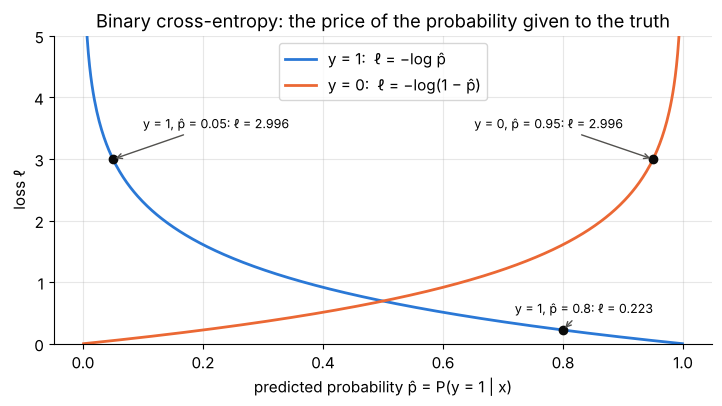

In [28]:
p_tab = np.array([0.99, 0.9, 0.7, 0.5, 0.3, 0.1, 0.01])
display(pd.DataFrame({"p_hat": p_tab,
                      "BCE if y = 1": -np.log(p_tab), "BCE if y = 0": -np.log(1 - p_tab),
                      "MSE if y = 1": (p_tab - 1) ** 2, "MSE if y = 0": p_tab ** 2}).round(4).set_index("p_hat").T)

p_line = np.linspace(0.001, 0.999, 500)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(p_line, -np.log(p_line), color=C_POS, lw=2, label="y = 1:  ℓ = −log p̂")
ax.plot(p_line, -np.log(1 - p_line), color=C_NEG, lw=2, label="y = 0:  ℓ = −log(1 − p̂)")
for p_pt, y_pt, txt_xy, ha in [(0.05, 1, (0.10, 3.5), "left"), (0.8, 1, (0.95, 0.5), "right"), (0.95, 0, (0.90, 3.5), "right")]:
    l_pt = -np.log(p_pt) if y_pt == 1 else -np.log(1 - p_pt)
    ax.scatter(p_pt, l_pt, color=INK, zorder=3)
    ax.annotate(f"y = {y_pt}, p̂ = {p_pt}: ℓ = {l_pt:.3f}", (p_pt, l_pt), xytext=txt_xy, ha=ha,
                fontsize=9, arrowprops=dict(arrowstyle="->", color=INK_SOFT))
ax.set(ylim=(0, 5), xlabel="predicted probability p̂ = P(y = 1 | x)", ylabel="loss ℓ",
       title="Binary cross-entropy: the price of the probability given to the truth")
ax.legend(loc="upper center")
plt.show()

Compare the rows of the table: for a positive example predicted at $\hat p = 0.01$, BCE charges $4.6052$ while MSE
charges only $0.9801$. And MSE barely distinguishes "wrong" from "very wrong": $0.81$ at $\hat p = 0.1$ versus $0.9801$ at
$\hat p = 0.01$, while BCE doubles from $2.3026$ to $4.6052$.

Two more facts connect this loss to the rest of the course:

* **It is a cross-entropy.** Treat the label as a distribution $q = (y,\, 1-y)$ over the two classes and the
  prediction as $(\hat p,\, 1 - \hat p)$. Then $\ell(\hat p, y) = -\sum_{k} q_k\log(\text{predicted}_k) = H(q, \hat p)$, the
  cross-entropy from Notebook 07. Since $H(q,\hat p) = H(q) + D_{\mathrm{KL}}(q\,\Vert\,\hat p)$ and a hard label has $H(q) = 0$,
  minimizing BCE is minimizing the KL divergence between truth and prediction.
* **It rewards honesty.** If an outcome truly has probability $q$, the expected loss of predicting $p$ is
  $-q\log p - (1-q)\log(1-p)$. Its derivative $-q/p + (1-q)/(1-p)$ vanishes exactly at $p = q$, and the function is
  convex in $p$, so the best prediction is the true probability. A loss with this property is called a **proper
  scoring rule**: the model cannot lower its expected loss by exaggerating or hedging.

### 5.4 The loss in terms of the logit (and how to compute it safely)

In code we never compute $\hat p$ and then take its logarithm (Section 3.4 showed why: $1 - \sigma(40)$ rounds to 0).
Instead we rewrite the loss as a function of the logit $z$. Using $\log\sigma(z) = -\operatorname{softplus}(-z)$ and
$\log(1 - \sigma(z)) = \log\sigma(-z) = -\operatorname{softplus}(z)$:

$$
\ell(z, y) = y\,\operatorname{softplus}(-z) + (1 - y)\,\operatorname{softplus}(z).
$$

One more identity simplifies this: $\operatorname{softplus}(z) - \operatorname{softplus}(-z) = \log\dfrac{1 + e^{z}}{1 + e^{-z}} = \log e^{z} = z$. Substituting
$\operatorname{softplus}(-z) = \operatorname{softplus}(z) - z$ gives the compact form

$$
\boxed{\;\ell(z, y) = \operatorname{softplus}(z) - y\,z = \log\big(1 + e^{z}\big) - y\,z\;}
$$

which `np.logaddexp(0, z) - y * z` evaluates without overflow for any $z$. Its derivative is
$\ell'(z) = \sigma(z) - y$ (because $\frac{d}{dz}\log(1+e^z) = \frac{e^z}{1+e^z} = \sigma(z)$), a fact we will use constantly.
This is exactly how deep-learning libraries implement "BCE with logits". Compare three implementations on some
extreme cases:

In [29]:
def bce_naive(z, y):
    """Textbook formula on probabilities: overflows/NaNs for extreme logits."""
    p = sigmoid(z)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))


def bce_clipped(z, y, eps=1e-7):
    """Common patch: clip probabilities into [eps, 1 - eps] before taking logs."""
    p = np.clip(sigmoid(z), eps, 1 - eps)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))


def bce_logits(z, y):
    """Stable per-example BCE written in terms of the logit: softplus(z) - y z."""
    return np.logaddexp(0.0, z) - y * z


z_cases = np.array([40.0, -800.0, 3.0, -3.0])
y_cases = np.array([0.0, 1.0, 1.0, 1.0])
with np.errstate(divide="ignore", invalid="ignore"):
    comp = pd.DataFrame({"z": z_cases, "y": y_cases, "naive": bce_naive(z_cases, y_cases),
                         "clipped (eps=1e-7)": bce_clipped(z_cases, y_cases), "stable (logits)": bce_logits(z_cases, y_cases)})
display(comp.round(4))
t_z, t_y = torch.tensor(z_cases), torch.tensor(y_cases)
print("torch BCE-with-logits      :", torch.nn.functional.binary_cross_entropy_with_logits(t_z, t_y, reduction="none").numpy().round(4))
print("torch BCE on probabilities :", torch.nn.functional.binary_cross_entropy(torch.sigmoid(t_z), t_y, reduction="none").numpy().round(4))

,z,y,naive,clipped (eps=1e-7),stable (logits)
0,40.0,0.0,inf,16.1181,40.0000
1,-800.0,1.0,inf,16.1181,800.0000
2,3.0,1.0,0.0486,0.0486,0.0486
3,-3.0,1.0,3.0486,3.0486,3.0486


torch BCE-with-logits      : [4.0000e+01 8.0000e+02 4.8600e-02 3.0486e+00]
torch BCE on probabilities : [1.0000e+02 1.0000e+02 4.8600e-02 3.0486e+00]


For $z = 40,\ y = 0$ the true loss is $\log(1 + e^{40}) \approx 40$. The naive formula returns `inf`, and clipping returns
$16.1181 = -\log(10^{-7})$, a silently wrong number, and worse, beyond the clip the loss is *flat*, so its gradient is
zero. PyTorch's probability-based BCE clamps logarithms at $-100$ (hence its $100$ in both extreme cases). Only the logit form
gets every case right, and it matches PyTorch's `binary_cross_entropy_with_logits` exactly.

> **Common pitfall.** If your model ends with a sigmoid and you then call a "BCE on probabilities" function, you
> lose precision for confident predictions. In PyTorch, leave out the final sigmoid and use
> `BCEWithLogitsLoss`. Apply the sigmoid only when you need probabilities for reporting.

In [30]:
# ✏️ Exercise 4: the average BCE loss from logits, stable for any z
def bce_from_logits(z, y):
    """z: (m,) logits, y: (m,) labels in {0, 1}. Return the MEAN binary cross-entropy as a Python float,
    using the stable form softplus(z) - y z (no overflow, no clipping)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert np.isclose(bce_from_logits(np.zeros(4), np.array([0, 1, 0, 1.0])), np.log(2)), "z = 0 everywhere -> log 2"
    assert np.isclose(bce_from_logits(np.array([40.0]), np.array([0.0])), 40.0), "z = 40, y = 0 -> about 40"
    assert np.isclose(bce_from_logits(np.array([-800.0, 800.0]), np.array([1.0, 0.0])), 800.0), "huge logits, no overflow"
    zz = np.random.default_rng(1).normal(0, 3, 50)
    yy = (np.random.default_rng(2).random(50) < 0.5).astype(float)
    ref = torch.nn.functional.binary_cross_entropy_with_logits(torch.tensor(zz), torch.tensor(yy)).item()
    assert np.isclose(bce_from_logits(zz, yy), ref), "must match PyTorch's BCEWithLogits (mean reduction)"
    assert isinstance(bce_from_logits(zz, yy), float), "return a Python float (use float(...))"

run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def bce_from_logits(z, y):
    z, y = np.asarray(z, dtype=float), np.asarray(y, dtype=float)
    return float(np.mean(np.logaddexp(0.0, z) - y * z))
```
`np.logaddexp(0, z)` computes $\log(e^0 + e^z) = \log(1 + e^z)$ with the usual max-shift trick, so no
exponential ever overflows.
</details>

### 5.5 Cross-entropy is convex: a proof via the Hessian

Write the logit of example $i$ as $z_i = \tilde{\mathbf{x}}_i^\top\boldsymbol\theta$, where $\tilde{\mathbf{x}}_i = (1, x_{i1}, \dots, x_{id})$
and $\boldsymbol\theta = (b, w_1, \dots, w_d)$. Then $\mathcal{L}(\boldsymbol\theta) = \frac1m\sum_i \ell_i(z_i)$ with
$\ell_i(z) = \operatorname{softplus}(z) - y_i z$.

**Step 1 (one variable).** $\ell_i'(z) = \sigma(z) - y_i$ and $\ell_i''(z) = \sigma(z)\,(1 - \sigma(z)) > 0$. Each term is a convex
function of its logit. (The label $y_i$ disappeared in the second derivative.)

**Step 2 (chain rule twice).** Since $\partial z_i/\partial\theta_j = \tilde x_{ij}$,

$$
\frac{\partial \ell_i}{\partial\theta_j} = \ell_i'(z_i)\,\tilde x_{ij}, \qquad
\frac{\partial^2 \ell_i}{\partial\theta_j\,\partial\theta_k} = \ell_i''(z_i)\,\tilde x_{ij}\,\tilde x_{ik}.
$$

Averaging over the examples and writing it as a matrix (the **Hessian**):

$$
\nabla^2\mathcal{L}(\boldsymbol\theta) = \frac1m\sum_{i=1}^{m}\hat p_i(1-\hat p_i)\,\tilde{\mathbf{x}}_i\tilde{\mathbf{x}}_i^\top = \frac1m\,\tilde X^\top S\,\tilde X,
\qquad S = \operatorname{diag}\big(\hat p_1(1-\hat p_1), \dots, \hat p_m(1-\hat p_m)\big).
$$

**Step 3 (positive semidefinite).** For any vector $\mathbf{v}$,

$$
\mathbf{v}^\top\big(\tilde X^\top S\tilde X\big)\mathbf{v} = (\tilde X\mathbf{v})^\top S\,(\tilde X\mathbf{v}) = \sum_{i=1}^{m} \hat p_i(1-\hat p_i)\,\big(\tilde{\mathbf{x}}_i^\top\mathbf{v}\big)^2 \;\ge\; 0,
$$

a sum of non-negative terms. A twice-differentiable function whose Hessian is positive semidefinite everywhere is
convex, so **BCE is convex in $\boldsymbol\theta$**: every local minimum is a global minimum, and gradient descent
with a suitable step size cannot get trapped the way it did with MSE.

**Step 4 (strictly convex, under a mild condition).** If $\tilde X$ has full column rank (no feature is an exact linear
combination of the others and the constant column), then $\mathbf{v} \neq \mathbf{0}$ implies $\tilde X\mathbf{v} \neq \mathbf{0}$, so at
least one term above is strictly positive (every $\hat p_i(1-\hat p_i) > 0$). The Hessian is then positive *definite*,
the loss is strictly convex, and there is **at most one** minimizer. "At most" is not "exactly": Section 8 shows a
case where the infimum is never attained.

Let us test the claim numerically on the 12-student data: evaluate the smallest eigenvalue of each Hessian at many
random parameter values.

In [31]:
def bce_hessian_wb(theta, x, y):
    """Exact Hessian (1/m) X~^T S X~ of the BCE for the 1-feature model, with theta = (b, w)."""
    Xb = add_bias(x)
    p = sigmoid(Xb @ theta)
    return (Xb * (p * (1 - p))[:, None]).T @ Xb / len(x)


def mse_hessian_wb(theta, x, y, h=1e-5):
    """Hessian of the MSE loss by central differences of its exact gradient, with theta = (b, w)."""
    def g(th):
        gw, gb = grad_wb(th[1], th[0], x, y, "mse")
        return np.array([gb, gw])
    H = np.column_stack([(g(theta + h * e) - g(theta - h * e)) / (2 * h) for e in np.eye(2)])
    return (H + H.T) / 2


rng_h = np.random.default_rng(SEED)
thetas = rng_h.uniform([-6, -3], [6, 3], size=(2000, 2))       # random (b, w) pairs
min_eig_bce = np.array([np.linalg.eigvalsh(bce_hessian_wb(t, x12, y12)).min() for t in thetas])
min_eig_mse = np.array([np.linalg.eigvalsh(mse_hessian_wb(t, x12, y12)).min() for t in thetas])
print(f"BCE: smallest Hessian eigenvalue over 2000 random points = {min_eig_bce.min():.2e} "
      f"(negative at {np.mean(min_eig_bce < 0):.1%} of points)")
print(f"MSE: smallest Hessian eigenvalue over 2000 random points = {min_eig_mse.min():.2e} "
      f"(negative at {np.mean(min_eig_mse < -1e-9):.1%} of points)")
for name, th in [("good MSE end point", th_good), ("bad MSE end point ", th_bad)]:
    eig = np.linalg.eigvalsh(mse_hessian_wb(np.array([th[1], th[0]]), x12, y12))
    print(f"MSE Hessian eigenvalues at the {name}: {eig.round(4)}  (both > 0: a genuine local minimum)")

BCE: smallest Hessian eigenvalue over 2000 random points = 5.92e-06 (negative at 0.0% of points)
MSE: smallest Hessian eigenvalue over 2000 random points = -3.08e+00 (negative at 91.4% of points)
MSE Hessian eigenvalues at the good MSE end point: [0.0156 1.0147]  (both > 0: a genuine local minimum)
MSE Hessian eigenvalues at the bad MSE end point : [0.0039 0.0763]  (both > 0: a genuine local minimum)


The BCE Hessian never has a negative eigenvalue, as the proof says. The MSE Hessian has negative eigenvalues at
a large fraction of the sampled points (the surface curves downward there), and both MSE end points from Section
5.1 have strictly positive eigenvalues: the bad one really is a separate local minimum, not a numerical accident.

In [32]:
# ✏️ Exercise 5: the Hessian of the BCE loss
def bce_hessian(Xb, theta):
    """Xb: (m, n) design matrix (bias column already included), theta: (n,) parameters.
    Return the (n, n) Hessian (1/m) Xb^T S Xb with S = diag(p (1 - p)) and p = sigmoid(Xb @ theta).
    Hint: avoid building the m x m diagonal matrix. Scale the rows of Xb instead."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    rng = np.random.default_rng(3)
    Xb = add_bias(rng.normal(size=(30, 3)))
    yb = (rng.random(30) < 0.4).astype(float)
    th = rng.normal(size=4)
    H = bce_hessian(Xb, th)
    assert H.shape == (4, 4), f"expected shape (4, 4), got {np.shape(H)}"
    assert np.allclose(H, H.T), "the Hessian must be symmetric"
    assert np.linalg.eigvalsh(H).min() > 0, "with full-rank Xb the Hessian must be positive definite"
    grad = lambda t: Xb.T @ (sigmoid(Xb @ t) - yb) / len(yb)       # gradient, derived in Section 6
    H_fd = np.column_stack([(grad(th + 1e-6 * e) - grad(th - 1e-6 * e)) / 2e-6 for e in np.eye(4)])
    assert np.allclose(H, H_fd, atol=1e-6), "must match finite differences of the gradient"
    assert np.allclose(bce_hessian(Xb, np.zeros(4)), Xb.T @ Xb / 120), "at theta = 0, S = I/4"

run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def bce_hessian(Xb, theta):
    p = sigmoid(Xb @ theta)
    s = p * (1 - p)                       # the diagonal of S, shape (m,)
    return (Xb * s[:, None]).T @ Xb / len(Xb)
```
Multiplying row $i$ of `Xb` by $s_i$ is the same as computing $S\tilde X$, but uses $O(mn)$ memory instead of $O(m^2)$.
At $\boldsymbol\theta = \mathbf 0$ every $\hat p_i = 1/2$, so $S = I/4$ and the Hessian is $\tilde X^\top\tilde X/(4m)$.
</details>

**Quick check.** The Hessian $\frac1m\tilde X^\top S\tilde X$ does not contain the labels $y_i$ at all. Does that mean the
*shape* of the loss surface is the same for every labelling of the data?

<details>
<summary>Answer</summary>

The curvature *formula* has no $y$ in it, but the loss surface itself does depend on $y$ through the gradient
(and the loss values), which decide *where* the minimum is. Two labellings give two surfaces whose second
derivatives agree at every $\boldsymbol\theta$, so they differ by a linear function of $\boldsymbol\theta$ (indeed,
$\mathcal{L}$ contains $-\frac1m\sum_i y_i z_i$, which is linear in $\boldsymbol\theta$). Same bowl shape, tilted differently.
</details>

## 6. Gradients by the chain rule

Gradient descent needs $\partial\mathcal{L}/\partial w$ and $\partial\mathcal{L}/\partial b$. The loss is a composition of three
simple steps, so the chain rule does all the work:

```
  forward pass:      x, w, b  ──►  z = w·x + b  ──►  p̂ = σ(z)  ──►  ℓ = −[ y log p̂ + (1−y) log(1−p̂) ]

  backward pass:     ∂ℓ/∂w = ∂ℓ/∂p̂ · ∂p̂/∂z · ∂z/∂w        ∂ℓ/∂b = ∂ℓ/∂p̂ · ∂p̂/∂z · ∂z/∂b
```

Because $\mathcal{L}$ is an average of per-example losses $\ell_i$, we can differentiate one example and average at the end.

### 6.1 One example, three factors

**Factor 1: loss with respect to the probability.** Differentiate $\ell = -[\,y\log\hat p + (1-y)\log(1-\hat p)\,]$, remembering
that $\frac{d}{d\hat p}\log(1-\hat p) = -\frac{1}{1-\hat p}$:

$$
\frac{\partial \ell}{\partial \hat p} = -\frac{y}{\hat p} + \frac{1-y}{1-\hat p}
= \frac{-y(1-\hat p) + (1-y)\hat p}{\hat p(1-\hat p)}
= \frac{-y + y\hat p + \hat p - y\hat p}{\hat p(1-\hat p)}
= \frac{\hat p - y}{\hat p\,(1-\hat p)} .
$$

**Factor 2: probability with respect to the logit.** By property (P3) of the sigmoid,

$$
\frac{\partial \hat p}{\partial z} = \sigma'(z) = \hat p\,(1-\hat p).
$$

**Factor 3: logit with respect to the parameters.** Since $z = wx + b$,

$$
\frac{\partial z}{\partial w} = x, \qquad \frac{\partial z}{\partial b} = 1 .
$$

**Multiply.** The denominator of factor 1 is exactly factor 2, so they cancel:

$$
\frac{\partial \ell}{\partial w} = \frac{\hat p - y}{\hat p(1-\hat p)}\cdot\hat p(1-\hat p)\cdot x = (\hat p - y)\,x,
\qquad
\frac{\partial \ell}{\partial b} = (\hat p - y).
$$

This cancellation is the heart of the matter. The factor $\hat p(1-\hat p)$, which is tiny when the sigmoid saturates,
is exactly what made the MSE gradient vanish in Section 5.1. With cross-entropy it disappears, leaving the
*prediction error* $\hat p - y$ as the strength of each example's push. (You can also see this in one line from the
logit form of Section 5.4: $\frac{d}{dz}[\operatorname{softplus}(z) - yz] = \sigma(z) - y$.)

Read the formula as a sentence: *each example nudges the weight in proportion to how wrong it is, times its input.*

| situation | $\hat p - y$ | effect on $w$ (gradient descent subtracts the gradient) |
|---|---|---|
| $y = 1$, model says $\hat p = 0.1$ (badly wrong) | $-0.9$ | strong push to *increase* $w x$, i.e. raise $\hat p$ |
| $y = 1$, model says $\hat p = 0.99$ (right, confident) | $-0.01$ | almost no push |
| $y = 0$, model says $\hat p = 0.8$ (wrong) | $+0.8$ | push to *decrease* $wx$ |

### 6.2 Averaging over the training set

$$
\frac{\partial\mathcal{L}}{\partial w} = \frac1m\sum_{i=1}^{m}(\hat p_i - y_i)\,x_i, \qquad
\frac{\partial\mathcal{L}}{\partial b} = \frac1m\sum_{i=1}^{m}(\hat p_i - y_i).
$$

### 6.3 The vector form

With $d$ features, $z_i = \mathbf{w}^\top\mathbf{x}_i + b$ and the same derivation gives $\partial\ell_i/\partial w_j = (\hat p_i - y_i)\,x_{ij}$. Stack
everything using the bias trick from the notation table: prepend a 1 to every feature vector,
$\tilde{\mathbf{x}}_i = (1, x_{i1}, \dots, x_{id})$, and collect $\boldsymbol\theta = (b, w_1, \dots, w_d)$, so that $z_i = \tilde{\mathbf{x}}_i^\top\boldsymbol\theta$
and the bias is just the weight of the constant feature. Then

$$
\boxed{\;\nabla_{\boldsymbol\theta}\mathcal{L} = \frac{1}{m}\,\tilde X^\top\big(\sigma(\tilde X\boldsymbol\theta) - \mathbf{y}\big)\;}
\qquad
\underbrace{\tilde X^\top}_{(d+1)\times m}\;\underbrace{\big(\sigma(\tilde X\boldsymbol\theta) - \mathbf{y}\big)}_{m\times 1}\;\in\;\mathbb{R}^{d+1},
$$

where $\sigma$ is applied element-wise. The gradient is a weighted sum of the feature vectors $\tilde{\mathbf{x}}_i$, each
weighted by its error. Two lines of NumPy implement it, and they are the computational core of everything that follows.

In [33]:
def predict_proba(Xb, theta):
    """p_hat = sigmoid(Xb @ theta) for a design matrix Xb that already contains the bias column."""
    return sigmoid(Xb @ theta)


def bce_loss(theta, Xb, y):
    """Mean binary cross-entropy, computed stably from the logits z = Xb @ theta."""
    z = Xb @ theta
    return float(np.mean(np.logaddexp(0.0, z) - y * z))


def bce_grad(theta, Xb, y):
    """Gradient of the mean BCE: (1/m) Xb^T (sigmoid(Xb theta) - y), shape (n,)."""
    return Xb.T @ (predict_proba(Xb, theta) - y) / len(y)


Xb_toy = add_bias(x_toy)                      # (8, 2): columns [1, x]
theta0 = np.zeros(2)                          # theta = (b, w)
print("Xb_toy shape:", Xb_toy.shape)
print("loss at theta = 0     :", round(bce_loss(theta0, Xb_toy, y_toy), 4), "  (= log 2 = 0.6931)")
print("gradient at theta = 0 :", bce_grad(theta0, Xb_toy, y_toy), "  (dL/db, dL/dw)")

Xb_toy shape: (8, 2)
loss at theta = 0     : 0.6931   (= log 2 = 0.6931)
gradient at theta = 0 : [ 0.125 -0.25 ]   (dL/db, dL/dw)


At $\boldsymbol\theta = \mathbf{0}$ every prediction is $\hat p_i = 0.5$, so the loss is $\log 2 \approx 0.6931$ whatever the labels, and the
gradient is $(\partial\mathcal{L}/\partial b,\ \partial\mathcal{L}/\partial w) = (0.125,\ -0.25)$. We will reproduce these numbers by hand in Section 7.2.

**What the gradient says at the optimum.** At a minimizer the gradient is zero, so $\tilde X^\top(\hat{\mathbf{p}} - \mathbf{y}) = \mathbf{0}$.
Reading this one row at a time gives a beautiful interpretation:

* the row of ones (the bias) gives $\sum_i \hat p_i = \sum_i y_i$: **the average predicted probability equals the observed
  fraction of positives**.
* the row of feature $j$ gives $\sum_i \hat p_i x_{ij} = \sum_i y_i x_{ij}$: the model reproduces each feature's "positive-weighted
  total" exactly.

Let us check both on the toy model fitted by scikit-learn in Section 1.3.

In [34]:
theta_fit = np.array([b_fit, w_fit])
p_fit = predict_proba(Xb_toy, theta_fit)
print(f"mean predicted probability = {p_fit.mean():.6f}   observed fraction of qualifiers = {y_toy.mean():.6f}")
print(f"sum p_hat * x = {np.sum(p_fit * x_toy):.6f}   sum y * x = {np.sum(y_toy * x_toy):.6f}")
print("gradient at the fitted parameters:", bce_grad(theta_fit, Xb_toy, y_toy))

mean predicted probability = 0.375000   observed fraction of qualifiers = 0.375000
sum p_hat * x = 20.000000   sum y * x = 20.000000
gradient at the fitted parameters: [-1.28095e-12 -6.29302e-12]


### 6.4 Same shape as linear regression, different meaning

For linear regression with loss $\frac1m\sum_i(\hat y_i - y_i)^2$ the gradient is $\frac{2}{m}\tilde X^\top(\hat{\mathbf{y}} - \mathbf{y})$ (or
$\frac{1}{m}\tilde X^\top(\hat{\mathbf{y}} - \mathbf{y})$ if you put a $\tfrac12$ in front of the loss). Both models update by

$$
\text{gradient} \;\propto\; \text{(prediction} - \text{target)} \times \text{input}.
$$

The difference hides in the word "prediction": for linear regression it is $\hat y_i = \tilde{\mathbf{x}}_i^\top\boldsymbol\theta$, any real number.
For logistic regression it is $\hat p_i = \sigma(\tilde{\mathbf{x}}_i^\top\boldsymbol\theta)$, a probability. So the same five lines of
gradient-descent code train both models once you change one line. This is not a coincidence:
cross-entropy is the loss that "matches" the sigmoid.

> **Going deeper.** Linear regression (Gaussian noise, identity link), logistic regression (Bernoulli labels, logit link) and
> Poisson regression (counts, log link) are all **generalized linear models**. Whenever the link function is the
> *canonical* one for the noise distribution, the negative log-likelihood has gradient $\tilde X^\top(\hat{\boldsymbol\mu} - \mathbf{y})$, where
> $\hat{\boldsymbol\mu}$ is the predicted mean. The same pattern reappears as $(P - Y)$ for softmax regression in Notebook 09.

### 6.5 Trust, but verify: finite differences and autograd

A derivation can hide a sign error, and the training code would then silently climb uphill. Two independent checks:

1. **Central finite differences:** $\dfrac{\partial\mathcal{L}}{\partial\theta_j} \approx \dfrac{\mathcal{L}(\boldsymbol\theta + h\mathbf{e}_j) - \mathcal{L}(\boldsymbol\theta - h\mathbf{e}_j)}{2h}$ with a
   small $h$ (error of order $h^2$).
2. **Automatic differentiation:** PyTorch records the forward computation and applies the chain rule for us.

In [35]:
def numerical_gradient(f, theta, h=1e-6):
    """Central-difference approximation of the gradient of a scalar function f at theta."""
    grad = np.zeros_like(theta)
    for j in range(len(theta)):
        e = np.zeros_like(theta)
        e[j] = h
        grad[j] = (f(theta + e) - f(theta - e)) / (2 * h)
    return grad


rng_g = np.random.default_rng(SEED)
Xb_2d = add_bias(X2d)                                   # the 2-feature synthetic data from Section 4.2
for name, Xb_, y_ in [("toy data (1 feature)", Xb_toy, y_toy), ("2-D data (2 features)", Xb_2d, y2d)]:
    theta_r = rng_g.normal(0, 1, Xb_.shape[1])
    g_formula = bce_grad(theta_r, Xb_, y_)
    g_numeric = numerical_gradient(lambda t: bce_loss(t, Xb_, y_), theta_r)
    t_theta = torch.tensor(theta_r, requires_grad=True)
    loss_t = torch.nn.functional.binary_cross_entropy_with_logits(torch.tensor(Xb_) @ t_theta, torch.tensor(y_))
    loss_t.backward()
    g_torch = t_theta.grad.numpy()
    rel = np.linalg.norm(g_formula - g_numeric) / np.linalg.norm(g_formula + g_numeric)
    print(f"{name}: formula {g_formula.round(6)}")
    print(f"{'':>22} relative error vs finite differences = {rel:.1e},  max |formula - autograd| = {np.max(np.abs(g_formula - g_torch)):.1e}")

toy data (1 feature): formula [-0.30531 -2.38395]
                       relative error vs finite differences = 2.7e-11,  max |formula - autograd| = 0.0e+00
2-D data (2 features): formula [ 0.25451 -0.06279 -0.46542]
                       relative error vs finite differences = 1.1e-10,  max |formula - autograd| = 1.1e-16


All three agree to many digits (the finite-difference error is limited by rounding, and autograd agrees to machine
precision). Make this check a habit whenever you hand-derive a gradient.

> **Olympiad tip.** In a written round you may be asked for one gradient step by hand. Memorize the recipe:
> (1) compute $z_i$, (2) $\hat p_i = \sigma(z_i)$, (3) errors $e_i = \hat p_i - y_i$, (4) $\partial\mathcal{L}/\partial b = \overline{e}$ and
> $\partial\mathcal{L}/\partial w_j = \overline{e\,x_j}$ (averages), (5) subtract $\eta$ times the gradient. The next section does exactly this.

In [36]:
# ✏️ Exercise 6: the vectorized gradient
def logistic_gradient(Xb, y, theta):
    """Xb: (m, n) design matrix including the bias column, y: (m,) labels in {0,1}, theta: (n,) parameters.
    Return the (n,) gradient of the mean binary cross-entropy. No Python loops over examples."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    g0 = logistic_gradient(add_bias(np.arange(1, 9.0)), np.array([0, 0, 0, 0, 1, 0, 1, 1.0]), np.zeros(2))
    assert np.shape(g0) == (2,), f"expected shape (2,), got {np.shape(g0)}"
    assert np.allclose(g0, [0.125, -0.25]), f"toy data at theta = 0 should give [0.125, -0.25], got {g0}"
    rng = np.random.default_rng(7)
    Xb = add_bias(rng.normal(size=(40, 3)))
    yb = (rng.random(40) < 0.5).astype(float)
    th = rng.normal(size=4)
    num = numerical_gradient(lambda t: bce_loss(t, Xb, yb), th)
    assert np.allclose(logistic_gradient(Xb, yb, th), num, atol=1e-7), "does not match finite differences"
    big = logistic_gradient(Xb, yb, 1000 * th)
    assert np.all(np.isfinite(big)), "must stay finite for huge logits (use the stable sigmoid)"

run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def logistic_gradient(Xb, y, theta):
    errors = sigmoid(Xb @ theta) - y          # (m,) prediction errors p_hat - y
    return Xb.T @ errors / len(y)             # (n,) = (1/m) X~^T (p_hat - y)
```
Using the stable `sigmoid` from Section 3.4 keeps the result finite even for logits in the thousands.
</details>

## 7. Training with gradient descent: by hand, then in code

We now have every ingredient: a model ($\hat p = \sigma(\tilde{\mathbf{x}}^\top\boldsymbol\theta)$), a loss (mean binary
cross-entropy) and its gradient ($\frac1m\tilde X^\top(\hat{\mathbf{p}} - \mathbf{y})$). Training is the same loop you used for
linear regression in Notebook 05.

### 7.1 The algorithm

```
  initialize  θ = 0                        (zeros are fine: the loss is convex, there is no symmetry to break)
  repeat for epoch = 1, 2, ..., E:
      z  = X̃ θ                 shape (m,)   logits, one per example
      p̂  = σ(z)                shape (m,)   predicted probabilities
      g  = X̃ᵀ (p̂ − y) / m      shape (n,)   gradient of the mean BCE   (n = d + 1 parameters)
      θ  = θ − η g                          step downhill with learning rate η
      record the loss (on training data, and on validation data if you have it)
```

With **full-batch** gradient descent one epoch is exactly one update, because every update uses all $m$ examples.
With **mini-batches** of size $B$ an epoch contains $\lceil m/B\rceil$ updates (Section 10 uses $B = 16$). We start with
full batches because they are the easiest to check by hand.

### 7.2 Epoch 1 by hand

Data: the 8 students ($x = 1,\dots,8$, $y = 0,0,0,0,1,0,1,1$). Start at $b = 0,\ w = 0$ and use learning rate
$\eta = 0.1$. Then every logit is $z_i = 0$, every probability is $\sigma(0) = 0.5$, and the errors $e_i = \hat p_i - y_i$ are
$+0.5$ for the five non-qualifiers and $-0.5$ for the three qualifiers.

| student | $x_i$ | $y_i$ | $z_i = wx_i + b$ | $\hat p_i = \sigma(z_i)$ | $e_i = \hat p_i - y_i$ | $e_i x_i$ |
|---|---|---|---|---|---|---|
| S1 | 1 | 0 | 0 | 0.5 | +0.5 | +0.5 |
| S2 | 2 | 0 | 0 | 0.5 | +0.5 | +1.0 |
| S3 | 3 | 0 | 0 | 0.5 | +0.5 | +1.5 |
| S4 | 4 | 0 | 0 | 0.5 | +0.5 | +2.0 |
| S5 | 5 | 1 | 0 | 0.5 | −0.5 | −2.5 |
| S6 | 6 | 0 | 0 | 0.5 | +0.5 | +3.0 |
| S7 | 7 | 1 | 0 | 0.5 | −0.5 | −3.5 |
| S8 | 8 | 1 | 0 | 0.5 | −0.5 | −4.0 |
| **sum** | | | | | **+1.0** | **−2.0** |

Averages give the gradient: $\partial\mathcal{L}/\partial b = 1.0/8 = 0.125$ and $\partial\mathcal{L}/\partial w = -2.0/8 = -0.25$
(the numbers the code printed in Section 6.3). The loss at the start is $\log 2 \approx 0.6931$. The update:

$$
b_1 = 0 - 0.1\cdot 0.125 = -0.0125, \qquad w_1 = 0 - 0.1\cdot(-0.25) = +0.025 .
$$

Both moves make sense. Most students did not qualify, so the bias goes down (lower baseline probability). Qualifiers
have larger $x$ on average, so $w$ becomes positive (more practice, higher probability).

### 7.3 Epoch 2 by hand

Now $z_i = 0.025\,x_i - 0.0125$. Values are rounded to 4 decimals (keep more digits on paper if you can):

| student | $x_i$ | $y_i$ | $z_i$ | $\hat p_i$ | $e_i$ | $e_i x_i$ | loss $\ell_i$ (was 0.6931) |
|---|---|---|---|---|---|---|---|
| S1 | 1 | 0 | 0.0125 | 0.5031 | +0.5031 | +0.5031 | 0.6994 |
| S2 | 2 | 0 | 0.0375 | 0.5094 | +0.5094 | +1.0187 | 0.7121 |
| S3 | 3 | 0 | 0.0625 | 0.5156 | +0.5156 | +1.5469 | 0.7249 |
| S4 | 4 | 0 | 0.0875 | 0.5219 | +0.5219 | +2.0874 | 0.7379 |
| S5 | 5 | 1 | 0.1125 | 0.5281 | −0.4719 | −2.3595 | 0.6385 |
| S6 | 6 | 0 | 0.1375 | 0.5343 | +0.5343 | +3.2059 | 0.7643 |
| S7 | 7 | 1 | 0.1625 | 0.5405 | −0.4595 | −3.2162 | 0.6152 |
| S8 | 8 | 1 | 0.1875 | 0.5467 | −0.4533 | −3.6261 | 0.6038 |
| **sum** | | | | | **+1.1997** | **−0.8398** | mean **0.6870** |

The last column shows what epoch 1 did to each student. Every logit is now slightly positive, so *every* probability went
up. That helped the three qualifiers (S8's loss fell from 0.6931 to 0.6038) but hurt the five non-qualifiers (S6's loss rose
to 0.7643). The average still fell, from 0.6931 to 0.6870. A gradient step does not promise to improve every example, only
the average, and since all eight students are still predicted to qualify, accuracy has not moved yet (3 of 8). Epoch 2
continues the correction: the gradient is $\partial\mathcal{L}/\partial b = 1.1997/8 \approx 0.1500$ and $\partial\mathcal{L}/\partial w = -0.8398/8 \approx -0.1050$. Update:

$$
b_2 = -0.0125 - 0.1\cdot 0.1500 = -0.0275, \qquad w_2 = 0.025 - 0.1\cdot(-0.1050) = 0.0355 .
$$

The loss went from $0.6931$ (start) to $0.6870$ (after epoch 1) to $0.6838$ (after epoch 2). Progress is slow, and
notice something odd: the bias gradient *grew* ($0.125 \to 0.150$) and $b$ keeps falling, because the true optimum
($b \approx -6.96$) is far away. Section 7.5 explains why plain gradient descent is slow on these raw features.

Now let the computer do the same thing, check that it agrees with our hand calculation, and keep going.

In [37]:
def train_gd(Xb, y, lr, epochs, theta0=None):
    """Full-batch gradient descent on the mean BCE.
    Returns (thetas, losses): thetas[t] are the parameters after t epochs (row 0 = start), losses[t] = loss at thetas[t]."""
    theta = np.zeros(Xb.shape[1]) if theta0 is None else np.array(theta0, dtype=float)
    thetas, losses = [theta.copy()], [bce_loss(theta, Xb, y)]
    for _ in range(epochs):
        theta = theta - lr * bce_grad(theta, Xb, y)
        thetas.append(theta.copy())
        losses.append(bce_loss(theta, Xb, y))
    return np.array(thetas), np.array(losses)


t0 = time.time()
thetas_raw, losses_raw = train_gd(Xb_toy, y_toy, lr=0.1, epochs=20_000)
print(f"20,000 epochs in {time.time() - t0:.1f} s")
assert np.allclose(thetas_raw[1], [-0.0125, 0.025]) and np.allclose(thetas_raw[2], [-0.027496, 0.035497], atol=1e-6)
print("epochs 1 and 2 match the hand calculation ✓")

loss_star = bce_loss(np.array([b_fit, w_fit]), Xb_toy, y_toy)   # minimum loss (scikit-learn's exact fit)
rows = []
for t in [0, 1, 2, 3, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10_000, 20_000]:
    b_t, w_t = thetas_raw[t]
    acc = np.mean((Xb_toy @ thetas_raw[t] >= 0) == y_toy)
    rows.append({"epoch": t, "b": b_t, "w": w_t, "loss": losses_raw[t], "loss - min": losses_raw[t] - loss_star,
                 "train acc": acc, "boundary -b/w": (-b_t / w_t) if w_t != 0 else np.nan})
display(pd.DataFrame(rows).set_index("epoch").round(4))
print(f"exact optimum (scikit-learn): b = {b_fit:.4f}, w = {w_fit:.4f}, loss = {loss_star:.4f}, boundary = {-b_fit / w_fit:.4f}")

20,000 epochs in 0.5 s
epochs 1 and 2 match the hand calculation ✓


,b,w,loss,loss - min,train acc,boundary -b/w
epoch,,,,,,
0,0.0000,0.0000,0.6931,0.3813,0.375,NaN
1,-0.0125,0.0250,0.6870,0.3752,0.375,0.5000
2,-0.0275,0.0355,0.6838,0.3720,0.375,0.7746
3,-0.0433,0.0410,0.6811,0.3692,0.500,1.0551
5,-0.0754,0.0480,0.6757,0.3639,0.500,1.5688
10,-0.1547,0.0624,0.6627,0.3509,0.625,2.4800
20,-0.3075,0.0897,0.6387,0.3269,0.750,3.4298
50,-0.7235,0.1641,0.5792,0.2674,0.875,4.4101
100,-1.2993,0.2671,0.5106,0.1988,0.875,4.8649


exact optimum (scikit-learn): b = -6.9630, w = 1.2624, loss = 0.3118, boundary = 5.5157


Read the table from top to bottom. It tells the whole story of training.

* **Epochs 1 to 2** reproduce our hand calculation exactly.
* **The first hundred epochs** cut the loss from 0.693 to 0.511, mostly by growing $w$ (the steep direction).
* **Then progress crawls.** After 500 epochs the loss is still 0.047 above the minimum and $b \approx -3.61$ is only about
  halfway to $-6.96$, and after 1,000 epochs the gap is 0.016. Reaching the optimum to four decimals takes about 10,000 epochs.
* **Accuracy is not the loss.** Training accuracy climbs to 0.875 around epochs 50 to 100 (boundary near 4.4 to 4.9 h:
  only S6 is misclassified), then *drops* to 0.75 at the optimum (boundary 5.52 h: S5 and S6 are both misclassified).
  Gradient descent minimizes cross-entropy, which rewards well-calibrated probabilities for *all* students, not the
  count of correct sides of 0.5. The loss is the quantity being optimized, so it is the right progress signal.

The reason for the crawl is the *shape* of the loss surface, which we now look at directly.

### 7.4 Watching the parameters move

The left plot shows contour lines of $\mathcal{L}(b, w)$ with the path of gradient descent. The right plot shows the
fitted curve after a few selected epochs.

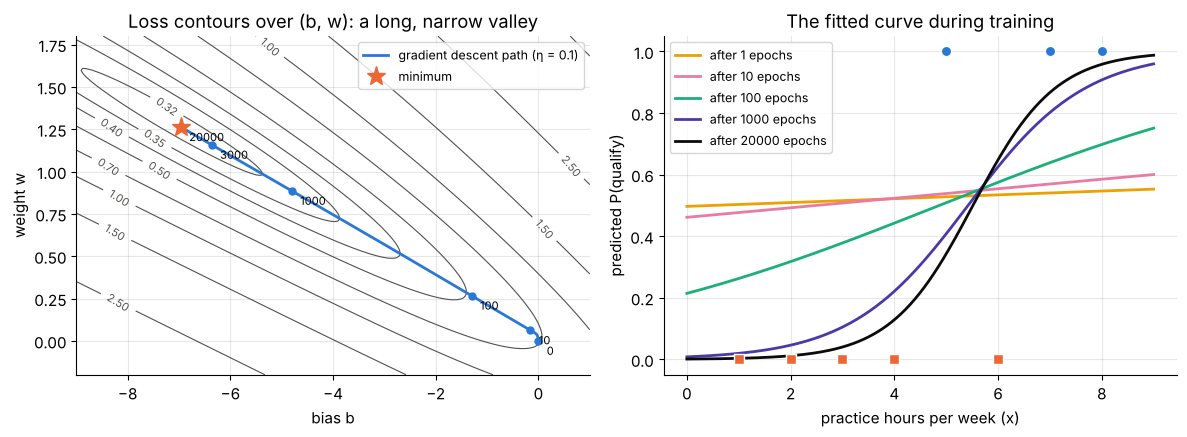

In [38]:
def loss_grid(Xb, y, b_range, w_range, n=160):
    """Evaluate the mean BCE on a (b, w) grid for contour plots. Returns B, W, L arrays of shape (n, n)."""
    B, W = np.meshgrid(np.linspace(*b_range, n), np.linspace(*w_range, n))
    Z = B[..., None] + W[..., None] * Xb[:, 1]                     # (n, n, m) logits
    L = np.mean(np.logaddexp(0, Z) - y * Z, axis=-1)
    return B, W, L


B_g, W_g, L_g = loss_grid(Xb_toy, y_toy, (-9, 1), (-0.2, 1.8))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
cs = ax.contour(B_g, W_g, L_g, levels=np.r_[0.32, 0.35, 0.4, 0.5, 0.7, 1.0, 1.5, 2.5, 4], colors=INK_SOFT, linewidths=0.8)
ax.clabel(cs, fontsize=8, fmt="%.2f")
marks = [0, 10, 100, 1000, 3000, 20_000]
ax.plot(thetas_raw[:, 0], thetas_raw[:, 1], color=PALETTE[0], lw=2, label="gradient descent path (η = 0.1)")
for t in marks:
    ax.plot(*thetas_raw[t], "o", color=PALETTE[0], ms=5)
    ax.annotate(f"{t}", thetas_raw[t], textcoords="offset points", xytext=(6, -10), fontsize=8)
ax.plot(b_fit, w_fit, "*", color=PALETTE[1], ms=14, label="minimum")
ax.set(xlabel="bias b", ylabel="weight w", title="Loss contours over (b, w): a long, narrow valley")
ax.legend(loc="upper right", fontsize=9)

ax = axes[1]
gx = np.linspace(0, 9, 300)
for t, col in zip([1, 10, 100, 1000, 20_000], [PALETTE[3], PALETTE[4], PALETTE[2], PALETTE[6], INK]):
    ax.plot(gx, sigmoid(thetas_raw[t, 0] + thetas_raw[t, 1] * gx), color=col, lw=2, label=f"after {t} epochs")
ax.scatter(x_toy[y_toy == 0], y_toy[y_toy == 0], marker="s", s=50, color=C_NEG, edgecolor="white", zorder=3)
ax.scatter(x_toy[y_toy == 1], y_toy[y_toy == 1], marker="o", s=55, color=C_POS, edgecolor="white", zorder=3)
ax.set(xlabel="practice hours per week (x)", ylabel="predicted P(qualify)", title="The fitted curve during training")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

The minimum sits at the bottom of a long, thin, tilted valley. Gradient descent first slides down the steep walls
(mostly increasing $w$), then has to creep along the nearly flat valley floor, where the gradient is tiny. A bigger
learning rate would help along the floor, but it would make the iterates bounce between the steep walls and blow up.

Why is the valley tilted and thin? Because $b$ and $w$ are tangled together: with $x$ between 1 and 8, raising $w$
by $0.1$ raises every logit by about $0.45$ on average, which can be undone by lowering $b$ by 0.45. Moving along that
combination barely changes the loss. The cure is the same as for linear regression: **standardize the feature**.

### 7.5 Feature scaling and the learning rate

Replace $x$ by $x' = (x - \mu)/s$ with $\mu = 4.5$ and $s \approx 2.2913$ (the mean and standard deviation of the eight
$x$ values). The model $\sigma(w'x' + b')$ is the same family of curves, just parametrized differently:

$$
w' x' + b' = \frac{w'}{s}\,x + \Big(b' - \frac{w'\mu}{s}\Big)
\quad\Longrightarrow\quad
w = \frac{w'}{s}, \qquad b = b' - \frac{w'\mu}{s}.
$$

So we can train on the standardized feature and convert back at the end. Let us compare how fast each version
converges for several learning rates.

In [39]:
mu_toy, sd_toy = x_toy.mean(), x_toy.std()             # population std (ddof=0), like StandardScaler
Xs_toy = add_bias((x_toy - mu_toy) / sd_toy)


def epochs_to_converge(losses, target, tol=1e-6):
    """First epoch at which loss <= target + tol (None if never reached)."""
    hit = np.flatnonzero(losses <= target + tol)
    return int(hit[0]) if hit.size else None


runs = {}
for label, Xb_, lr in [("raw x, η = 0.1", Xb_toy, 0.1), ("raw x, η = 0.3", Xb_toy, 0.3),
                       ("raw x, η = 0.5", Xb_toy, 0.5), ("raw x, η = 1.0", Xb_toy, 1.0),
                       ("standardized, η = 1", Xs_toy, 1.0), ("standardized, η = 4", Xs_toy, 4.0)]:
    th_, L_ = train_gd(Xb_, y_toy, lr=lr, epochs=5000)
    runs[label] = (th_, L_)
    print(f"{label:<22} loss after 5000 epochs = {L_[-1]:.6f}   epochs to reach the minimum (±1e-6): "
          f"{epochs_to_converge(L_, loss_star)}   largest loss seen = {L_.max():.3f}")

th_s = runs["standardized, η = 4"][0][-1]
print(f"\nstandardized solution b' = {th_s[0]:.4f}, w' = {th_s[1]:.4f}")
print(f"converted back: w = w'/s = {th_s[1] / sd_toy:.4f},  b = b' - w' mu / s = {th_s[0] - th_s[1] * mu_toy / sd_toy:.4f}"
      f"   (exact: w = {w_fit:.4f}, b = {b_fit:.4f})")

raw x, η = 0.1         loss after 5000 epochs = 0.311934   epochs to reach the minimum (±1e-6): None   largest loss seen = 0.693
raw x, η = 0.3         loss after 5000 epochs = 0.311824   epochs to reach the minimum (±1e-6): 3168   largest loss seen = 0.693


raw x, η = 0.5         loss after 5000 epochs = 0.311824   epochs to reach the minimum (±1e-6): 1844   largest loss seen = 1.307
raw x, η = 1.0         loss after 5000 epochs = 0.429372   epochs to reach the minimum (±1e-6): None   largest loss seen = 3.326


standardized, η = 1    loss after 5000 epochs = 0.311824   epochs to reach the minimum (±1e-6): 187   largest loss seen = 0.693
standardized, η = 4    loss after 5000 epochs = 0.311824   epochs to reach the minimum (±1e-6): 44   largest loss seen = 0.693

standardized solution b' = -1.2822, w' = 2.8925
converted back: w = w'/s = 1.2624,  b = b' - w' mu / s = -6.9630   (exact: w = 1.2624, b = -6.9630)


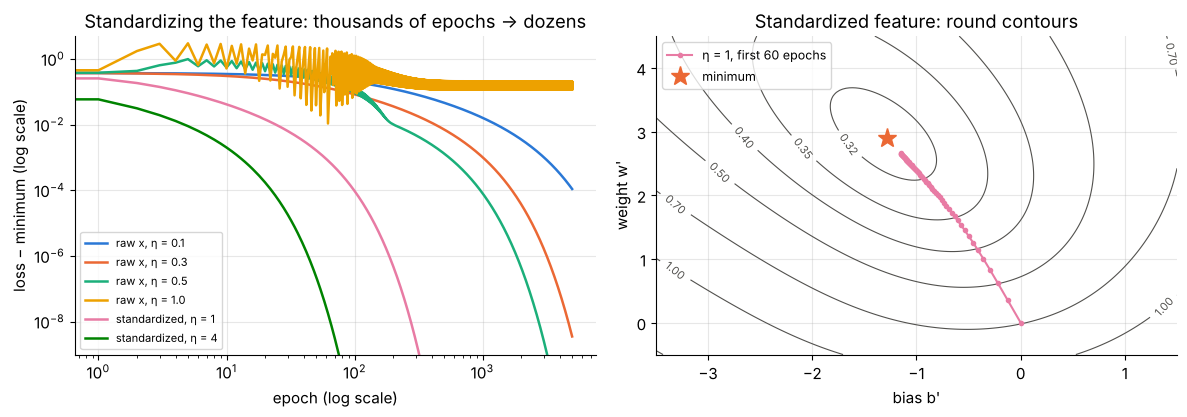

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for (label, (th_, L_)), col in zip(runs.items(), PALETTE):
    axes[0].plot(np.arange(len(L_)), L_ - loss_star + 1e-12, color=col, lw=1.8, label=label)
axes[0].set(xscale="log", yscale="log", ylim=(1e-9, 5), xlabel="epoch (log scale)", ylabel="loss − minimum (log scale)",
            title="Standardizing the feature: thousands of epochs → dozens")
axes[0].legend(fontsize=8, loc="lower left")

Bs, Ws, Ls = loss_grid(Xs_toy, y_toy, (-3.5, 1.5), (-0.5, 4.5))
cs = axes[1].contour(Bs, Ws, Ls, levels=np.r_[0.32, 0.35, 0.4, 0.5, 0.7, 1.0, 1.5], colors=INK_SOFT, linewidths=0.8)
axes[1].clabel(cs, fontsize=8, fmt="%.2f")
th_path = runs["standardized, η = 1"][0][:60]
axes[1].plot(th_path[:, 0], th_path[:, 1], "o-", color=PALETTE[4], ms=3, lw=1.5, label="η = 1, first 60 epochs")
axes[1].plot(*th_s, "*", color=PALETTE[1], ms=14, label="minimum")
axes[1].set(xlabel="bias b'", ylabel="weight w'", title="Standardized feature: round contours")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

What the experiment shows:

* **On raw $x$**, $\eta = 0.1$ does not reach the minimum (within $10^{-6}$) in 5,000 epochs (the table above shows it needs
  about 10,000), and $\eta = 0.3$ needs 3,168 epochs. At $\eta = 0.5$ the loss first *jumps up* (largest loss 1.307,
  worse than the starting 0.693) before it recovers in 1,844 epochs, and at $\eta = 1.0$ training never settles: after
  5,000 epochs the loss is still 0.429 because the iterates keep bouncing across the valley.
* **On standardized $x'$**, the contours are much rounder, the gradient points almost straight at the minimum, and
  $\eta = 4$ converges in 44 epochs. Converting back gives exactly the same model as before ($w = 1.2624$, $b = -6.9630$).

> **Going deeper.** How large can $\eta$ be? Near the minimum, gradient descent on a function with Hessian $H$ is stable
> only if $\eta < 2/\lambda_{\max}(H)$, and its speed is governed by the *condition number* $\lambda_{\max}/\lambda_{\min}$. For our raw
> data at $\boldsymbol\theta = \mathbf{0}$ the Hessian is $\frac14\cdot\frac1m\tilde X^\top\tilde X$ (because $\hat p(1-\hat p) = \frac14$ there), with eigenvalues of
> about $6.6$ and $0.05$: condition number about 130, and $\eta$ must stay below about $0.3$ at the start. Standardizing makes
> $\frac1m\tilde X^\top\tilde X$ the identity, so both eigenvalues become $\frac14$ and the condition number becomes 1. Section 9 uses the
> Hessian even more directly.

> **Common pitfall.** Compute $\mu$ and $s$ on the **training** data only and reuse them for validation and test data
> (Section 10 does this). Never standardize the bias column of ones: its standard deviation is 0.

In [41]:
# ✏️ Exercise 7: one epoch of full-batch gradient descent
def gd_epoch(Xb, y, theta, lr):
    """Return the NEW parameter vector after one full-batch gradient-descent step on the mean BCE.
    Xb: (m, n) with bias column, y: (m,), theta: (n,), lr: learning rate. Do not modify theta in place."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    Xb = add_bias(np.arange(1, 9.0))
    y = np.array([0, 0, 0, 0, 1, 0, 1, 1.0])
    th0 = np.zeros(2)
    th1 = gd_epoch(Xb, y, th0, 0.1)
    assert np.allclose(th0, 0), "theta was modified in place"
    assert np.allclose(th1, [-0.0125, 0.025]), f"epoch 1 should give [-0.0125, 0.025], got {th1}"
    th2 = gd_epoch(Xb, y, th1, 0.1)
    assert np.allclose(th2, [-0.027496, 0.035497], atol=1e-6), f"epoch 2 should give about [-0.027496, 0.035497], got {th2}"

run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def gd_epoch(Xb, y, theta, lr):
    p_hat = sigmoid(Xb @ theta)                 # (m,) predictions
    grad = Xb.T @ (p_hat - y) / len(y)          # (n,) gradient of the mean BCE
    return theta - lr * grad                    # a new array, and theta itself is untouched
```
`theta - lr * grad` creates a new array, whereas `theta -= lr * grad` would overwrite the caller's array.
</details>

In [42]:
# ✏️ Exercise 8: undo the standardization
def unstandardize(theta_std, mu, s):
    """theta_std = (b', w'_1, ..., w'_d) was learned on standardized features x'_j = (x_j - mu_j) / s_j.
    mu, s: arrays of shape (d,). Return the equivalent (b, w_1, ..., w_d) for the ORIGINAL features."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    rng = np.random.default_rng(3)
    X = rng.normal(5, 3, size=(30, 3))
    mu, s = X.mean(axis=0), X.std(axis=0)
    th_std = np.array([0.5, 1.0, -2.0, 0.25])
    th = np.asarray(unstandardize(th_std, mu, s), dtype=float)
    assert th.shape == (4,), f"expected shape (4,), got {th.shape}"
    z_std = add_bias((X - mu) / s) @ th_std
    assert np.allclose(add_bias(X) @ th, z_std), "the logits on the original features must equal the standardized logits"

run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def unstandardize(theta_std, mu, s):
    b_std, w_std = theta_std[0], np.asarray(theta_std[1:], dtype=float)
    w = w_std / s                         # each weight is divided by its feature's scale
    b = b_std - np.sum(w_std * mu / s)    # the centering shifts move into the bias
    return np.r_[b, w]
```
Expand $\sum_j w'_j (x_j - \mu_j)/s_j + b'$ and collect the terms that multiply each $x_j$ and the constant terms.
</details>

**Quick check.** After training on standardized features, one weight is $w'_{\text{age}} = -0.6$ with $s_{\text{age}} = 14$ years.
What is the change in log-odds for one extra year of age, and for one extra standard deviation?

<details>
<summary>Answer</summary>

Per standard deviation (14 years) the log-odds change by $-0.6$, so the odds are multiplied by $e^{-0.6} \approx 0.55$. Per year the
change is $-0.6/14 \approx -0.043$, i.e. the odds are multiplied by $e^{-0.043} \approx 0.958$ (about 4% lower per year). Standardized
weights compare features on a common scale, while raw weights answer "per unit" questions.
</details>

### 7.6 Two features: recovering a model we know

In Section 4.2 we generated 200 points from a known model, $\mathbf{w}_{\text{true}} = (1.5,\ 2.0)$ and $b_{\text{true}} = -1$, by flipping a
biased coin for each point. Can gradient descent recover those parameters from the 200 labels alone? The features are already
on a standard scale, so a learning rate of 1 is safe. We also record the parameters after every epoch to draw their
trajectories.

In [43]:
thetas_2d, losses_2d = train_gd(Xb_2d, y2d, lr=1.0, epochs=300)
theta_2d = thetas_2d[-1]
p_2d = predict_proba(Xb_2d, theta_2d)
H_2d = (Xb_2d * (p_2d * (1 - p_2d))[:, None]).T @ Xb_2d / len(y2d)      # Hessian of the mean loss (Section 5.5)
se_2d = np.sqrt(np.diag(np.linalg.inv(H_2d)) / len(y2d))                 # approximate standard errors
truth_2d = np.r_[b_true2d, w_true2d]
display(pd.DataFrame({"true": truth_2d, "estimate (300 epochs)": theta_2d, "std. error": se_2d,
                      "estimate − true": theta_2d - truth_2d, "|gradient|": np.abs(bce_grad(theta_2d, Xb_2d, y2d))},
                     index=["b", "w1", "w2"]).round(4))
print(f"final training loss {losses_2d[-1]:.4f}, and loss of the TRUE parameters on the same data {bce_loss(truth_2d, Xb_2d, y2d):.4f}")

,true,estimate (300 epochs),std. error,estimate − true,|gradient|
b,-1.0,-0.8878,0.2118,0.1122,0.0
w1,1.5,1.1898,0.2391,-0.3102,0.0
w2,2.0,1.7979,0.2811,-0.2021,0.0


final training loss 0.4255; loss of the TRUE parameters on the same data 0.4295


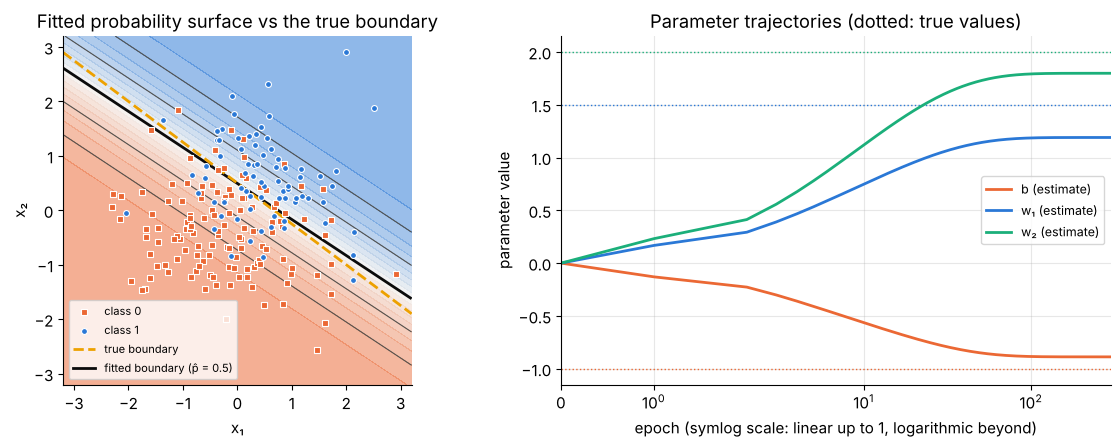

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
plot_prob_surface(axes[0], theta_2d[1:], theta_2d[0], alpha=0.55, label_levels=False)
scatter_classes(axes[0], X2d, y2d, s=18)
g = np.linspace(-3.2, 3.2, 50)
axes[0].plot(g, (-b_true2d - w_true2d[0] * g) / w_true2d[1], color=PALETTE[3], lw=2, ls="--", label="true boundary")
axes[0].plot([], [], color=INK, lw=2, label="fitted boundary (p̂ = 0.5)")
axes[0].set_title("Fitted probability surface vs the true boundary")
axes[0].legend(fontsize=8, loc="lower left")
for j, (name, col) in enumerate(zip(["b", "w₁", "w₂"], [PALETTE[1], PALETTE[0], PALETTE[2]])):
    axes[1].plot(thetas_2d[:, j], color=col, lw=2, label=f"{name} (estimate)")
    axes[1].axhline(truth_2d[j], color=col, lw=1, ls=":")
axes[1].set(xscale="symlog", xlim=(0, 300), xlabel="epoch (symlog scale: linear up to 1, logarithmic beyond)",
            ylabel="parameter value", title="Parameter trajectories (dotted: true values)")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

Gradient descent converges within about a hundred epochs (the gradient is zero to four decimals after 300), and the
estimates land near the truth, but **not on it**: $\hat b = -0.888$, $\hat w_1 = 1.190$, $\hat w_2 = 1.798$. That is not an
optimization failure: the fitted parameters have a *lower* training loss than the true ones (0.4255 vs 0.4295). With only 200 coin flips, the data contain some randomness, and the maximum-likelihood estimate follows
it. The standard errors, computed from the inverse Hessian (the same curvature matrix as in Section 5.5), measure this
sampling uncertainty: each estimate is within two standard errors of the true value (the largest miss, $\hat w_1$, is
$0.31 \approx 1.3$ standard errors).

How does the error shrink with more data? Repeat the experiment many times for several sample sizes $m$:

In [45]:
rows = []
for m_size in [50, 200, 1000, 5000]:
    errs = []
    for rep in range(40):
        r = np.random.default_rng(1000 * m_size + rep)
        Xr = r.normal(size=(m_size, 2))
        yr = (r.random(m_size) < sigmoid(Xr @ w_true2d + b_true2d)).astype(float)
        fit = LogisticRegression(C=1e6, tol=1e-8, max_iter=1000).fit(Xr, yr)     # essentially unregularized
        errs.append(np.linalg.norm(np.r_[fit.intercept_, fit.coef_.ravel()] - truth_2d))
    rows.append({"m": m_size, "average ||estimate − truth||": np.mean(errs), "× sqrt(m)": np.mean(errs) * np.sqrt(m_size)})
display(pd.DataFrame(rows).set_index("m").round(3))

,average ||estimate − truth||,× sqrt(m)
m,,
50,1.383,9.777
200,0.486,6.870
1000,0.185,5.853
5000,0.100,7.067


Once $m$ is in the hundreds, the last column hovers around 6 to 7 (it is itself an average of only 40 random experiments):
the estimation error shrinks like $1/\sqrt{m}$. To halve the error you need four times as much data, the same law that
governs averages and polls. (For very small $m$ the estimates are also biased away from zero,
a known small-sample effect of maximum likelihood for logistic regression, and with near-separation they can even blow up.)

### 7.7 Curved boundaries from a linear model

Logistic regression is linear in its **features**, not necessarily in the raw inputs. Suppose class 1 lives inside a disc:
the true log-odds are $z = 4 - 2(x_1^2 + x_2^2)$, so $\hat p = 0.5$ on the circle $x_1^2 + x_2^2 = 2$. No straight line can separate
"inside" from "outside". But if we add the features $x_1^2$, $x_2^2$ and $x_1x_2$, the true log-odds become a *linear* function of
the feature vector $(x_1, x_2, x_1^2, x_2^2, x_1x_2)$, and logistic regression can represent them exactly.

In [46]:
rng_c = np.random.default_rng(SEED + 1)
X_disc = rng_c.uniform(-2.5, 2.5, size=(400, 2))
y_disc = (rng_c.random(400) < sigmoid(4 - 2 * (X_disc**2).sum(axis=1))).astype(float)


def quad_features(X):
    """(m, 2) -> (m, 5): x1, x2, x1^2, x2^2, x1*x2."""
    return np.column_stack([X[:, 0], X[:, 1], X[:, 0]**2, X[:, 1]**2, X[:, 0] * X[:, 1]])


fits = {}
for name, feat in [("linear features (x₁, x₂)", lambda X: X), ("quadratic features", quad_features)]:
    F = feat(X_disc)
    f_mu, f_sd = F.mean(axis=0), F.std(axis=0)
    th_, L_ = train_gd(add_bias((F - f_mu) / f_sd), y_disc, lr=1.0, epochs=2000)
    fits[name] = (feat, f_mu, f_sd, th_[-1])
    p_fit = predict_proba(add_bias((F - f_mu) / f_sd), th_[-1])
    print(f"{name:<26}: training loss {L_[-1]:.4f}, training accuracy {np.mean((p_fit >= 0.5) == y_disc):.3f}, "
          f"largest predicted probability {p_fit.max():.3f}")
print(f"(fraction of class 1: {y_disc.mean():.3f})")

linear features (x₁, x₂)  : training loss 0.5381, training accuracy 0.770, largest predicted probability 0.283
quadratic features        : training loss 0.2164, training accuracy 0.902, largest predicted probability 0.963
(fraction of class 1: 0.230)


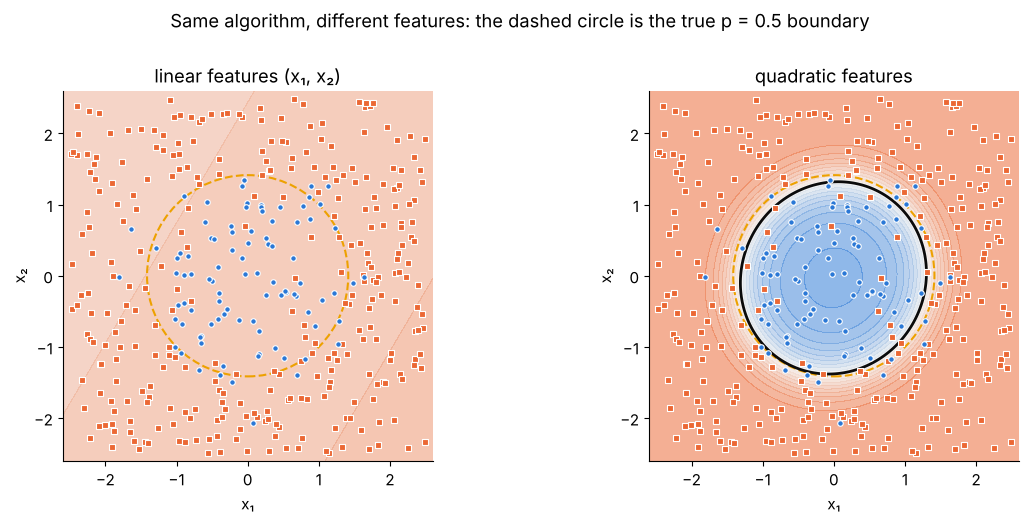

In [47]:
gg = np.linspace(-2.6, 2.6, 260)
G1, G2 = np.meshgrid(gg, gg)
Ggrid = np.column_stack([G1.ravel(), G2.ravel()])
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, (name, (feat, f_mu, f_sd, th_)) in zip(axes, fits.items()):
    P = predict_proba(add_bias((feat(Ggrid) - f_mu) / f_sd), th_).reshape(G1.shape)
    ax.contourf(G1, G2, P, levels=np.linspace(0, 1, 21), cmap=PROB_CMAP, alpha=0.55)
    ax.contour(G1, G2, P, levels=[0.5], colors=INK, linewidths=2)
    scatter_classes(ax, X_disc, y_disc, s=16)
    ax.add_patch(plt.Circle((0, 0), np.sqrt(2), fill=False, ls="--", lw=1.5, color=PALETTE[3]))
    ax.set(xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), aspect="equal", xlabel="x₁", ylabel="x₂", title=name)
    ax.grid(False)
fig.suptitle("Same algorithm, different features: the dashed circle is the true p = 0.5 boundary", y=1.0)
plt.tight_layout()
plt.show()

With the raw inputs the model can only draw a line, finds nothing useful, and predicts close to the base rate almost
everywhere: its training accuracy, 0.770, is exactly what "always class 0" achieves (77% of the points are in class 0),
and no point gets $\hat p \ge 0.5$ (the largest predicted probability is 0.283). With quadratic features the same algorithm cuts the training loss from 0.538 to
0.216, reaches 0.902 accuracy, and recovers a boundary close to the true circle. The boundary is a
conic section in the $(x_1, x_2)$ plane but a hyperplane in the 5-dimensional feature space.

> **Key idea.** "Linear classifier" means linear in whatever features you give it. Choosing features by hand is called
> **feature engineering** (Section 10 does a lot of it). A neural network does something more powerful: its hidden layers
> *learn* the features, and its last layer is often exactly a logistic regression (Notebooks 10 and 12).

**Quick check.** With features $(x_1, x_2, x_1^2, x_2^2, x_1x_2)$, which of these boundaries can logistic regression represent exactly:
a circle, an ellipse tilted by 30°, a parabola, two parallel lines, a figure-eight?

<details>
<summary>Answer</summary>

The boundary is the set where $b + w_1x_1 + w_2x_2 + w_3x_1^2 + w_4x_2^2 + w_5x_1x_2 = 0$: a general **conic**. Circles, tilted
ellipses, parabolas and pairs of parallel lines (for example $x_1^2 = 1$, i.e. $x_1 = \pm 1$) are all conics, so all of these are
possible. A figure-eight is not a conic, so it needs higher-degree features (or a neural network).
</details>

## 8. Separable data: when the weights never stop growing

Our eight students were *not* perfectly separable: S5 (5 h) qualified while S6 (6 h) did not, so no threshold on $x$
classifies everyone correctly. That noise is exactly what gave the loss a finite minimum. Now suppose S5 and S6 had
swapped results: the first five students fail, the last three qualify, and the threshold "$x > 5.5$" is perfect.

### 8.1 There is no minimum

Take any parameters that classify every training example correctly, i.e. $z_i > 0$ whenever $y_i = 1$ and $z_i < 0$
whenever $y_i = 0$. Multiply them by a constant $c > 1$. The boundary $z = 0$ does not move, but every logit gets further
from zero *on its correct side*. In the logit form of Section 5.4, each example's loss is
$\operatorname{softplus}(-|z_i|) = \log(1 + e^{-|z_i|})$ when it is classified correctly, and that is strictly decreasing in $|z_i|$. So

$$
\mathcal{L}(c\,\boldsymbol\theta) = \frac1m\sum_{i=1}^m \log\big(1 + e^{-c\,|z_i|}\big) \;\xrightarrow[c\to\infty]{}\; 0,
$$

and it decreases all the way. The infimum of the loss is $0$, but no finite $\boldsymbol\theta$ attains it: **the maximum
likelihood estimate does not exist**. Gradient descent still dutifully lowers the loss forever, which means the weights
grow forever. Let us watch it happen (on the standardized feature, with $\eta = 1$, for 100,000 epochs).

In [48]:
y_sep = np.array([0, 0, 0, 0, 0, 1, 1, 1], dtype=float)    # S5 and S6 swapped: now a threshold at 5.5 is perfect


def gd_run(Xb, y, lr, epochs, lam=0.0, record=()):
    """Lean full-batch gradient descent on mean BCE + (lam/2)*||w||^2 (the bias theta[0] is not penalized).
    Returns the final theta and a dict {epoch: theta} for the epochs listed in `record`."""
    theta, saved, record = np.zeros(Xb.shape[1]), {}, set(record)
    for t in range(1, epochs + 1):
        grad = Xb.T @ (special.expit(Xb @ theta) - y) / len(y)   # scipy's expit: a fast, overflow-safe sigmoid
        grad[1:] += lam * theta[1:]
        theta = theta - lr * grad
        if t in record:
            saved[t] = theta.copy()
    return theta, saved


def to_raw(theta_std):
    """Convert (b', w') learned on the standardized toy feature back to (b, w) for raw hours."""
    return theta_std[0] - theta_std[1] * mu_toy / sd_toy, theta_std[1] / sd_toy


t0 = time.time()
rec_sep = np.unique(np.logspace(0, 5, 81).astype(int))
_, path_sep = gd_run(Xs_toy, y_sep, lr=1.0, epochs=100_000, record=rec_sep)
print(f"100,000 epochs in {time.time() - t0:.1f} s")
rows = []
for t in [1, 10, 100, 1000, 10_000, 100_000]:
    b_r, w_r = to_raw(path_sep[t])
    rows.append({"epoch": t, "b": b_r, "w": w_r, "||theta'||": np.linalg.norm(path_sep[t]),
                 "loss": f"{bce_loss(path_sep[t], Xs_toy, y_sep):.2e}", "boundary -b/w": -b_r / w_r,
                 "p(S5)": float(sigmoid(b_r + 5 * w_r)), "p(S6)": float(sigmoid(b_r + 6 * w_r))})
display(pd.DataFrame(rows).set_index("epoch").round(4))

100,000 epochs in 0.7 s


,b,w,||theta'||,loss,boundary -b/w,p(S5),p(S6)
epoch,,,,,,,
1,-0.9286,0.1786,0.4278,5.33e-01,5.2000,0.4911,0.5357
10,-4.4245,0.8411,2.0306,2.31e-01,5.2601,0.4455,0.6507
100,-11.6642,2.1466,5.3112,8.52e-02,5.4338,0.2827,0.7712
1000,-26.8467,4.8974,12.2082,2.10e-02,5.4819,0.0863,0.9267
10000,-50.5698,9.2092,22.9908,2.50e-03,5.4912,0.0107,0.9909
100000,-75.9111,13.8166,34.5095,2.51e-04,5.4942,0.0011,0.9991


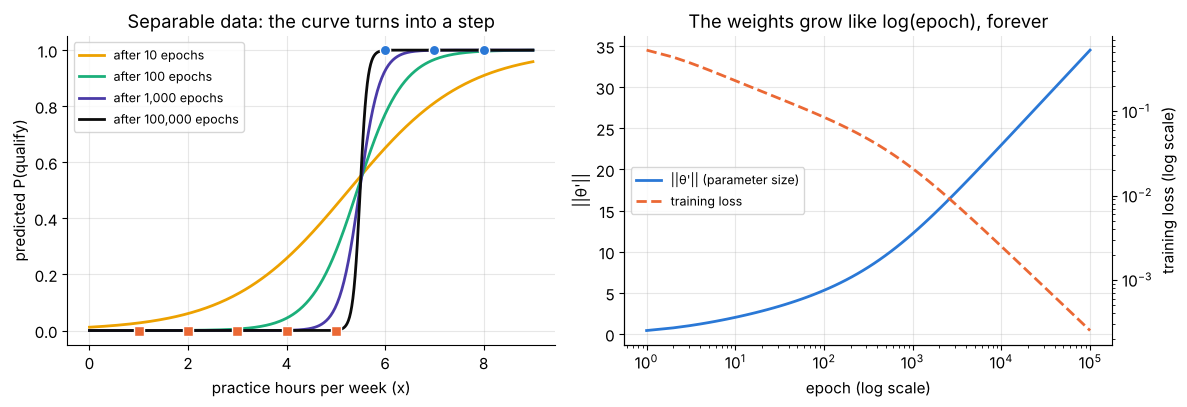

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
gx = np.linspace(0, 9, 400)
for t, col in zip([10, 100, 1000, 100_000], [PALETTE[3], PALETTE[2], PALETTE[6], INK]):
    b_r, w_r = to_raw(path_sep[t])
    axes[0].plot(gx, sigmoid(b_r + w_r * gx), color=col, lw=2, label=f"after {t:,} epochs")
axes[0].scatter(x_toy[y_sep == 0], y_sep[y_sep == 0], marker="s", s=50, color=C_NEG, edgecolor="white", zorder=3)
axes[0].scatter(x_toy[y_sep == 1], y_sep[y_sep == 1], marker="o", s=55, color=C_POS, edgecolor="white", zorder=3)
axes[0].set(xlabel="practice hours per week (x)", ylabel="predicted P(qualify)", title="Separable data: the curve turns into a step")
axes[0].legend(fontsize=9, loc="upper left")

norms = np.array([np.linalg.norm(path_sep[t]) for t in rec_sep])
axes[1].plot(rec_sep, norms, color=PALETTE[0], lw=2, label="||θ'|| (parameter size)")
axes[1].set(xscale="log", xlabel="epoch (log scale)", ylabel="||θ'||", title="The weights grow like log(epoch), forever")
ax2 = axes[1].twinx()
ax2.plot(rec_sep, [bce_loss(path_sep[t], Xs_toy, y_sep) for t in rec_sep], color=PALETTE[1], lw=2, ls="--", label="training loss")
ax2.set(yscale="log", ylabel="training loss (log scale)")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
lines = axes[1].get_lines() + ax2.get_lines()
axes[1].legend(lines, [l.get_label() for l in lines], fontsize=9, loc="center left")
plt.tight_layout()
plt.show()

The numbers confirm the argument:

* $\|\boldsymbol\theta'\|$ goes $2.03 \to 5.31 \to 12.21 \to 22.99 \to 34.51$ at epochs $10, 10^2, 10^3, 10^4, 10^5$: after a slower
  start, each tenfold increase in training time adds a roughly constant amount (about 11 from $10^3$ on: $+10.8$, then
  $+11.5$), the signature of **logarithmic growth** (the curve becomes a straight line on the log axis).
* The loss falls roughly tenfold for every tenfold increase in epochs ($2.10\times10^{-2} \to 2.50\times10^{-3} \to 2.51\times10^{-4}$ at
  epochs $10^3, 10^4, 10^5$): it behaves like $1/t$ and never reaches 0.
* The predicted probabilities for the two students next to the boundary are pushed to the extremes: after $10^5$ epochs
  $p(\text{S5}) = 0.0011$ and $p(\text{S6}) = 0.9991$. Would you really bet 1,000 to 1 that a student who practices 6 hours qualifies,
  based on eight data points?
* Meanwhile the boundary barely moves: it settles at the midpoint **5.5** between the last failure and the first
  qualifier (5.4942 after $10^5$ epochs).

Why you should care:

1. **Overconfidence.** The model claims near-certainty that the data cannot justify. Probabilities near 0 and 1 also
   make the loss on a new, slightly unusual example enormous.
2. **Meaningless coefficients.** "The MLE" is infinite, so the reported weight is just "wherever the optimizer
   stopped". Software that reports standard errors or odds ratios will give absurd values (often with a warning about
   perfect separation).
3. **It is common in practice.** With many features it is easy to separate the training set. In fact any labeling of
   $m$ points in general position in $\mathbb{R}^d$ can be separated by a hyperplane when $m \le d + 1$. Text classifiers with
   thousands of word features, or a single rare category that only ever appears with one label, run into this constantly.

> **Going deeper.** Even though $\|\boldsymbol\theta\|$ diverges, its *direction* converges: on separable data gradient descent
> on the logistic loss converges in direction to the **maximum-margin** separator of the points $(1, \mathbf{x}_i)$ (Soudry et
> al., 2018). Because our bias is trained like any other weight, this is a hard-margin support vector machine whose norm
> also includes the bias. It can differ from the usual SVM, which leaves the bias unpenalized, but for our data both put the
> boundary at the midpoint 5.5, exactly where our boundary is heading. The same theory explains the growth rate: for large
> $t$, $\boldsymbol\theta'(t)$ grows like $(\ln t)\,\boldsymbol\theta'_{\text{mm}}$ plus a bounded correction, where
> $\boldsymbol\theta'_{\text{mm}} = (-2, 4.58)$, the shortest $\boldsymbol\theta'$ with $z_i \ge 1$ for every qualifier and $z_i \le -1$ for
> every non-qualifier, has length exactly 5. So each tenfold increase eventually adds about $5\ln 10 \approx 11.5$ to
> $\|\boldsymbol\theta'\|$. This "implicit bias" of gradient descent is an active research topic in deep learning.

### 8.2 The fix: L2 regularization

Add a penalty on the size of the weights (not the bias):

$$
\mathcal{L}_\lambda(\boldsymbol\theta) = \frac1m\sum_{i=1}^m \ell_i(\boldsymbol\theta) + \frac{\lambda}{2}\,\|\mathbf{w}\|^2,
\qquad
\nabla_{\mathbf{w}}\mathcal{L}_\lambda = \frac1m X^\top(\hat{\mathbf{p}} - \mathbf{y}) + \lambda\mathbf{w},
\qquad
\frac{\partial \mathcal{L}_\lambda}{\partial b} = \frac1m\sum_i(\hat p_i - y_i).
$$

* Now growing the weights has a cost that rises without limit, while the data term can never go below 0, so a finite
  minimizer exists. The penalty adds $\lambda$ to the weight part of the Hessian, so the objective is strictly convex in
  $\mathbf{w}$ and the minimizer is unique.
* The bias is not penalized because it only sets the baseline rate, and shrinking it toward 0 would bias every prediction
  toward 50% for no good reason.
* $\lambda$ is a dial: large $\lambda$ gives small weights and soft, cautious probabilities, and small $\lambda$ trusts the data more.
  Choose it with validation data, like any hyperparameter.

scikit-learn writes the same objective differently: it minimizes $C\sum_i \ell_i + \frac12\|\mathbf{w}\|^2$. Dividing by $Cm$ shows
that $C = 1/(\lambda m)$. Let us train with three values of $\lambda$ and check our solutions against scikit-learn.

,C = 1/(lambda m),b' (ours),w' (ours),b' (sklearn),w' (sklearn),boundary,p(S5),p(S6)
lambda,,,,,,,,
0.100,1.25,-0.7493,1.4471,-0.7493,1.4471,5.6864,0.3933,0.5494
0.010,12.50,-1.6017,3.6534,-1.6017,3.6534,5.5046,0.3091,0.6878
0.001,125.00,-3.6386,8.3371,-3.6386,8.3371,5.5000,0.1395,0.8605


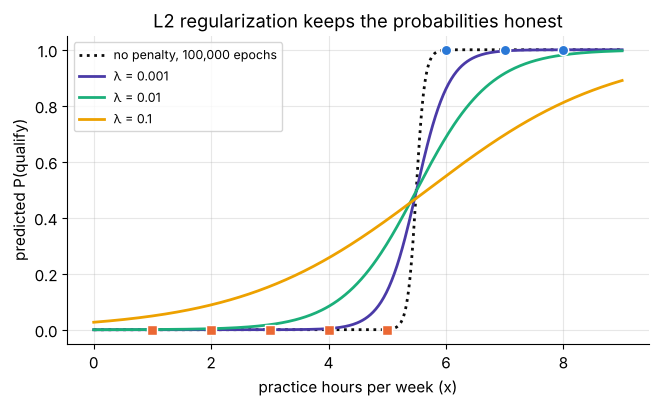

In [50]:
rows, curves = [], {}
for lam in [0.1, 0.01, 0.001]:
    th_lam, _ = gd_run(Xs_toy, y_sep, lr=1.0, epochs=20_000, lam=lam)
    clf = LogisticRegression(C=1.0 / (lam * len(y_sep)), tol=1e-12, max_iter=100_000).fit(Xs_toy[:, 1:], y_sep)
    b_r, w_r = to_raw(th_lam)
    curves[lam] = (b_r, w_r)
    rows.append({"lambda": lam, "C = 1/(lambda m)": 1.0 / (lam * len(y_sep)), "b' (ours)": th_lam[0], "w' (ours)": th_lam[1],
                 "b' (sklearn)": clf.intercept_[0], "w' (sklearn)": clf.coef_[0, 0], "boundary": -b_r / w_r,
                 "p(S5)": float(sigmoid(b_r + 5 * w_r)), "p(S6)": float(sigmoid(b_r + 6 * w_r))})
display(pd.DataFrame(rows).set_index("lambda").round(4))

fig, ax = plt.subplots(figsize=(7.5, 4))
b_r, w_r = to_raw(path_sep[100_000])
ax.plot(gx, sigmoid(b_r + w_r * gx), color=INK, lw=2, ls=":", label="no penalty, 100,000 epochs")
for lam, col in zip([0.001, 0.01, 0.1], [PALETTE[6], PALETTE[2], PALETTE[3]]):
    ax.plot(gx, sigmoid(curves[lam][0] + curves[lam][1] * gx), color=col, lw=2, label=f"λ = {lam}")
ax.scatter(x_toy[y_sep == 0], y_sep[y_sep == 0], marker="s", s=50, color=C_NEG, edgecolor="white", zorder=3)
ax.scatter(x_toy[y_sep == 1], y_sep[y_sep == 1], marker="o", s=55, color=C_POS, edgecolor="white", zorder=3)
ax.set(xlabel="practice hours per week (x)", ylabel="predicted P(qualify)", title="L2 regularization keeps the probabilities honest")
ax.legend(fontsize=9)
plt.show()

Our gradient-descent solutions and scikit-learn's agree to all printed digits, which confirms the conversion $C = 1/(\lambda m)$.
With $\lambda = 0.1$ the probabilities for S5 and S6 are a cautious 0.39 and 0.55, and with $\lambda = 0.001$ they are 0.14 and 0.86,
confident but finite. The boundaries stay close to 5.5 (5.69, 5.50, 5.50): regularization mainly changes *how sure* the
model is, not *where* it draws the line. (With $\lambda = 0.1$ the boundary drifts right because the penalty flattens the curve
toward the base rate, and only 3 of the 8 students qualify.)

> **Common pitfall.** `sklearn.linear_model.LogisticRegression()` is **regularized by default** ($C = 1$, L2 penalty). That is a
> sensible default for prediction, but if you want the plain maximum-likelihood fit (for example to compare with a
> hand-written gradient descent or a statistics package) you must ask for it with `C=np.inf`. (Older code writes
> `penalty=None`. Scikit-learn deprecated the whole `penalty` argument in version 1.8 and plans to remove it in 1.10.)

> **Intuition.** Two other regularizers are worth knowing. **Early stopping** (stop when validation loss stops improving)
> limits how far the weights can travel, so it acts much like an L2 penalty, and Section 10 uses it. An **L1 penalty**
> $\lambda\|\mathbf{w}\|_1$ pushes many weights to exactly zero, which performs feature selection.

In [51]:
# ✏️ Exercise 9: the L2-regularized loss and gradient
def l2_loss_and_grad(theta, Xb, y, lam):
    """Return (loss, grad) for  mean BCE + (lam/2) * ||w||^2, where w = theta[1:] (theta[0] is the unpenalized bias).
    Xb: (m, n) with a bias column, y: (m,), theta: (n,). Compute the BCE stably from the logits."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    rng = np.random.default_rng(11)
    Xb = add_bias(rng.normal(size=(25, 2)))
    y = (rng.random(25) < 0.4).astype(float)
    th = np.array([0.3, -1.2, 2.0])
    loss, grad = l2_loss_and_grad(th, Xb, y, 0.5)
    assert np.isclose(loss, bce_loss(th, Xb, y) + 0.25 * (1.2**2 + 2.0**2)), f"loss value is off: {loss}"
    num = numerical_gradient(lambda t: l2_loss_and_grad(t, Xb, y, 0.5)[0], th)
    assert np.allclose(grad, num, atol=1e-6), f"gradient {grad} does not match finite differences {num}"
    _, g0 = l2_loss_and_grad(th, Xb, y, 0.0)
    assert np.isclose(grad[0], g0[0]), "the bias must not be penalized"
    assert np.isfinite(l2_loss_and_grad(100 * th, Xb, y, 0.5)[0]), "loss must stay finite for huge logits"

run_check("Exercise 9", _test)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def l2_loss_and_grad(theta, Xb, y, lam):
    z = Xb @ theta
    w = theta[1:]
    loss = np.mean(np.logaddexp(0.0, z) - y * z) + 0.5 * lam * np.sum(w**2)
    grad = Xb.T @ (sigmoid(z) - y) / len(y)
    grad[1:] += lam * w                     # penalty gradient on the weights only
    return float(loss), grad
```
`np.logaddexp(0, z)` is $\log(1 + e^z)$ computed without overflow, as in Section 5.4.
</details>

**Quick check.** You add a duplicate copy of feature $x_1$ (so $x_2 = x_1$) and fit *unregularized* logistic regression. What
happens to the weights? What changes with an L2 penalty?

<details>
<summary>Answer</summary>

Without a penalty only the sum $w_1 + w_2$ matters, so infinitely many weight pairs give the same loss: the Hessian is singular and
the individual weights are not identifiable (gradient descent from zero happens to split the sum equally, but a different start would
not). With an L2 penalty the split that minimizes $w_1^2 + w_2^2$ for a given sum, namely $w_1 = w_2$, is the unique best choice, so
the solution becomes unique again.
</details>

## 9. Bonus: Newton's method and IRLS

Gradient descent only uses the slope. In Section 5.5 we computed the *curvature* too: the Hessian
$H(\boldsymbol\theta) = \frac1m\tilde X^\top S\tilde X$ with $S = \operatorname{diag}\big(\hat p_i(1-\hat p_i)\big)$. Newton's method uses both.

### 9.1 The idea: jump to the bottom of the local parabola

Near the current point $\boldsymbol\theta_k$, approximate the loss by its second-order Taylor expansion

$$
\mathcal{L}(\boldsymbol\theta_k + \boldsymbol\delta) \approx \mathcal{L}(\boldsymbol\theta_k) + \mathbf{g}^\top\boldsymbol\delta + \tfrac12\,\boldsymbol\delta^\top H\boldsymbol\delta,
\qquad \mathbf{g} = \nabla\mathcal{L}(\boldsymbol\theta_k),\ H = H(\boldsymbol\theta_k).
$$

Because $H$ is positive definite (for non-degenerate data), this quadratic bowl has a unique minimum where its gradient
$\mathbf{g} + H\boldsymbol\delta$ vanishes, i.e. at $\boldsymbol\delta = -H^{-1}\mathbf{g}$. Newton's method jumps straight there:

$$
\boldsymbol\theta_{k+1} = \boldsymbol\theta_k - H(\boldsymbol\theta_k)^{-1}\,\nabla\mathcal{L}(\boldsymbol\theta_k).
$$

Compare with gradient descent, $\boldsymbol\theta_{k+1} = \boldsymbol\theta_k - \eta\,\nabla\mathcal{L}$: Newton replaces the single number $\eta$ by the matrix $H^{-1}$,
which takes long steps in flat directions and short steps in steep ones. That is exactly the cure for the long, narrow
valley of Section 7.4, and there is no learning rate to tune. (In one dimension this is the familiar Newton iteration for
solving $\mathcal{L}'(\theta) = 0$: $\theta_{k+1} = \theta_k - \mathcal{L}'(\theta_k)/\mathcal{L}''(\theta_k)$.)

In [52]:
def newton_logistic(Xb, y, iters=10, theta0=None):
    """Newton's method for mean-BCE logistic regression. Returns the list of iterates theta_0, ..., theta_iters."""
    theta = np.zeros(Xb.shape[1]) if theta0 is None else np.array(theta0, dtype=float)
    path = [theta.copy()]
    for _ in range(iters):
        p_hat = predict_proba(Xb, theta)
        grad = Xb.T @ (p_hat - y) / len(y)
        H = (Xb * (p_hat * (1 - p_hat))[:, None]).T @ Xb / len(y)    # (1/m) X^T S X without building S
        theta = theta - np.linalg.solve(H, grad)                        # solve H delta = grad (never invert H)
        path.append(theta.copy())
    return path


newton_path = newton_logistic(Xb_toy, y_toy, iters=8)              # raw hours, no scaling needed
rows = []
for k, th in enumerate(newton_path):
    rows.append({"iteration": k, "b": th[0], "w": th[1], "loss": bce_loss(th, Xb_toy, y_toy),
                 "loss - min": bce_loss(th, Xb_toy, y_toy) - loss_star,
                 "||gradient||": np.linalg.norm(bce_grad(th, Xb_toy, y_toy))})
newton_table = pd.DataFrame(rows).set_index("iteration")
fmt = {"b": "{:.6f}", "w": "{:.6f}", "loss": "{:.6f}", "loss - min": "{:.1e}", "||gradient||": "{:.1e}"}
display(newton_table.apply(lambda col: col.map(fmt[col.name].format)))

,b,w,loss,loss - min,||gradient||
iteration,,,,,
0,0.000000,0.000000,0.693147,3.8e-01,2.8e-01
1,-3.285714,0.619048,0.371044,5.9e-02,4.1e-02
2,-5.212670,0.959195,0.321871,1.0e-02,1.4e-02
3,-6.496037,1.181686,0.312431,6.1e-04,3.2e-03
4,-6.926711,1.256125,0.311828,3.5e-06,2.2e-04
5,-6.962726,1.262356,0.311824,1.3e-10,1.3e-06
6,-6.962950,1.262395,0.311824,-5.6e-17,4.8e-11
7,-6.962950,1.262395,0.311824,-5.6e-17,8.4e-17
8,-6.962950,1.262395,0.311824,0.0e+00,2.8e-16


Look at the last column. From iteration 3 on, the exponent of the gradient norm roughly **doubles** at every step
($3.2\times10^{-3} \to 2.2\times10^{-4} \to 1.3\times10^{-6} \to 4.8\times10^{-11}$): the number of correct digits doubles, which is
**quadratic convergence**. Six or seven Newton iterations on the *raw* feature reach the minimum to machine precision,
against about 10,000 gradient-descent epochs with $\eta = 0.1$ on raw $x$ and 44 epochs on the standardized feature. Newton's method does not care about feature scaling at all: rescaling $x$
rescales $H$ in exactly the compensating way (the method is *affine invariant*).

### 9.2 The same step as a weighted least-squares problem (IRLS)

Statisticians usually present Newton's method for logistic regression in another form. Write $\hat{\mathbf{p}} = \sigma(\tilde X\boldsymbol\theta)$. Then
(the factors $\frac1m$ in $H$ and $\mathbf{g}$ cancel)

$$
\boldsymbol\theta_{\text{new}} = \boldsymbol\theta - (\tilde X^\top S\tilde X)^{-1}\tilde X^\top(\hat{\mathbf{p}} - \mathbf{y})
= (\tilde X^\top S\tilde X)^{-1}\Big[\tilde X^\top S\tilde X\boldsymbol\theta + \tilde X^\top(\mathbf{y} - \hat{\mathbf{p}})\Big]
= (\tilde X^\top S\tilde X)^{-1}\tilde X^\top S\,\mathbf{u},
$$

with the **working response** $\mathbf{u} = \tilde X\boldsymbol\theta + S^{-1}(\mathbf{y} - \hat{\mathbf{p}})$, i.e. $u_i = z_i + \dfrac{y_i - \hat p_i}{\hat p_i(1-\hat p_i)}$.

The right-hand side is the solution of a **weighted least-squares** problem: fit a linear model to the targets $u_i$, giving
example $i$ the weight $s_i = \hat p_i(1 - \hat p_i)$. Each Newton step therefore re-weights the examples and solves a least-squares
problem, hence the name **iteratively reweighted least squares (IRLS)**. Examples the model is already sure about
($\hat p_i$ near 0 or 1) get tiny weights. Let us confirm that one IRLS step equals one Newton step.

In [53]:
def irls_step(Xb, y, theta):
    """One IRLS step: weighted least squares with weights s_i = p_i(1-p_i) and working response u_i."""
    z = Xb @ theta
    p_hat = sigmoid(z)
    s = p_hat * (1 - p_hat)
    u = z + (y - p_hat) / s                                   # working response
    sw = np.sqrt(s)                                           # weighted LS = ordinary LS on rows scaled by sqrt(s_i)
    return np.linalg.lstsq(Xb * sw[:, None], u * sw, rcond=None)[0]


th_irls = np.zeros(2)
for k in range(1, 4):
    th_irls = irls_step(Xb_toy, y_toy, th_irls)
    print(f"step {k}: IRLS theta = {th_irls.round(6)}   Newton theta = {newton_path[k].round(6)}   "
          f"max difference = {np.max(np.abs(th_irls - newton_path[k])):.1e}")

step 1: IRLS theta = [-3.28571  0.61905]   Newton theta = [-3.28571  0.61905]   max difference = 4.0e-15
step 2: IRLS theta = [-5.21267  0.9592 ]   Newton theta = [-5.21267  0.9592 ]   max difference = 8.9e-16
step 3: IRLS theta = [-6.49604  1.18169]   Newton theta = [-6.49604  1.18169]   max difference = 6.2e-15


Identical, as the algebra promised.

### 9.3 The price of curvature, and the methods used in practice

The plot compares the three optimizers we have built, counting one full pass over the data as one iteration for each.

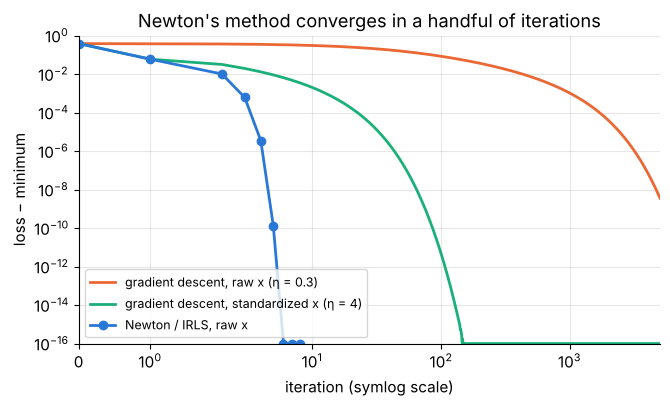

In [54]:
L_gd_raw = runs["raw x, η = 0.3"][1]
L_gd_std = runs["standardized, η = 4"][1]
L_newton = np.array([bce_loss(th, Xb_toy, y_toy) for th in newton_path])
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(np.arange(len(L_gd_raw)), np.maximum(L_gd_raw - loss_star, 1e-16), color=PALETTE[1], lw=2, label="gradient descent, raw x (η = 0.3)")
ax.plot(np.arange(len(L_gd_std)), np.maximum(L_gd_std - loss_star, 1e-16), color=PALETTE[2], lw=2, label="gradient descent, standardized x (η = 4)")
ax.plot(np.arange(len(L_newton)), np.maximum(L_newton - loss_star, 1e-16), "o-", color=PALETTE[0], lw=2, label="Newton / IRLS, raw x")
ax.set(xscale="symlog", yscale="log", ylim=(1e-16, 1), xlim=(0, 5000), xlabel="iteration (symlog scale)", ylabel="loss − minimum",
       title="Newton's method converges in a handful of iterations")
ax.legend(fontsize=9)
plt.show()

Newton's method is not free:

* **Cost per iteration.** Forming $\tilde X^\top S\tilde X$ costs about $mn^2$ operations and solving the $n \times n$ system about $n^3$
  ($n$ = number of parameters). With $n = 14$ (the Titanic model below) that is nothing, but with $n = 10^5$ features (text data)
  the Hessian alone has $10^{10}$ entries and Newton is out of the question.
* **Separable data.** As $\hat p_i \to 0$ or $1$ the weights $s_i \to 0$, the Hessian becomes nearly singular and the steps blow up.
  Adding an L2 penalty adds $\lambda$ to the weight part of the Hessian and fixes this too.
* **Robustness far from the optimum.** Pure Newton can overshoot when started far away, and production code adds a line
  search or a trust region.

In practice libraries choose between three families: **Newton / IRLS** (small and medium $n$, which is what classical
statistics packages run), **quasi-Newton** methods such as **L-BFGS**, which build a cheap approximation of the curvature
from recent gradients (scikit-learn's default solver `lbfgs`), and **stochastic gradient methods** (huge $m$ or $n$, and all of
deep learning).

> **Olympiad tip.** If you are asked to do "one Newton step" by hand for a single-parameter model, use
> $\theta_{\text{new}} = \theta - \mathcal{L}'(\theta)/\mathcal{L}''(\theta)$ with $\mathcal{L}' = \frac1m\sum(\hat p_i - y_i)x_i$ and $\mathcal{L}'' = \frac1m\sum \hat p_i(1-\hat p_i)x_i^2$.

In [55]:
# ✏️ Exercise 10: one Newton step
def newton_step(Xb, y, theta):
    """Return theta - H^{-1} g for the mean BCE, where g = (1/m) Xb^T (p - y) and H = (1/m) Xb^T S Xb,
    S = diag(p (1 - p)), p = sigmoid(Xb @ theta). Use np.linalg.solve rather than an explicit inverse."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    Xb = add_bias(np.arange(1, 9.0))
    y = np.array([0, 0, 0, 0, 1, 0, 1, 1.0])
    th1 = np.asarray(newton_step(Xb, y, np.zeros(2)), dtype=float)
    assert th1.shape == (2,), f"expected shape (2,), got {th1.shape}"
    assert np.allclose(th1, [-3.285714, 0.619048], atol=1e-5), f"first step from zero should be about [-3.285714, 0.619048], got {th1}"
    th = np.zeros(2)
    for _ in range(8):
        th = newton_step(Xb, y, th)
    assert np.allclose(th, [-6.963, 1.2624], atol=1e-3), f"8 steps should reach the optimum (-6.963, 1.2624), got {th}"

run_check("Exercise 10", _test)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def newton_step(Xb, y, theta):
    p = sigmoid(Xb @ theta)
    g = Xb.T @ (p - y) / len(y)                         # (n,) gradient
    H = Xb.T @ (Xb * (p * (1 - p))[:, None]) / len(y)   # (n, n) Hessian, S applied row-wise
    return theta - np.linalg.solve(H, g)
```
Multiplying each row of `Xb` by $s_i$ is the same as computing $S\,\tilde X$, but it never builds the $m \times m$ diagonal matrix.
By hand, the first step from zero is $\boldsymbol\theta_1 = -H^{-1}\mathbf{g}$ with $\mathbf{g} = (0.125, -0.25)$ and
$H = \frac14\cdot\frac18\tilde X^\top\tilde X = \begin{pmatrix}0.25 & 1.125\\ 1.125 & 6.375\end{pmatrix}$ (because $\sum x_i = 36$ and $\sum x_i^2 = 204$).
Its determinant is $0.328125$, and $-H^{-1}\mathbf{g} = -\frac{1}{0.328125}\big(6.375\cdot0.125 + 1.125\cdot0.25,\ -1.125\cdot0.125 - 0.25\cdot0.25\big)
= (-3.2857,\ 0.6190)$, matching iteration 1 of the table.
</details>

## 10. End-to-end project: survival on the Titanic

Time for real data. The passenger list of the RMS Titanic (sunk in April 1912) is the classic first dataset for
binary classification: for 891 passengers we know the ticket class, sex, age, family aboard, fare, port of embarkation
and whether they survived. We will build the whole pipeline ourselves:

```
  raw CSV ──► split (train / validation / test) ──► features (fitted on train only) ──► standardize (train stats)
          ──► baseline ──► mini-batch gradient descent + early stopping ──► compare with scikit-learn
          ──► evaluate on test: confusion matrix, precision/recall/F1, ROC/AUC, PR, threshold, calibration ──► interpret
```

### 10.1 Loading the data

In [56]:
TITANIC_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"


def synthetic_titanic(n=891, seed=SEED):
    """Offline fallback: a synthetic passenger list with the same columns and roughly similar patterns."""
    r = np.random.default_rng(seed)
    pclass = r.choice([1, 2, 3], size=n, p=[0.24, 0.21, 0.55])
    female = r.random(n) < 0.35
    age = np.clip(r.normal(30, 14, n), 0.5, 80).round(1)
    sibsp, parch = r.poisson(0.5, n), r.poisson(0.4, n)
    title = np.where(female, np.where(age < 25, "Miss", "Mrs"), np.where(age < 13, "Master", "Mr"))
    title = np.where(~female & (age >= 25) & (r.random(n) < 0.04), r.choice(["Dr", "Rev"], size=n), title)  # a few rare titles
    fare = np.round(np.exp(r.normal(np.select([pclass == 1, pclass == 2], [4.2, 3.0], 2.3), 0.6)), 2)
    z = 2.5 * female - 1.0 * (pclass - 2) - 0.02 * (age - 30) - 0.3 * (sibsp + parch > 3) - 0.6
    df_ = pd.DataFrame({
        "PassengerId": np.arange(1, n + 1), "Survived": (r.random(n) < special.expit(z)).astype(int), "Pclass": pclass,
        "Name": [f"Passenger{i}, {t}. Synthetic" for i, t in enumerate(title)], "Sex": np.where(female, "female", "male"),
        "Age": np.where(r.random(n) < 0.2, np.nan, age), "SibSp": sibsp, "Parch": parch, "Ticket": "SYN",
        "Fare": fare, "Cabin": np.where((pclass == 1) & (r.random(n) < 0.8), "C1", None),
        "Embarked": r.choice(["S", "C", "Q"], size=n, p=[0.72, 0.19, 0.09])})
    return df_


def load_titanic(path=DATA_DIR / "titanic.csv", timeout=20):
    """Return the Titanic passenger table: cached file -> download -> synthetic fallback (announced)."""
    if not path.exists():
        try:
            import urllib.request
            with urllib.request.urlopen(TITANIC_URL, timeout=timeout) as resp:
                path.write_bytes(resp.read())
            print(f"downloaded {path}")
        except Exception as err:
            print(f"⚠️ download failed ({type(err).__name__}), using a SYNTHETIC stand-in dataset. "
                  "Numbers below will differ from the text.")
            return synthetic_titanic()
    return pd.read_csv(path)


titanic = load_titanic()
print("shape:", titanic.shape)
display(titanic.head(4))

shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S


Each row is one passenger. The columns we will use:

| column | meaning | type |
|---|---|---|
| `Survived` | 1 = survived, 0 = died (**the label**) | binary |
| `Pclass` | ticket class: 1 = first, 2 = second, 3 = third | ordinal / categorical |
| `Name` | full name, *including a title* such as Mr, Mrs, Miss, Master | text |
| `Sex`, `Age` | sex and age in years (fractional for infants) | categorical, numeric |
| `SibSp`, `Parch` | number of siblings/spouses and parents/children aboard | counts |
| `Fare`, `Cabin`, `Embarked` | ticket price, cabin number (often missing), port (C = Cherbourg, Q = Queenstown, S = Southampton) | numeric, text, categorical |

### 10.2 A first look (exploratory data analysis)

In [57]:
print(f"overall survival rate: {titanic['Survived'].mean():.4f}  ({titanic['Survived'].sum()} of {len(titanic)})")
missing = titanic.isna().sum()
print("missing values:", {k: int(v) for k, v in missing[missing > 0].items()})
for col in ["Sex", "Pclass", "Embarked"]:
    rates = titanic.groupby(col)["Survived"].agg(["mean", "size"]).round(3)
    print(f"\nsurvival by {col}:\n{rates.T.to_string()}")

overall survival rate: 0.3838  (342 of 891)
missing values: {'Age': 177, 'Cabin': 687, 'Embarked': 2}

survival by Sex:
Sex    female     male
mean    0.742    0.189
size  314.000  577.000

survival by Pclass:
Pclass       1        2        3
mean      0.63    0.473    0.242
size    216.00  184.000  491.000

survival by Embarked:
Embarked        C      Q        S
mean        0.554   0.39    0.337
size      168.000  77.00  644.000


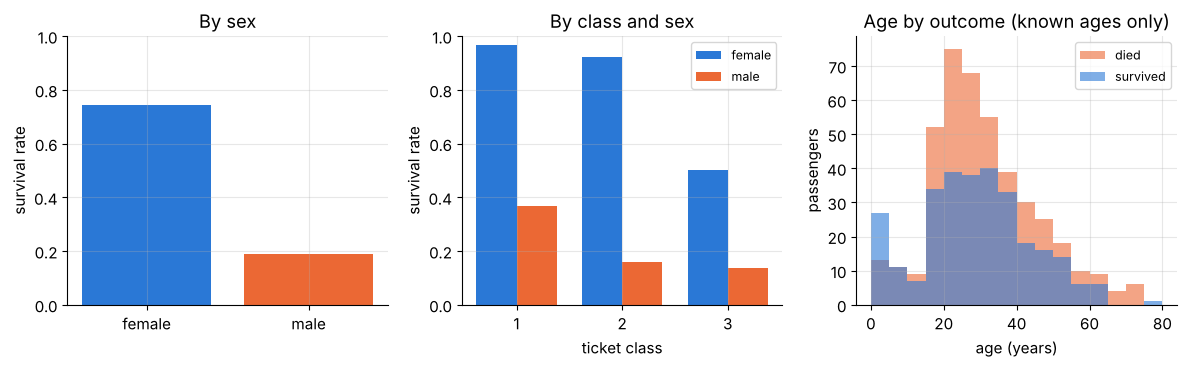

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
rate_sex = titanic.groupby("Sex")["Survived"].mean()
axes[0].bar(rate_sex.index, rate_sex.values, color=[C_POS, C_NEG])
axes[0].set(ylabel="survival rate", title="By sex", ylim=(0, 1))
rate_cls = titanic.groupby(["Pclass", "Sex"])["Survived"].mean().unstack()
for k, (sex, col) in enumerate([("female", C_POS), ("male", C_NEG)]):
    axes[1].bar(rate_cls.index + (k - 0.5) * 0.38, rate_cls[sex].values, width=0.38, color=col, label=sex)
axes[1].set(xticks=[1, 2, 3], xlabel="ticket class", ylabel="survival rate", title="By class and sex", ylim=(0, 1))
axes[1].legend(fontsize=9)
bins = np.arange(0, 85, 5)
axes[2].hist(titanic.loc[titanic["Survived"] == 0, "Age"].dropna(), bins=bins, color=C_NEG, alpha=0.6, label="died")
axes[2].hist(titanic.loc[titanic["Survived"] == 1, "Age"].dropna(), bins=bins, color=C_POS, alpha=0.6, label="survived")
axes[2].set(xlabel="age (years)", ylabel="passengers", title="Age by outcome (known ages only)")
axes[2].legend(fontsize=9)
plt.tight_layout()
plt.show()

Three strong signals jump out, all consistent with the "women and children first" evacuation order and with cabin
location: **sex** (female survival far higher than male), **class** (first class far above third, for both sexes), and
**age** (young children survived more often). About 38% of passengers survived, so the classes are imbalanced but not
extremely so. `Age` is missing for about a fifth of passengers and `Cabin` for most of them, so we need a plan for
missing values, and that plan must not peek at the validation or test data.

### 10.3 Split first, then engineer features

We split **before** looking at any statistics that will be used by the model. The test set is locked away until the very
end. The validation set is used for decisions along the way (early stopping, threshold choice). We hold out 20% as the
test set and then 12.5% of the remainder as the validation set. Both splits are **stratified** so each part keeps the
38% survival rate. (Strictly speaking, Section 10.2 already peeked at all 891 rows, including the future test passengers.
Here it only confirmed well-known patterns and no number from it enters the model, but in a real project you would split
first and explore the training rows only.)

In [59]:
from sklearn.model_selection import train_test_split

idx_all = np.arange(len(titanic))
y_all = titanic["Survived"].to_numpy(dtype=float)
idx_rest, idx_test = train_test_split(idx_all, test_size=0.2, random_state=SEED, stratify=y_all)
idx_train, idx_val = train_test_split(idx_rest, test_size=0.125, random_state=SEED, stratify=y_all[idx_rest])
train_df, val_df, test_df = (titanic.iloc[i].copy() for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]
for name, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<10}: {len(yy):>3} passengers, survival rate {yy.mean():.3f}")

train     : 623 passengers, survival rate 0.384
validation:  89 passengers, survival rate 0.382
test      : 179 passengers, survival rate 0.385


### 10.4 Feature engineering without leakage

Logistic regression needs a numeric feature vector. We will build 13 features. Every statistic used to build them (the
median age per title, the most common port, the median fare) is computed on the **training set only** and then reused,
unchanged, on validation and test data. Using statistics of the validation or test rows would leak information about
them into training and make our evaluation optimistic. This is **data leakage**, one of the most common mistakes in
applied machine learning.

**Titles.** Every name contains a title between the comma and the first period: "Braund, **Mr**. Owen Harris". Titles
encode sex, rough age ("Master" was used for boys) and social status, so they are surprisingly informative.

In [60]:
TITLE_GROUPS = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}        # French/variant forms of common titles


def extract_title(names: pd.Series) -> pd.Series:
    """'Braund, Mr. Owen Harris' -> 'Mr'. Common titles are kept, and everything else becomes 'Rare'."""
    raw = names.str.extract(r",\s*([^.]+)\.", expand=False).str.strip().replace(TITLE_GROUPS)
    return raw.where(raw.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")


train_titles = extract_title(train_df["Name"])
title_summary = pd.DataFrame({"count": train_titles.value_counts(),
                              "survival rate": train_df.groupby(train_titles)["Survived"].mean(),
                              "median age": train_df.groupby(train_titles)["Age"].median(),
                              "age missing": train_df["Age"].isna().groupby(train_titles).sum()})
display(title_summary.round(3))

,count,survival rate,median age,age missing
Name,,,,
Master,27,0.519,3.5,3
Miss,127,0.709,22.0,21
Mr,358,0.151,29.0,80
Mrs,95,0.779,35.5,11
Rare,16,0.438,49.0,1


The training set shows why titles matter: "Master" (boys) survived far more often than "Mr" (men), and the median ages
differ a lot between titles, so filling a missing age with the median *of the passenger's title group* is much better than
one global median.

Our 13 features, and the reasoning behind each:

| feature | definition | why |
|---|---|---|
| `is_female` | 1 if female | the strongest signal |
| `class_2`, `class_3` | one-hot ticket class (first class is the baseline) | class is categorical: no reason for equal steps 1→2→3 |
| `age` | age, missing values filled with the training median of the title group | children were prioritized |
| `age_missing` | 1 if age was missing | missingness itself can carry information |
| `is_alone`, `large_family` | family size $=$ SibSp $+$ Parch $+ 1$ equal to 1, or at least 5 | small families did best, large ones worst |
| `log_fare` | $\log(1 + \text{fare})$ | fares are very skewed (0 to 512), and the log compresses them |
| `port_Q`, `port_S` | one-hot port (Cherbourg is the baseline), missing → training mode | weak signal, mostly through class |
| `title_Master`, `title_Rare` | boys, plus officers, clergy, nobility and doctors | age/status information beyond sex |
| `has_cabin` | 1 if a cabin number is recorded | mostly first class, cabins near the deck |

Each categorical variable drops one category (the **baseline**). Keeping all of them would make the one-hot columns sum to
the bias column of ones, so infinitely many parameter vectors would give the same predictions (the "dummy variable
trap"). For the same reason we do not add `title_Miss` and `title_Mrs`: together they are almost exactly `is_female`.

In [61]:
class TitanicFeatures:
    """Feature builder: fit() learns statistics from the TRAINING rows only, transform() applies them to any rows."""

    def fit(self, df):
        title = extract_title(df["Name"])
        self.age_by_title_ = df["Age"].groupby(title).median().to_dict()
        self.age_median_ = float(df["Age"].median())          # fallback if a title group has no known ages
        self.port_mode_ = df["Embarked"].mode()[0]
        self.fare_median_ = float(df["Fare"].median())
        return self

    def transform(self, df):
        title = extract_title(df["Name"])
        age = df["Age"].fillna(title.map(self.age_by_title_)).fillna(self.age_median_)
        family = df["SibSp"] + df["Parch"] + 1
        port = df["Embarked"].fillna(self.port_mode_)
        feats = {
            "is_female": df["Sex"] == "female",
            "class_2": df["Pclass"] == 2, "class_3": df["Pclass"] == 3,
            "age": age, "age_missing": df["Age"].isna(),
            "is_alone": family == 1, "large_family": family >= 5,
            "log_fare": np.log1p(df["Fare"].fillna(self.fare_median_)),
            "port_Q": port == "Q", "port_S": port == "S",
            "title_Master": title == "Master", "title_Rare": title == "Rare",
            "has_cabin": df["Cabin"].notna(),
        }
        return pd.DataFrame(feats, index=df.index).astype(float)


features = TitanicFeatures().fit(train_df)                 # <- the only place where statistics are learned
X_train_df, X_val_df, X_test_df = (features.transform(d) for d in (train_df, val_df, test_df))
print("age fill values learned on train:", {k: round(v, 1) for k, v in features.age_by_title_.items()})
print("feature matrix shapes:", X_train_df.shape, X_val_df.shape, X_test_df.shape)
display(X_train_df.head(3))

age fill values learned on train: {'Master': 3.5, 'Miss': 22.0, 'Mr': 29.0, 'Mrs': 35.5, 'Rare': 49.0}
feature matrix shapes: (623, 13) (89, 13) (179, 13)


,is_female,class_2,class_3,age,age_missing,is_alone,large_family,log_fare,port_Q,port_S,title_Master,title_Rare,has_cabin
43,1.0,1.0,0.0,3.0,0.0,0.0,0.0,3.7514,0.0,0.0,0.0,0.0,0.0
669,1.0,0.0,0.0,35.5,1.0,0.0,0.0,3.9703,0.0,1.0,0.0,0.0,1.0
222,0.0,0.0,1.0,51.0,0.0,1.0,0.0,2.2028,0.0,1.0,0.0,0.0,0.0


**Standardize, using training statistics only.** As Section 7.5 showed, gradient descent is much happier when all
features live on similar scales. We compute the mean $\boldsymbol\mu$ and standard deviation $\mathbf{s}$ of each column on the training set,
transform all three sets with them, and only then prepend the bias column (the bias is never standardized).

In [62]:
feat_mu, feat_sd = X_train_df.mean(), X_train_df.std(ddof=0)
feat_sd = feat_sd.replace(0.0, 1.0)                          # guard: a constant column would divide by zero


def design_matrix(X_df):
    """Standardize with TRAINING statistics, then prepend the bias column: (m, 13) -> (m, 14)."""
    return add_bias(((X_df - feat_mu) / feat_sd).to_numpy())


A_train, A_val, A_test = (design_matrix(X) for X in (X_train_df, X_val_df, X_test_df))
feature_names = ["bias"] + list(X_train_df.columns)
print(f"A_train: {A_train.shape} | largest |column mean| on train: {np.abs(A_train[:, 1:].mean(axis=0)).max():.1e} | "
      f"all column stds on train equal 1: {np.allclose(A_train[:, 1:].std(axis=0), 1.0)}")
print("validation columns are NOT exactly standardized (that is expected):", A_val[:, 1:].mean(axis=0).round(2)[:4], "...")

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train_df)                    # the library version: fit on train only ...
same = np.allclose(scaler.transform(X_val_df), A_val[:, 1:])  # ... then transform, and the bias column is added separately
print("sklearn StandardScaler (fit on train) gives the same validation matrix:", same)

A_train: (623, 14) | largest |column mean| on train: 6.1e-16 | all column stds on train equal 1: True
validation columns are NOT exactly standardized (that is expected): [-0.07 -0.02  0.03 -0.  ] ...
sklearn StandardScaler (fit on train) gives the same validation matrix: True


### 10.5 The baseline to beat

Before training anything, ask what a trivial rule achieves. Predicting the majority class ("died") for everyone:

In [63]:
majority = float(y_train.mean() >= 0.5)                     # 0.0: most training passengers died
for name, yy in [("validation", y_val), ("test", y_test)]:
    print(f"majority baseline accuracy on {name}: {np.mean(yy == majority):.4f}")
p_const = y_train.mean()                                    # best constant probability = training base rate
print(f"constant-probability baseline: p = {p_const:.4f} for everyone -> validation log-loss "
      f"{np.mean(-(y_val * np.log(p_const) + (1 - y_val) * np.log(1 - p_const))):.4f}")

majority baseline accuracy on validation: 0.6180
majority baseline accuracy on test: 0.6145
constant-probability baseline: p = 0.3836 for everyone -> validation log-loss 0.6651


### 10.6 Mini-batch gradient descent from scratch, with validation monitoring

With $m = 623$ training passengers, full-batch gradient descent would be perfectly affordable, but real datasets are often
far too large for that, so we practice the standard approach: **mini-batch gradient descent**. Each epoch we shuffle the
training rows, cut them into batches of $B = 16$, and take one gradient step per batch, using the batch average
$\frac1B\tilde X_{\mathcal{B}}^\top(\sigma(\tilde X_{\mathcal{B}}\boldsymbol\theta) - \mathbf{y}_{\mathcal{B}})$ as a noisy but unbiased estimate of the full gradient. That is
$\lceil 623/16\rceil = 39$ updates per epoch. After every epoch we record the loss and accuracy on the training **and** the
validation set, and we remember the parameters with the lowest validation loss.

In [64]:
def train_minibatch(A, y, A_val, y_val, lr=0.05, batch_size=16, epochs=200, lam=0.0, patience=None, seed=SEED):
    """Mini-batch gradient descent on mean BCE (+ optional (lam/2)||w||^2) with validation monitoring.
    Returns (best_theta, history, best_epoch): best_theta has the lowest validation loss seen. If `patience`
    is set, training stops after that many epochs without improvement (early stopping)."""
    rng_mb = np.random.default_rng(seed)
    theta = np.zeros(A.shape[1])
    best_theta, best_loss, best_epoch, wait, hist = theta.copy(), np.inf, 0, 0, []
    for epoch in range(1, epochs + 1):
        order = rng_mb.permutation(len(y))                      # reshuffle every epoch
        for start in range(0, len(y), batch_size):
            batch = order[start:start + batch_size]
            grad = A[batch].T @ (special.expit(A[batch] @ theta) - y[batch]) / len(batch)
            grad[1:] += lam * theta[1:]
            theta = theta - lr * grad
        val_loss = bce_loss(theta, A_val, y_val)
        hist.append({"epoch": epoch, "train loss": bce_loss(theta, A, y), "val loss": val_loss,
                     "train acc": np.mean((A @ theta >= 0) == y), "val acc": np.mean((A_val @ theta >= 0) == y_val)})
        if val_loss < best_loss - 1e-6:
            best_theta, best_loss, best_epoch, wait = theta.copy(), val_loss, epoch, 0
        else:
            wait += 1
            if patience is not None and wait >= patience:
                break
    return best_theta, pd.DataFrame(hist).set_index("epoch"), best_epoch


t0 = time.time()
theta_full, hist_full, best_ep_full = train_minibatch(A_train, y_train, A_val, y_val, lr=0.05, epochs=200)
print(f"200 epochs (7,800 updates) in {time.time() - t0:.1f} s")
display(hist_full.loc[[1, 2, 5, 10, 20, 50, 100, 200]].round(4))
print(f"lowest validation loss {hist_full['val loss'].min():.4f} at epoch {best_ep_full}")

200 epochs (7,800 updates) in 0.1 s


,train loss,val loss,train acc,val acc
epoch,,,,
1,0.5144,0.4872,0.7929,0.8539
2,0.4636,0.4304,0.8122,0.8539
5,0.4203,0.3820,0.8379,0.8539
10,0.4062,0.3647,0.8347,0.8652
20,0.4018,0.3595,0.8299,0.8539
50,0.4012,0.3567,0.8266,0.8539
100,0.4011,0.3574,0.8266,0.8539
200,0.4011,0.3571,0.8266,0.8539


lowest validation loss 0.3563 at epoch 111


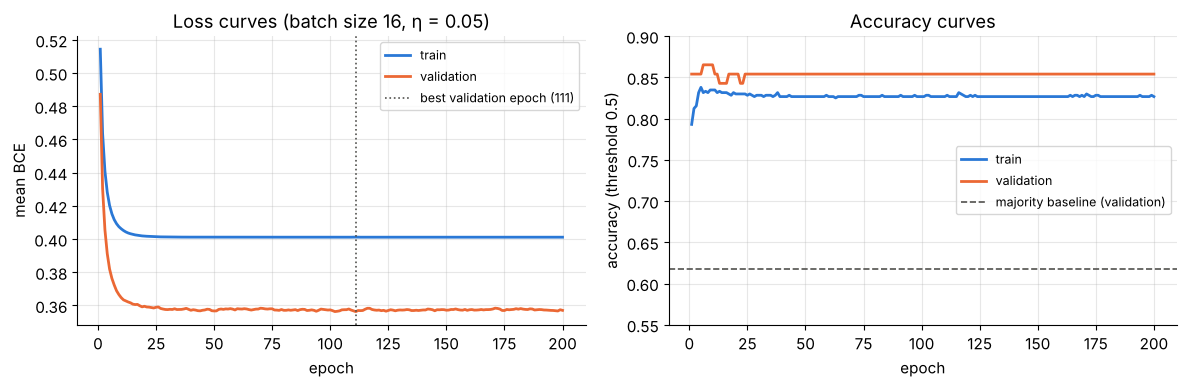

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_full.index, hist_full["train loss"], color=PALETTE[0], lw=2, label="train")
axes[0].plot(hist_full.index, hist_full["val loss"], color=PALETTE[1], lw=2, label="validation")
axes[0].axvline(best_ep_full, color=INK_SOFT, ls=":", lw=1.2, label=f"best validation epoch ({best_ep_full})")
axes[0].set(xlabel="epoch", ylabel="mean BCE", title="Loss curves (batch size 16, η = 0.05)")
axes[0].legend(fontsize=9)
axes[1].plot(hist_full.index, hist_full["train acc"], color=PALETTE[0], lw=2, label="train")
axes[1].plot(hist_full.index, hist_full["val acc"], color=PALETTE[1], lw=2, label="validation")
axes[1].axhline(np.mean(y_val == 0), color=INK_SOFT, ls="--", lw=1.2, label="majority baseline (validation)")
axes[1].set(xlabel="epoch", ylabel="accuracy (threshold 0.5)", title="Accuracy curves", ylim=(0.55, 0.9))
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

What the curves say:

* Training is fast: after about 10 epochs (390 updates) the losses are close to their final values. The curves look smooth
  because we only plot once per epoch, and within an epoch the 39 mini-batch steps zig-zag.
* The validation loss is *lower* than the training loss here. That is not a bug: the validation set has only 89
  passengers, and this particular sample happens to be a bit easier. With such a small set, a single passenger changes
  validation accuracy by $1/89 \approx 1.1$ percentage points, so do not over-interpret small differences.
* The two curves flatten and stay flat: with 14 parameters and 623 examples this model is too simple to overfit much. Its
  validation accuracy of about 0.85 is far above the 0.618 majority baseline.

### 10.7 Overfitting and early stopping

To see overfitting, give the model far more freedom: add all pairwise products and squares of the 13 standardized
features (`PolynomialFeatures(degree=2)`), which gives 104 features (105 parameters with the bias). Now the model can
memorize quirks of the training set.

In [66]:
from sklearn.preprocessing import PolynomialFeatures

poly2 = PolynomialFeatures(degree=2, include_bias=False).fit(A_train[:, 1:])
P_train, P_val = poly2.transform(A_train[:, 1:]), poly2.transform(A_val[:, 1:])
p_mu, p_sd = P_train.mean(axis=0), P_train.std(axis=0)
keep = p_sd > 1e-9                                              # drop constant columns (none expected, but be safe)
B_train = add_bias((P_train[:, keep] - p_mu[keep]) / p_sd[keep])
B_val = add_bias((P_val[:, keep] - p_mu[keep]) / p_sd[keep])
print("degree-2 design matrix:", B_train.shape)

_, hist_poly, best_poly = train_minibatch(B_train, y_train, B_val, y_val, lr=0.05, epochs=150)
_, hist_poly_l2, best_poly_l2 = train_minibatch(B_train, y_train, B_val, y_val, lr=0.05, epochs=150, lam=0.03)
_, hist_poly_es, best_poly_es = train_minibatch(B_train, y_train, B_val, y_val, lr=0.05, epochs=150, patience=20)
for name, h, be in [("no penalty", hist_poly, best_poly), ("L2, λ = 0.03", hist_poly_l2, best_poly_l2)]:
    print(f"{name:<13} best val loss {h['val loss'].min():.4f} (epoch {be}) | after 150 epochs: train loss "
          f"{h['train loss'].iloc[-1]:.4f}, val loss {h['val loss'].iloc[-1]:.4f}, train acc {h['train acc'].iloc[-1]:.3f}, "
          f"val acc {h['val acc'].iloc[-1]:.3f}")
print(f"early stopping (patience 20): stopped after epoch {hist_poly_es.index[-1]}, kept the parameters from epoch {best_poly_es}")

degree-2 design matrix: (623, 105)


no penalty    best val loss 0.3615 (epoch 11) | after 150 epochs: train loss 0.3179, val loss 0.4157, train acc 0.862, val acc 0.843
L2, λ = 0.03  best val loss 0.3557 (epoch 135) | after 150 epochs: train loss 0.3460, val loss 0.3652, train acc 0.857, val acc 0.843
early stopping (patience 20): stopped after epoch 31, kept the parameters from epoch 11


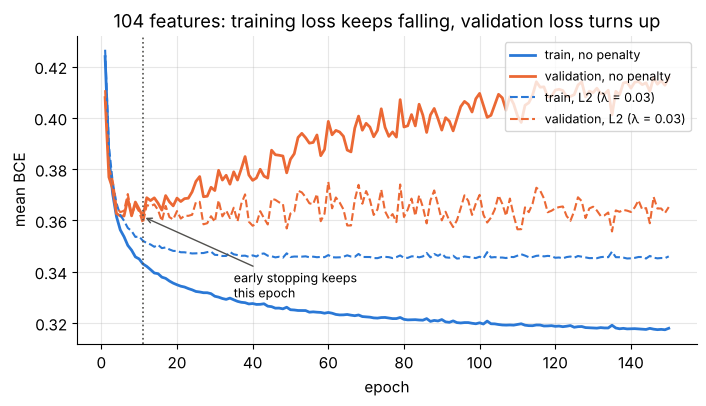

In [67]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist_poly.index, hist_poly["train loss"], color=PALETTE[0], lw=2, label="train, no penalty")
ax.plot(hist_poly.index, hist_poly["val loss"], color=PALETTE[1], lw=2, label="validation, no penalty")
ax.plot(hist_poly_l2.index, hist_poly_l2["train loss"], color=PALETTE[0], lw=1.5, ls="--", label="train, L2 (λ = 0.03)")
ax.plot(hist_poly_l2.index, hist_poly_l2["val loss"], color=PALETTE[1], lw=1.5, ls="--", label="validation, L2 (λ = 0.03)")
ax.axvline(best_poly, color=INK_SOFT, ls=":", lw=1.2)
ax.annotate("early stopping keeps\nthis epoch", (best_poly, hist_poly["val loss"].min()), xytext=(35, 0.33),
            fontsize=9, arrowprops=dict(arrowstyle="->", color=INK_SOFT))
ax.set(xlabel="epoch", ylabel="mean BCE", title="104 features: training loss keeps falling, validation loss turns up")
ax.legend(fontsize=9, loc="upper right")
plt.show()

This is the textbook picture of **overfitting**. The training loss keeps decreasing, but after the first dozen epochs the
validation loss rises: the extra parameters are being used to fit noise that does not generalize. Two remedies:

* **Early stopping** keeps the parameters from the epoch with the lowest validation loss and stops once there has been no
  improvement for `patience` epochs. It costs nothing and is used almost universally in deep learning.
* **L2 regularization** (Section 8.2) keeps the weights small, so the validation loss stays flat instead of climbing.

Both rely on the validation set, which is why it must be separate from the test set: we have now used it to make
choices, so its loss is slightly optimistic. Only the untouched test set gives an honest final estimate. Neither richer
model clearly beats the simple 13-feature model. Without a penalty, the degree-2 model's best validation loss is worse
(0.3615 vs 0.3563). With L2, its single best epoch is a hair better (0.3557), but its noisy curve mostly sits between 0.36
and 0.37, and a difference of 0.0006 is far below what 89 validation passengers can resolve. With no clear gain, we keep
the simpler model.

### 10.8 Our final model, and a comparison with scikit-learn

We train the 13-feature model with early stopping (patience 20) and compare it with three alternatives: the exact
maximum-likelihood fit by our Newton's method from Section 9, scikit-learn's unregularized fit, and scikit-learn's default
(L2-regularized, $C = 1$).

In [68]:
theta_gd, hist_gd, best_ep_gd = train_minibatch(A_train, y_train, A_val, y_val, lr=0.05, epochs=300, patience=20)
print(f"early stopping: ran {hist_gd.index[-1]} epochs, best validation loss at epoch {best_ep_gd}")

theta_newton = newton_logistic(A_train, y_train, iters=12)[-1]
sk_mle = LogisticRegression(C=np.inf, tol=1e-10, max_iter=10_000).fit(A_train[:, 1:], y_train)
sk_default = LogisticRegression().fit(A_train[:, 1:], y_train)
theta_sk_mle = np.r_[sk_mle.intercept_, sk_mle.coef_.ravel()]
theta_sk_def = np.r_[sk_default.intercept_, sk_default.coef_.ravel()]
print(f"max |Newton - sklearn MLE| over all 14 parameters: {np.max(np.abs(theta_newton - theta_sk_mle)):.1e}")

coef_table = pd.DataFrame({"mini-batch GD (early stop)": theta_gd, "Newton (MLE)": theta_newton,
                           "sklearn C=inf (MLE)": theta_sk_mle, "sklearn default C=1": theta_sk_def}, index=feature_names)
display(coef_table.round(3))
compare = []
for name, th in coef_table.items():
    th = th.to_numpy()
    compare.append({"model": name, "train loss": bce_loss(th, A_train, y_train), "val loss": bce_loss(th, A_val, y_val),
                    "val acc": np.mean((A_val @ th >= 0) == y_val)})
display(pd.DataFrame(compare).set_index("model").round(4))

early stopping: ran 70 epochs, best validation loss at epoch 50


max |Newton - sklearn MLE| over all 14 parameters: 6.1e-08


,mini-batch GD (early stop),Newton (MLE),sklearn C=inf (MLE),sklearn default C=1
bias,-0.676,-0.681,-0.681,-0.676
is_female,1.464,1.467,1.467,1.435
class_2,-0.065,-0.087,-0.087,-0.077
class_3,-0.412,-0.430,-0.430,-0.415
age,-0.265,-0.269,-0.269,-0.265
age_missing,-0.055,-0.055,-0.055,-0.054
is_alone,0.160,0.161,0.161,0.146
large_family,-0.653,-0.651,-0.651,-0.631
log_fare,0.408,0.410,0.410,0.399
port_Q,0.175,0.186,0.186,0.180


,train loss,val loss,val acc
model,,,
mini-batch GD (early stop),0.4012,0.3567,0.8539
Newton (MLE),0.4011,0.3574,0.8539
sklearn C=inf (MLE),0.4011,0.3574,0.8539
sklearn default C=1,0.4012,0.3580,0.8539


Four routes, one answer:

* Our Newton's method and scikit-learn's unregularized solver agree to about $10^{-7}$: both find the exact maximum-likelihood
  estimate (the data are not separable, so it exists).
* Mini-batch gradient descent with early stopping lands very close to it (largest gap about 0.02, for `class_2`). Stopping
  early and the default L2 penalty ($C = 1$) both shrink some weights slightly toward zero, which is the regularizing effect
  discussed in Section 8.2.
* All four reach the same validation accuracy (0.8539, i.e. 76 of 89 passengers) and nearly the same validation loss.
  For a convex problem with plenty of data, the choice of optimizer barely matters, and the features and the data matter far more.

From now on we use **our own** early-stopped model `theta_gd` and, for the first time, look at the test set.

### 10.9 The confusion matrix: four kinds of outcome

Call "survived" the **positive** class. At a threshold $t$ each test passenger falls into one of four cells:

| | predicted survived ($\hat p \ge t$) | predicted died ($\hat p < t$) |
|---|---|---|
| **actually survived** ($y = 1$) | true positive (TP) | false negative (FN) |
| **actually died** ($y = 0$) | false positive (FP) | true negative (TN) |

From these four counts come all the usual metrics:

$$
\text{accuracy} = \frac{TP + TN}{m},\quad
\text{precision} = \frac{TP}{TP + FP},\quad
\text{recall} = \frac{TP}{TP + FN},\quad
\text{specificity} = \frac{TN}{TN + FP},\quad
F_1 = \frac{2\,\text{precision}\cdot\text{recall}}{\text{precision} + \text{recall}}.
$$

* **Precision** answers "when the model says *survived*, how often is it right?"
* **Recall** (also *sensitivity* or *true positive rate*) answers "of all real survivors, how many did the model find?"
* **Specificity** is the same question for the negatives, and $1 - \text{specificity}$ is the *false positive rate*.
* $F_1$ is the *harmonic* mean of precision and recall: it is high only when both are high.

In [69]:
p_test = predict_proba(A_test, theta_gd)
yhat_test = (p_test >= 0.5).astype(float)
TP = int(np.sum((yhat_test == 1) & (y_test == 1)))
FP = int(np.sum((yhat_test == 1) & (y_test == 0)))
TN = int(np.sum((yhat_test == 0) & (y_test == 0)))
FN = int(np.sum((yhat_test == 0) & (y_test == 1)))
display(pd.DataFrame([[TP, FN], [FP, TN]], index=["actually survived", "actually died"],
                     columns=["predicted survived", "predicted died"]))

from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score, log_loss, brier_score_loss)
assert confusion_matrix(y_test, yhat_test).tolist() == [[TN, FP], [FN, TP]]     # sklearn orders rows/cols as [0, 1]

precision, recall = TP / (TP + FP), TP / (TP + FN)
metrics_05 = {"accuracy": (TP + TN) / len(y_test), "precision": precision, "recall": recall,
              "specificity": TN / (TN + FP), "F1": 2 * precision * recall / (precision + recall)}
print({k: round(v, 4) for k, v in metrics_05.items()})
print(f"sklearn check -> precision {precision_score(y_test, yhat_test):.4f}, recall {recall_score(y_test, yhat_test):.4f}, "
      f"F1 {f1_score(y_test, yhat_test):.4f}")
print(f"majority baseline accuracy on test: {np.mean(y_test == 0):.4f}")

,predicted survived,predicted died
actually survived,53,16
actually died,13,97


{'accuracy': 0.838, 'precision': 0.803, 'recall': 0.7681, 'specificity': 0.8818, 'F1': 0.7852}
sklearn check -> precision 0.8030, recall 0.7681, F1 0.7852
majority baseline accuracy on test: 0.6145


On the 179 test passengers the model is right 150 times (accuracy 0.838, against 0.6145 for "everyone died"). Of the 66
passengers it predicts to survive, 53 did (precision 0.803). Of the 69 actual survivors it finds 53 (recall 0.768). Its
29 mistakes are split into 13 false alarms and 16 missed survivors.

> **Common pitfall.** Accuracy can be badly misleading when the classes are imbalanced. If only 1% of transactions are
> fraudulent, "never fraud" is 99% accurate and completely useless. Always compare with the majority baseline and look at
> precision and recall (or the full confusion matrix).

In [70]:
# ✏️ Exercise 11: metrics from the confusion matrix
def binary_metrics(y_true, y_pred):
    """y_true, y_pred: arrays of 0/1. Return a dict with keys 'precision', 'recall', 'specificity', 'f1', 'accuracy'.
    Convention: if a denominator is 0, the metric is 0.0."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    yt = np.array([1, 1, 1, 0, 0, 0, 0, 1, 0, 0])
    yp = np.array([1, 0, 1, 1, 0, 0, 0, 1, 0, 1])
    out = binary_metrics(yt, yp)
    assert set(out) == {"precision", "recall", "specificity", "f1", "accuracy"}, f"wrong keys: {set(out)}"
    expected = {"precision": 0.6, "recall": 0.75, "specificity": 4 / 6, "f1": 2 / 3, "accuracy": 0.7}
    for k, v in expected.items():
        assert np.isclose(out[k], v), f"{k}: expected {v:.4f}, got {out[k]}"
    none = binary_metrics(np.array([0, 1, 0]), np.array([0, 0, 0]))
    assert none["precision"] == 0.0 and none["f1"] == 0.0, "no predicted positives: precision and F1 should be 0.0"

run_check("Exercise 11", _test)

⏳ Exercise 11: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def binary_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = np.sum((y_pred == 1) & (y_true == 1)); fp = np.sum((y_pred == 1) & (y_true == 0))
    tn = np.sum((y_pred == 0) & (y_true == 0)); fn = np.sum((y_pred == 0) & (y_true == 1))
    safe = lambda a, b: float(a / b) if b > 0 else 0.0
    precision, recall = safe(tp, tp + fp), safe(tp, tp + fn)
    return {"precision": precision, "recall": recall, "specificity": safe(tn, tn + fp),
            "f1": safe(2 * precision * recall, precision + recall), "accuracy": safe(tp + tn, len(y_true))}
```
In the test case TP = 3, FP = 2, TN = 4, FN = 1.
</details>

### 10.10 Every threshold at once: the ROC curve and AUC

The confusion matrix depends on the threshold. Lowering $t$ labels more passengers "survived": recall goes up, but so do
false positives. The **ROC curve** (receiver operating characteristic) shows the whole trade-off: for every threshold, plot the
true positive rate (recall) against the false positive rate $FP/(FP + TN)$. The **AUC** is the area under it.

Computing it ourselves is a nice exercise in sorting. Sort the passengers by predicted probability, from highest to
lowest, and lower the threshold one passenger at a time. Each survivor we pass moves the curve **up** by $1/m_+$
($m_+$ = number of positives), each non-survivor moves it **right** by $1/m_-$.

In [71]:
def roc_points(y, scores):
    """ROC curve by sorting: returns (fpr, tpr) arrays, starting at (0, 0). Tied scores are processed as one group."""
    order = np.argsort(-scores, kind="stable")
    y_sorted, s_sorted = y[order], scores[order]
    tps, fps = np.cumsum(y_sorted), np.cumsum(1 - y_sorted)
    last_of_group = np.r_[np.diff(s_sorted) != 0, True]           # keep only the last index of each tied group
    tpr = np.r_[0.0, tps[last_of_group] / y.sum()]
    fpr = np.r_[0.0, fps[last_of_group] / (len(y) - y.sum())]
    return fpr, tpr


fpr_ours, tpr_ours = roc_points(y_test, p_test)
auc_trapezoid = np.trapezoid(tpr_ours, fpr_ours) if hasattr(np, "trapezoid") else np.trapz(tpr_ours, fpr_ours)
pos, neg = p_test[y_test == 1], p_test[y_test == 0]
auc_pairs = np.mean((pos[:, None] > neg[None, :]) + 0.5 * (pos[:, None] == neg[None, :]))
print(f"AUC (our trapezoid)          = {auc_trapezoid:.4f}")
print(f"AUC (fraction of pairs)      = {auc_pairs:.4f}   ({len(pos)} survivors x {len(neg)} non-survivors = {len(pos) * len(neg)} pairs)")
print(f"AUC (sklearn roc_auc_score)  = {roc_auc_score(y_test, p_test):.4f}")

AUC (our trapezoid)          = 0.8635
AUC (fraction of pairs)      = 0.8635   (69 survivors x 110 non-survivors = 7590 pairs)
AUC (sklearn roc_auc_score)  = 0.8635


All three numbers agree, and the middle one gives AUC its most useful meaning:

> **Key idea.** **AUC = the probability that a randomly chosen positive gets a higher score than a randomly chosen negative**
> (ties count one half). Here: in 86% of the 7,590 (survivor, non-survivor) pairs, the survivor received the higher
> predicted probability. AUC = 0.5 is random guessing, 1.0 is a perfect ranking. AUC only depends on the *ordering* of the
> scores, so it does not care about the threshold, nor about whether the probabilities are calibrated.

### 10.11 Precision–recall curves

The ROC curve uses the false positive *rate*, which hides how many false positives there are when negatives vastly outnumber
positives. The **precision–recall (PR) curve** plots precision against recall for every threshold instead. A random
classifier has precision equal to the positive rate (here about 0.385) at every recall, so that is the baseline for the PR
curve, just as the diagonal is for ROC. Its summary number is **average precision (AP)**.

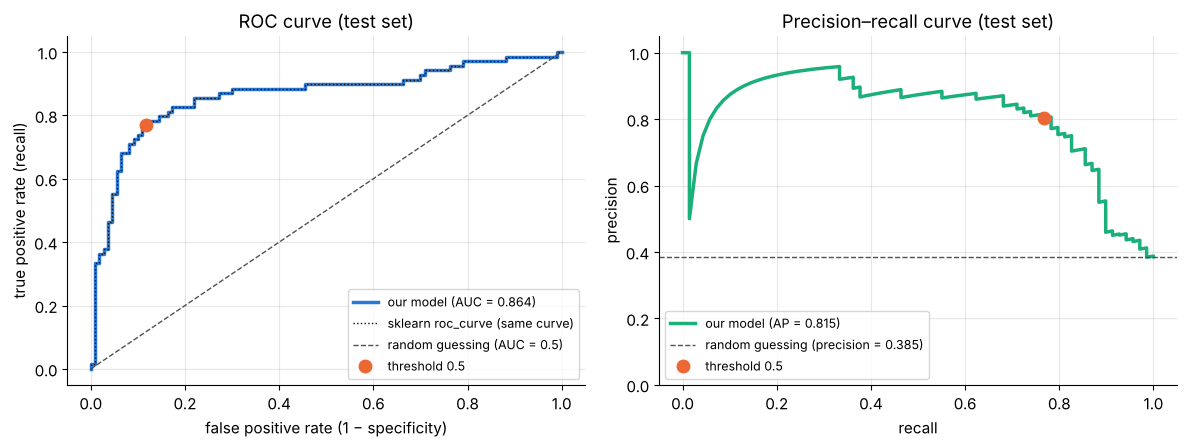

In [72]:
fpr_sk, tpr_sk, thr_roc = roc_curve(y_test, p_test)
prec_c, rec_c, thr_pr = precision_recall_curve(y_test, p_test)
ap_test = average_precision_score(y_test, p_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
ax.plot(fpr_ours, tpr_ours, color=PALETTE[0], lw=2.5, label=f"our model (AUC = {auc_trapezoid:.3f})")
ax.plot(fpr_sk, tpr_sk, color=INK, lw=1, ls=":", label="sklearn roc_curve (same curve)")
ax.plot([0, 1], [0, 1], color=INK_SOFT, ls="--", lw=1, label="random guessing (AUC = 0.5)")
ax.plot(FP / (FP + TN), TP / (TP + FN), "o", color=PALETTE[1], ms=9, label="threshold 0.5")
ax.set(xlabel="false positive rate (1 − specificity)", ylabel="true positive rate (recall)", title="ROC curve (test set)")
ax.legend(fontsize=9, loc="lower right")
ax = axes[1]
ax.plot(rec_c, prec_c, color=PALETTE[2], lw=2.5, label=f"our model (AP = {ap_test:.3f})")
ax.axhline(y_test.mean(), color=INK_SOFT, ls="--", lw=1, label=f"random guessing (precision = {y_test.mean():.3f})")
ax.plot(metrics_05["recall"], metrics_05["precision"], "o", color=PALETTE[1], ms=9, label="threshold 0.5")
ax.set(xlabel="recall", ylabel="precision", title="Precision–recall curve (test set)", ylim=(0, 1.05))
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

Moving along either curve means changing the threshold. Toward the top right of the ROC curve (bottom right of the PR curve)
the threshold is low: almost every survivor is found, at the cost of many false alarms. Which point is "best" is not a
statistical question but a question about **costs**: what is a missed positive worth compared with a false alarm?

In [73]:
# ✏️ Exercise 12: AUC by counting pairs
def auc_by_pairs(y, scores):
    """Return the fraction of (positive, negative) pairs in which the positive has the higher score, and ties count 1/2.
    y: (m,) array of 0/1, scores: (m,) array of real numbers."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert np.isclose(auc_by_pairs(np.array([0, 0, 1, 1]), np.array([0.1, 0.4, 0.35, 0.8])), 0.75), "classic 4-point example"
    assert np.isclose(auc_by_pairs(np.array([1, 0]), np.array([0.5, 0.5])), 0.5), "a tie counts one half"
    rng = np.random.default_rng(5)
    yy = (rng.random(300) < 0.3).astype(float)
    ss = rng.normal(size=300) + yy
    assert np.isclose(auc_by_pairs(yy, ss), roc_auc_score(yy, ss)), "must match sklearn's roc_auc_score"
    assert np.isclose(auc_by_pairs(yy, 5 * ss - 2), auc_by_pairs(yy, ss)), "AUC depends only on the ranking"

run_check("Exercise 12", _test)

⏳ Exercise 12: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def auc_by_pairs(y, scores):
    pos, neg = scores[y == 1], scores[y == 0]
    wins = (pos[:, None] > neg[None, :]).sum()        # broadcasting builds the full pos x neg comparison table
    ties = (pos[:, None] == neg[None, :]).sum()
    return (wins + 0.5 * ties) / (len(pos) * len(neg))
```
This uses memory proportional to $m_+ m_-$. For large data, sort once and use ranks instead (the Mann–Whitney U statistic).
</details>

### 10.12 Choosing the threshold for a goal

Suppose a historian wants a shortlist of passengers whose records to search for survivor testimonies, and the list must
contain **at least 90% of the real survivors**, and reading extra files is acceptable. Then 0.5 is the wrong threshold. The
procedure:

1. On the **validation** set, find the largest threshold whose recall is at least 0.9 (largest, because a higher threshold
   means fewer false alarms).
2. Freeze that threshold and report recall and precision on the **test** set.

Choosing the threshold on the test set and then reporting test performance would be cheating, exactly like training on it.

The largest valid threshold is easy to find: if there are $m_+$ positives and we need recall $\ge r$, we must keep at least
$k = \lceil r\,m_+\rceil$ of them, so the threshold is the $k$-th largest score among the positives.

In [74]:
def recall_threshold(y, p, target):
    """Largest threshold t such that recall of the rule (p >= t) is at least `target`."""
    pos_scores = np.sort(p[y == 1])[::-1]                         # positives' scores, highest first
    k = int(np.ceil(target * len(pos_scores) - 1e-9))            # how many positives we must keep (see the pitfall below)
    return pos_scores[k - 1]


p_val = predict_proba(A_val, theta_gd)
t90 = recall_threshold(y_val, p_val, 0.90)
print(f"validation: {int(y_val.sum())} survivors -> keep at least {int(np.ceil(0.9 * y_val.sum() - 1e-9))}, and the chosen threshold is t = {t90:.4f}")
rows = []
for name, yy, pp in [("validation", y_val, p_val), ("test", y_test, p_test)]:
    for t in [0.5, t90]:
        pred = pp >= t
        tp, fp = np.sum(pred & (yy == 1)), np.sum(pred & (yy == 0))
        rows.append({"set": name, "threshold": round(t, 4), "flagged": int(pred.sum()), "recall": tp / yy.sum(),
                     "precision": tp / max(pred.sum(), 1), "false alarms": int(fp)})
display(pd.DataFrame(rows).set_index(["set", "threshold"]).round(4))

validation: 34 survivors -> keep at least 31; chosen threshold t = 0.1377


flagged  recall  precision  false alarms
set        threshold                                          
validation 0.5000          29  0.7353     0.8621             4
           0.1377          48  0.9118     0.6458            17
test       0.5000          66  0.7681     0.8030            13
           0.1377         111  0.8841     0.5495            50

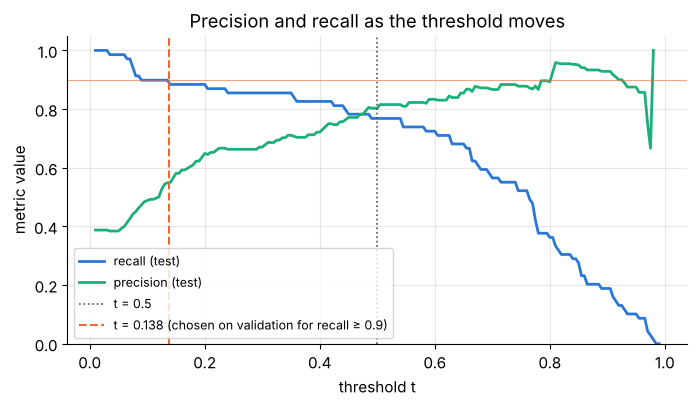

In [75]:
grid_t = np.linspace(0.01, 0.99, 197)
rec_t = np.array([np.mean(p_test[y_test == 1] >= t) for t in grid_t])
prec_t = np.array([np.mean(y_test[p_test >= t] == 1) if np.any(p_test >= t) else np.nan for t in grid_t])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid_t, rec_t, color=PALETTE[0], lw=2, label="recall (test)")
ax.plot(grid_t, prec_t, color=PALETTE[2], lw=2, label="precision (test)")
ax.axvline(0.5, color=INK_SOFT, ls=":", lw=1.2, label="t = 0.5")
ax.axvline(t90, color=PALETTE[1], ls="--", lw=1.5, label=f"t = {t90:.3f} (chosen on validation for recall ≥ 0.9)")
ax.axhline(0.9, color=PALETTE[1], lw=0.8, alpha=0.6)
ax.set(xlabel="threshold t", ylabel="metric value", title="Precision and recall as the threshold moves", ylim=(0, 1.05))
ax.legend(fontsize=9, loc="lower left")
plt.show()

The chosen threshold, $t \approx 0.138$, is far below 0.5, so many more passengers are flagged (111 of 179 instead of 66). On
the test set recall rises from 0.768 to 0.884 (61 of the 69 survivors), while precision falls from 0.803 to 0.550 and the
number of false alarms grows from 13 to 50: we bought the extra survivors with extra reading. The test recall falls a little
short of the 0.9 target because the threshold was tuned on only 34 validation survivors, and a new sample behaves a little
differently. With so few positives, treat all these test figures as estimates with error bars of several percentage points
(and if missing the target is costly, tune for a slightly higher recall, such as 0.95, on validation).

> **Common pitfall.** `np.ceil(0.55 * 100)` is **56**, not 55, because `0.55 * 100` evaluates to `55.00000000000001` in
> floating point. Many other products, such as `0.9 * 30`, happen to come out exact, which is why this bug slips through
> casual testing. When you round a product of floats up or down to an integer count, subtract (or add) a tiny tolerance
> first, as the function above does.

**Threshold moving vs class weights.** Another common way to favor recall is to **reweight the loss**: count every positive
example $k$ times (scikit-learn's `class_weight`). For a correctly specified logistic model and a large sample, this simply
shifts the bias by $\ln k$ (the odds of every passenger are multiplied by $k$) and leaves the slopes alone, which is the same
as moving the threshold. Let us see how close real data come to that ideal.

In [76]:
plain = LogisticRegression(C=np.inf, tol=1e-10, max_iter=10_000).fit(A_train[:, 1:], y_train)
print(f"unweighted          : test AUC {roc_auc_score(y_test, plain.decision_function(A_test[:, 1:])):.4f}, "
      f"mean predicted p on test {plain.predict_proba(A_test[:, 1:])[:, 1].mean():.3f} (actual survival rate {y_test.mean():.3f})")
for k in [3.0, 10.0]:
    weighted = LogisticRegression(C=np.inf, tol=1e-10, max_iter=10_000, class_weight={0: 1.0, 1: k}).fit(A_train[:, 1:], y_train)
    print(f"survivors weighted {k:>2.0f}x: bias shift {weighted.intercept_[0] - plain.intercept_[0]:+.3f} (ln k = {np.log(k):.3f}), "
          f"largest slope change {np.abs(weighted.coef_ - plain.coef_).max():.3f}, test AUC "
          f"{roc_auc_score(y_test, weighted.decision_function(A_test[:, 1:])):.4f}, mean predicted p on test "
          f"{weighted.predict_proba(A_test[:, 1:])[:, 1].mean():.3f}")

unweighted          : test AUC 0.8625, mean predicted p on test 0.390 (actual survival rate 0.385)
survivors weighted  3x: bias shift +1.119 (ln k = 1.099), largest slope change 0.222, test AUC 0.8542, mean predicted p on test 0.552
survivors weighted 10x: bias shift +2.337 (ln k = 2.303), largest slope change 0.340, test AUC 0.8462, mean predicted p on test 0.739


The bias moves by almost exactly $\ln k$ (1.119 vs 1.099 for $k = 3$, and 2.337 vs 2.303 for $k = 10$). The slopes also change
somewhat (by up to 0.22 and 0.34, against a largest slope of about 1.47), because our model is not perfectly specified, and
the test AUC drops slightly (from 0.8625 to 0.8542 and 0.8462). The bigger cost is in the probabilities: the average predicted
survival probability on the test set jumps to 0.552 and 0.739, far above the true rate of 0.385 (the unweighted model gives
0.390), so the weighted models are no longer calibrated.
Moving the threshold on top of an unweighted, calibrated model keeps both: honest probabilities and a decision rule tuned to
your goal.

In [77]:
# ✏️ Exercise 13: the threshold with the best F1 score
def best_f1_threshold(y, p):
    """Among the candidate thresholds t in np.unique(p), return (t, f1) for the rule (p >= t) with the highest F1.
    If several thresholds tie, return the largest of them."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    y = np.array([0, 0, 1, 0, 1, 1, 0, 1])
    p = np.array([0.1, 0.2, 0.3, 0.35, 0.6, 0.7, 0.75, 0.9])
    t, f1 = best_f1_threshold(y, p)
    assert np.isclose(t, 0.3) and np.isclose(f1, 0.8), f"expected (0.3, 0.8), got ({t}, {f1})"
    t2, f2 = best_f1_threshold(np.array([1, 0, 0, 1.0]), np.array([0.2, 0.4, 0.6, 0.8]))   # t=0.2 and t=0.8 tie
    assert np.isclose(t2, 0.8) and np.isclose(f2, 2 / 3), f"ties must return the largest threshold, got ({t2}, {f2})"

run_check("Exercise 13", _test)

⏳ Exercise 13: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def best_f1_threshold(y, p):
    best_t, best_f1 = None, -1.0
    for t in np.unique(p):                         # ascending, so ">=" keeps the largest tied threshold
        pred = p >= t
        tp = np.sum(pred & (y == 1))
        f1 = 2 * tp / (pred.sum() + y.sum())      # F1 = 2TP / (2TP + FP + FN) = 2TP / (#predicted + #actual)
        if f1 >= best_f1:
            best_t, best_f1 = t, f1
    return best_t, best_f1
```
The identity $F_1 = \dfrac{2\,TP}{2\,TP + FP + FN}$ avoids computing precision and recall separately (and any division by zero).
</details>

### 10.13 Can we trust the probabilities? Calibration

A model is **calibrated** if its probabilities mean what they say: among all passengers who get $\hat p \approx 0.3$, about 30%
should survive. A **reliability diagram** checks this: sort the passengers into bins by predicted probability, and plot each
bin's average prediction against its observed survival rate. A calibrated model sits on the diagonal.

Two summary scores of probability quality: the **log-loss** (our BCE, on test data) and the **Brier score**
$\frac1m\sum_i(\hat p_i - y_i)^2$, the mean squared error of the probabilities. Lower is better for both, and the natural baseline is the
constant prediction $\hat p = $ training base rate.

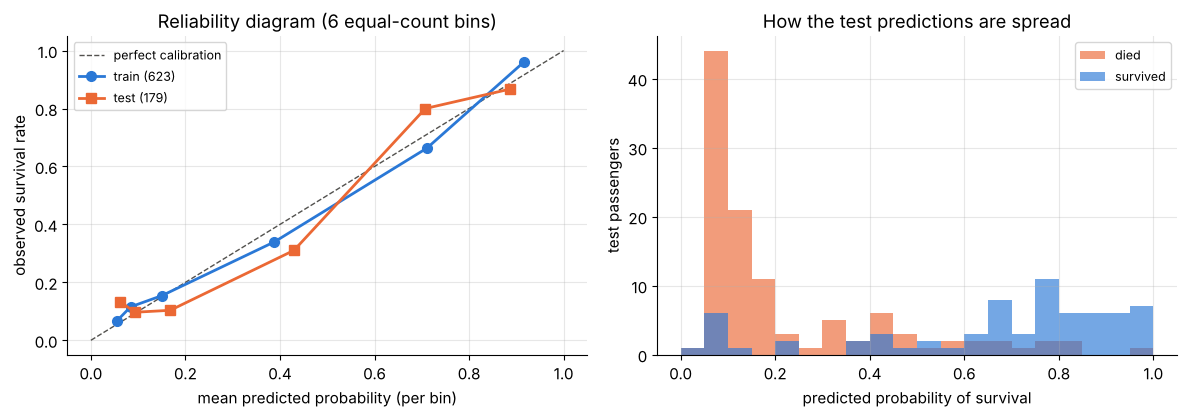

test log-loss : model 0.4343   constant base rate 0.6667
test Brier    : model 0.1306   constant base rate 0.2369


In [78]:
from sklearn.calibration import calibration_curve

p_train = predict_proba(A_train, theta_gd)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.plot([0, 1], [0, 1], color=INK_SOFT, ls="--", lw=1, label="perfect calibration")
for name, yy, pp, col, mk in [("train (623)", y_train, p_train, PALETTE[0], "o"), ("test (179)", y_test, p_test, PALETTE[1], "s")]:
    frac_pos, mean_pred = calibration_curve(yy, pp, n_bins=6, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker=mk, color=col, lw=2, ms=7, label=name)
ax.set(xlabel="mean predicted probability (per bin)", ylabel="observed survival rate", title="Reliability diagram (6 equal-count bins)")
ax.legend(fontsize=9)
axes[1].hist(p_test[y_test == 0], bins=np.linspace(0, 1, 21), color=C_NEG, alpha=0.65, label="died")
axes[1].hist(p_test[y_test == 1], bins=np.linspace(0, 1, 21), color=C_POS, alpha=0.65, label="survived")
axes[1].set(xlabel="predicted probability of survival", ylabel="test passengers", title="How the test predictions are spread")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

base = np.full_like(y_test, y_train.mean())
print(f"test log-loss : model {log_loss(y_test, p_test):.4f}   constant base rate {log_loss(y_test, base):.4f}")
print(f"test Brier    : model {brier_score_loss(y_test, p_test):.4f}   constant base rate {brier_score_loss(y_test, base):.4f}")

The points stay close to the diagonal (the test curve wiggles more because each of its bins holds only about 30 passengers).
The histogram shows *why* the model is useful: most non-survivors get probabilities below 0.2 and many survivors get
probabilities above 0.7. Both probability scores improve substantially on the constant baseline.

Logistic regression is often well calibrated "for free", and Section 6.3 tells us why. At the maximum-likelihood solution
the gradient is zero, so $\sum_i \hat p_i\,x_{ij} = \sum_i y_i\,x_{ij}$ for every feature $j$, including the bias. For a 0/1 feature this says: **within
the group that has the feature, the average predicted probability equals the observed rate**, exactly, on the training data.

In [79]:
p_train_mle = predict_proba(A_train, theta_newton)              # the exact MLE from Section 10.8
rows = []
for col in ["is_female", "class_3", "large_family", "title_Master"]:
    grp = X_train_df[col].to_numpy() == 1
    rows.append({"group": col, "passengers": int(grp.sum()), "observed survival rate": y_train[grp].mean(),
                 "mean predicted (MLE)": p_train_mle[grp].mean(), "mean predicted (early-stopped GD)": p_train[grp].mean()})
display(pd.DataFrame(rows).set_index("group").round(4))

,passengers,observed survival rate,mean predicted (MLE),mean predicted (early-stopped GD)
group,,,,
is_female,224,0.7411,0.7411,0.7415
class_3,341,0.2493,0.2493,0.2487
large_family,44,0.1818,0.1818,0.1784
title_Master,27,0.5185,0.5185,0.5118


For the exact maximum-likelihood fit the two columns agree to every digit, for every binary feature. The early-stopped model,
which is close to but not exactly at the optimum, agrees closely. This guarantee holds on the *training* data. On new data,
calibration can break down because of overfitting or because the world changed (a different ship, a different era), so
always check it on held-out data, as we did above.

> **Going deeper.** Many strong classifiers (boosted trees, support vector machines, deep networks) are *not* calibrated
> out of the box. A common fix, **Platt scaling**, fits a one-feature logistic regression on held-out data that maps the model's
> raw score $s$ to $\sigma(a s + c)$: logistic regression used as a calibration layer.

### 10.14 Interpreting the coefficients: odds ratios (with caveats)

Section 2.4 showed that $e^{w_j}$ is the factor by which the **odds** are multiplied when feature $j$ increases by one unit,
holding the other features fixed. Our weights live on the standardized scale, so $e^{w'_j}$ is the odds ratio per **one
standard deviation**, and dividing by the training standard deviation $s_j$ gives the odds ratio per **raw unit**, $e^{w'_j/s_j}$
(for a 0/1 feature, one unit is the switch from 0 to 1). We use the exact MLE and get 95% confidence intervals from
`statsmodels`, which computes standard errors from the inverse Hessian, the same matrix as in Sections 5.5 and 9.

In [80]:
import statsmodels.api as sm

sm_fit = sm.Logit(y_train, A_train).fit(disp=0)
print(f"statsmodels vs our Newton MLE: max difference {np.max(np.abs(sm_fit.params - theta_newton)):.1e}")
ci = np.asarray(sm_fit.conf_int())                                    # (14, 2) bounds for the standardized coefficients
s_raw = feat_sd.to_numpy()
or_table = pd.DataFrame({
    "coef (std)": theta_newton[1:],
    "OR per +1 SD": np.exp(theta_newton[1:]),
    "OR per +1 unit": np.exp(theta_newton[1:] / s_raw),
    "95% CI low": np.exp(ci[1:, 0] / s_raw),
    "95% CI high": np.exp(ci[1:, 1] / s_raw),
    "p-value": sm_fit.pvalues[1:],
}, index=feature_names[1:])
display(or_table.round(3))

statsmodels vs our Newton MLE: max difference 3.3e-16


,coef (std),OR per +1 SD,OR per +1 unit,95% CI low,95% CI high,p-value
is_female,1.467,4.335,21.257,12.474,36.226,0.000
class_2,-0.087,0.916,0.807,0.293,2.224,0.679
class_3,-0.430,0.651,0.422,0.140,1.275,0.126
age,-0.269,0.764,0.980,0.960,1.000,0.048
age_missing,-0.055,0.947,0.869,0.458,1.649,0.667
is_alone,0.161,1.174,1.388,0.782,2.465,0.263
large_family,-0.651,0.521,0.079,0.027,0.234,0.000
log_fare,0.410,1.507,1.528,1.008,2.315,0.046
port_Q,0.186,1.205,2.024,0.747,5.485,0.166
port_S,-0.042,0.959,0.910,0.502,1.648,0.755


How to read a few rows (all "holding the other features fixed"):

* **`is_female`: odds ratio 21.3** (95% CI 12.5 to 36.2). A woman's odds of survival are about 21 times those of a man with
  the same class, age, family, fare, port and title flags. Note that this is a ratio of **odds**, not of probabilities: if a
  man's survival probability is 0.15 (odds $0.15/0.85 \approx 0.18$), multiplying the odds by 21.3 gives odds of about 3.76, i.e. a
  probability of $3.76/4.76 \approx 0.79$, about 5 times the probability, not 21 times. Odds ratios exaggerate probability
  ratios whenever the outcome is common.
* **`age`: odds ratio 0.980 per year**, so per decade the odds are multiplied by $0.980^{10} \approx 0.82$. The interval
  (0.960 to 1.000) just touches 1, so the data are only mildly informative about age once title (which already separates
  boys from men) is in the model.
* **`large_family`: odds ratio 0.079.** Passengers in families of five or more had less than a tenth of the odds of otherwise
  similar passengers.
* **`title_Master`: odds ratio 19.5, but with a huge interval (5.2 to 73.2).** Only 27 training passengers are boys, so the data
  cannot pin the effect down precisely.
* **`class_3`: odds ratio 0.42 with an interval (0.14 to 1.28) that contains 1**, even though third-class passengers clearly died
  more often (Section 10.2). The reason is shared credit: `log_fare` and `has_cabin` also measure wealth and cabin location, so
  once they are in the model, class adds little *beyond* them.

> **Common pitfall.** Treat odds ratios from an observational dataset with care:
> 1. **Association, not causation.** The model describes who survived, not what would have happened under an intervention.
>    `has_cabin` may partly reflect *how the records were compiled* rather than anything about the cabins themselves.
> 2. **"Holding the others fixed" can be impossible.** No passenger can switch `is_female` while keeping `title_Master = 1`, and
>    with correlated features the individual coefficients are unstable, even when the predictions are excellent.
> 3. **Units and encoding matter.** Per year or per decade, per SD or per unit, which category is the baseline: always say which.
> 4. **Intervals assume the model is right** (linear log-odds, independent passengers) and shrink only slowly with more data.
>    Families travelled and died together, so passengers are not fully independent.
> 5. **With separation or near-separation** (Section 8), estimates and intervals blow up, and regularized fits shrink them.

**Quick check.** A colleague says: "The odds ratio for `has_cabin` is 2.8, so recording a cabin number nearly tripled a
passenger's chance of surviving." Name two problems with this sentence.

<details>
<summary>Answer</summary>

(1) It is the **odds** that are multiplied by 2.8, not the probability ("chance"), and for a common outcome the probability ratio is
smaller. (2) It is a **causal** claim from observational data: having a recorded cabin number does not cause survival. It is
associated with first class, with cabin location and possibly with how the records were assembled. A correct sentence:
"Passengers with a recorded cabin had about 2.8 times the odds of survival of otherwise similar passengers in our model
(95% CI 1.2 to 6.5)."
</details>

## 11. Beyond two classes: a preview

Many questions have more than two answers: which of three olympiad tracks a student will choose, which digit is in an image,
which word comes next. There are two natural ways to stretch logistic regression to $K$ classes.

**One-vs-rest (OvR).** Train $K$ separate binary logistic regressions. Classifier $k$ answers "class $k$ or not?". Predict the
class whose classifier is most confident. Simple, and it reuses everything in this notebook, but the $K$ probabilities come
from unrelated models, so they **do not sum to 1** in general.

**Softmax (multinomial logistic) regression.** One linear score per class, $z_k = \mathbf{w}_k^\top\mathbf{x} + b_k$, turned into a probability
distribution by the softmax function

$$
P(y = k \mid \mathbf{x}) = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}},
$$

trained jointly with the multi-class cross-entropy. For $K = 2$ it is exactly logistic regression:
$\dfrac{e^{z_1}}{e^{z_1} + e^{z_0}} = \dfrac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0)$, so only the *difference* of the two scores matters.

Let us compare the two on a small synthetic 3-class problem, building OvR from our own gradient-descent code.

In [81]:
rng_mc = np.random.default_rng(SEED)
centers = np.array([[-2.0, -1.0], [2.0, -1.0], [0.0, 2.0]])
X3 = np.vstack([c + rng_mc.normal(0, 1.2, size=(100, 2)) for c in centers])   # 300 points, 2 features
y3 = np.repeat([0, 1, 2], 100)
Xb3 = add_bias(X3)

# One-vs-rest: three binary logistic regressions (small L2 penalty for safety), trained with gd_run from Section 8
theta_ovr = np.array([gd_run(Xb3, (y3 == k).astype(float), lr=0.5, epochs=3000, lam=1e-3)[0] for k in range(3)])  # (3, 3)
softmax_clf = LogisticRegression(C=1e3, max_iter=5000).fit(X3, y3)      # multinomial (softmax) for 3 classes

g1, g2 = np.meshgrid(np.linspace(-6, 6, 241), np.linspace(-5, 6, 221))
G = np.column_stack([g1.ravel(), g2.ravel()])
P_ovr = sigmoid(add_bias(G) @ theta_ovr.T)                               # (n_grid, 3), columns from separate models
P_soft = softmax_clf.predict_proba(G)
sums = P_ovr.sum(axis=1)
print(f"OvR: the three probabilities sum to between {sums.min():.3f} and {sums.max():.3f} on the grid")
print(f"softmax: sums between {P_soft.sum(axis=1).min():.3f} and {P_soft.sum(axis=1).max():.3f}")
acc_ovr = np.mean(np.argmax(sigmoid(Xb3 @ theta_ovr.T), axis=1) == y3)
print(f"training accuracy: OvR {acc_ovr:.3f}, softmax {softmax_clf.score(X3, y3):.3f}")

OvR: the three probabilities sum to between 0.372 and 1.993 on the grid
softmax: sums between 1.000 and 1.000
training accuracy: OvR 0.903, softmax 0.910


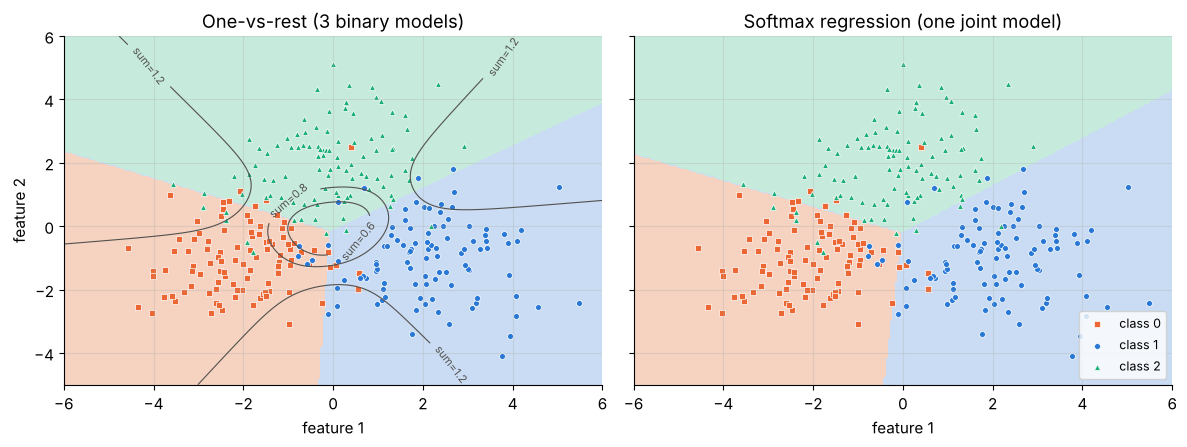

In [82]:
cls_colors = [C_NEG, C_POS, PALETTE[2]]
region_cmap = matplotlib.colors.ListedColormap(["#f6d2c0", "#c9dcf3", "#c6eadb"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, P, title in [(axes[0], P_ovr, "One-vs-rest (3 binary models)"), (axes[1], P_soft, "Softmax regression (one joint model)")]:
    ax.contourf(g1, g2, P.argmax(axis=1).reshape(g1.shape), levels=[-0.5, 0.5, 1.5, 2.5], cmap=region_cmap)
    for k, mk in enumerate(["s", "o", "^"]):
        ax.scatter(X3[y3 == k, 0], X3[y3 == k, 1], s=18, marker=mk, color=cls_colors[k], edgecolor="white", linewidth=0.5,
                   label=f"class {k}")
    ax.set(xlabel="feature 1", title=title)
cs = axes[0].contour(g1, g2, sums.reshape(g1.shape), levels=[0.6, 0.8, 1.2], colors=INK_SOFT, linewidths=0.8)
axes[0].clabel(cs, fontsize=8, fmt="sum=%.1f")
axes[0].set_ylabel("feature 2")
axes[1].legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

Both approaches carve the plane into three regions with straight boundaries, and here they make nearly the same
predictions. The difference is in the probabilities: the contour lines in the left panel show where the three OvR
probabilities add up to 0.6, 0.8 or 1.2, and over the plotted area the sum ranges from 0.37 to 1.99. Near the center, where all
three classifiers say "probably not me", the sum is far below 1, and far out along the boundaries between two classes both
of their classifiers claim the point, so the sum approaches 2. Such numbers cannot be read as a probability distribution
without an ad-hoc renormalization. Softmax produces a
proper distribution by construction, and its gradient has the same "(prediction − target) × input" form you derived in
Section 6. Notebook 09 builds softmax regression from scratch.

> **Olympiad tip.** Know these facts cold: softmax is invariant to adding the same constant to every logit (that is why
> implementations subtract $\max_k z_k$ before exponentiating, the multi-class version of the stable sigmoid). For two classes
> softmax reduces to the sigmoid of the logit difference, and OvR needs $K$ binary models while softmax needs one model with
> $K$ weight vectors (one of which is redundant).

## 12. Quiz

Try each question on paper first, then open the answer. Every answer explains why the right option is right *and* why each
wrong option is wrong.

**Q1.** A model predicts $P(y = 1 \mid \mathbf{x}) = 0.8$. What are the odds and the log-odds?

- (A) odds 0.8, log-odds $\ln 0.8 \approx -0.223$
- (B) odds 4, log-odds $\ln 4 \approx 1.386$
- (C) odds 0.25, log-odds $\approx -1.386$
- (D) odds 1.25, log-odds $\approx 0.223$

<details>
<summary>Answer</summary>

**(B).** Odds $= p/(1-p) = 0.8/0.2 = 4$ ("4 to 1"), and the log-odds is $\ln 4 \approx 1.386$.
(A) confuses the odds with the probability. (C) is the odds *against*, $0.2/0.8$. (D) is $1/p$, which is not a standard quantity.
</details>

**Q2.** A fitted model has log-odds $z = -2 + 0.7x$. If $x$ increases by 2, the odds of $y = 1$ are multiplied by

- (A) $1.4$
- (B) $e^{0.7} \approx 2.01$
- (C) $e^{1.4} \approx 4.06$
- (D) a factor that depends on the current value of $x$, because the sigmoid is nonlinear

<details>
<summary>Answer</summary>

**(C).** The log-odds rise by $0.7 \times 2 = 1.4$, so the odds are multiplied by $e^{1.4}$.
(A) adds on the log-odds scale but forgets to exponentiate. (B) is the factor for a one-unit change. (D) is true for the
change in *probability*, but the odds ratio is the same everywhere: that is exactly why odds ratios are used to report effects.
</details>

**Q3.** If $\sigma(z) = 0.9$, what is $\sigma'(z)$?

- (A) 0.09
- (B) 0.9
- (C) 0.81
- (D) 0.1

<details>
<summary>Answer</summary>

**(A).** $\sigma'(z) = \sigma(z)\big(1 - \sigma(z)\big) = 0.9 \times 0.1 = 0.09$.
(B) would make the sigmoid its own derivative (true for $e^z$, not $\sigma$). (C) is $\sigma^2$. (D) is $1 - \sigma$, only one of the two factors.
</details>

**Q4.** A 2-feature model has $\mathbf{w} = (2, -1)$ and $b = 1$. Which statement is true?

- (A) The point $(0, 3)$ is predicted to be class 1 at threshold 0.5.
- (B) The vector $(2, -1)$ is perpendicular to the decision boundary and points toward the side where $\hat p > 0.5$.
- (C) Replacing $(\mathbf{w}, b)$ by $(2\mathbf{w}, 2b)$ moves the boundary closer to the origin.
- (D) The signed distance of the origin to the boundary is $1$.

<details>
<summary>Answer</summary>

**(B).** The boundary is $\{\mathbf{x} : \mathbf{w}^\top\mathbf{x} + b = 0\}$. $\mathbf{w}$ is its normal vector, and moving along $\mathbf{w}$ increases $z$, hence $\hat p$.
(A) $z = 2\cdot 0 - 3 + 1 = -2 < 0$, so class 0. (C) Scaling both by 2 leaves the set $z = 0$ unchanged, and it only makes the
probabilities steeper. (D) The signed distance is $(\mathbf{w}^\top\mathbf{0} + b)/\|\mathbf{w}\| = 1/\sqrt{5} \approx 0.447$, not 1.
</details>

**Q5 (one gradient step by hand).** Two training examples: $(x = 2,\ y = 1)$ and $(x = -1,\ y = 0)$. Start at $w = 0$, $b = 0$ and
take one full-batch gradient-descent step on the **mean** binary cross-entropy with $\eta = 0.5$. The new parameters are

- (A) $w = 0.375$, $b = 0$
- (B) $w = -0.375$, $b = 0$
- (C) $w = 0.75$, $b = 0$
- (D) $w = 0.09375$, $b = 0$

<details>
<summary>Answer</summary>

**(A).** At zero both predictions are $\hat p = 0.5$, so the errors $\hat p - y$ are $-0.5$ and $+0.5$.
$\partial\mathcal{L}/\partial w = \frac12\big[(-0.5)(2) + (0.5)(-1)\big] = -0.75$ and $\partial\mathcal{L}/\partial b = \frac12(-0.5 + 0.5) = 0$.
Update: $w = 0 - 0.5 \times (-0.75) = 0.375$, $b = 0$.
(B) has the sign flipped (that is gradient *ascent*). (C) uses the summed gradient ($-1.5$) instead of the mean. (D) multiplies by
an extra $\sigma'(0) = 0.25$: with cross-entropy that factor cancels (Section 6.1) and must not be applied again.
</details>

**Q6.** Why is mean squared error a poor loss for logistic regression?

- (A) It cannot be differentiated through the sigmoid.
- (B) When the model is confidently wrong ($\hat p \approx 0$ while $y = 1$), its gradient is almost zero, so learning stalls, and
  it is not convex in the parameters.
- (C) It produces predicted probabilities outside $[0, 1]$.
- (D) It is convex but slower to compute.

<details>
<summary>Answer</summary>

**(B).** The MSE gradient contains the factor $\sigma'(z) = \hat p(1-\hat p)$, which vanishes exactly when the model is very sure,
including when it is very sure and wrong (Section 5.1), and the loss surface is also non-convex.
(A) It is differentiable, but the problem is the size of the gradient. (C) The outputs are still $\sigma(z) \in (0, 1)$: the
loss does not change the model. (D) MSE combined with the sigmoid is not convex.
</details>

**Q7.** A positive example ($y = 1$) has predicted probability $0.1$. After a bad update it drops to $0.01$. By how much does its
cross-entropy loss increase?

- (A) by $0.09$
- (B) by $\ln 10 \approx 2.303$
- (C) it is multiplied by 10
- (D) not at all: it was already misclassified

<details>
<summary>Answer</summary>

**(B).** The loss is $-\ln\hat p$: it goes from $\ln 10 \approx 2.303$ to $\ln 100 \approx 4.605$, an increase of $\ln 10$. Each tenfold drop
in the probability of the true class adds the same amount.
(A) is the change in probability, not in loss. (C) The loss doubles, it is not multiplied by 10. (D) Cross-entropy measures
*how* wrong a probability is, not just which side of 0.5 it lies on.
</details>

**Q8.** The Hessian of the mean BCE is $\frac1m\tilde X^\top S\tilde X$ with $S = \operatorname{diag}(\hat p_i(1-\hat p_i))$. Which conclusion is correct?

- (A) The Hessian depends on the labels $y_i$, so convexity depends on the data's labels.
- (B) It is positive semidefinite for every $\boldsymbol\theta$, so the loss is convex and every local minimum is a global minimum.
- (C) It guarantees a unique, finite minimizer for every dataset.
- (D) It is negative definite, so gradient descent must move uphill.

<details>
<summary>Answer</summary>

**(B).** For any vector $\mathbf{v}$, $\mathbf{v}^\top\tilde X^\top S\tilde X\mathbf{v} = \sum_i s_i(\tilde{\mathbf{x}}_i^\top\mathbf{v})^2 \ge 0$ because $s_i > 0$.
(A) The labels do not appear in the Hessian at all. (C) Convexity does not imply that a minimizer exists: on separable data
the infimum is never attained (Section 8). (D) The sign is the opposite.
</details>

**Q9.** You run unregularized gradient descent on BCE for a *perfectly separable* training set. What happens as training continues?

- (A) The parameters converge to a finite vector in finitely many steps.
- (B) The norm of the weights grows without bound while the training loss decreases toward 0.
- (C) The loss gets stuck at $\log 2$.
- (D) The decision boundary oscillates and never settles.

<details>
<summary>Answer</summary>

**(B).** Scaling a separating $\boldsymbol\theta$ up always lowers the loss, so there is no finite minimizer. In our experiment
$\|\boldsymbol\theta\|$ grew like the logarithm of the number of epochs while the loss fell like $1/t$.
(A) There is nothing finite to converge to. (C) $\log 2$ is the loss at $\boldsymbol\theta = \mathbf{0}$, and gradient descent moves away from it.
(D) The boundary actually *stabilizes* (it converges to the maximum-margin position), and only the scale diverges.
</details>

**Q10.** A test set has 50 positives and 950 negatives. A model flags 40 examples as positive, 30 of them correctly. Which is right?

- (A) precision 0.60, recall 0.75
- (B) precision 0.75, recall 0.60, accuracy 0.97
- (C) precision 0.75, recall 0.60, accuracy 0.75
- (D) precision 0.30, recall 0.60

<details>
<summary>Answer</summary>

**(B).** TP = 30, FP = 10, FN = 20, TN = 940. Precision $= 30/40 = 0.75$, recall $= 30/50 = 0.60$, accuracy $= 970/1000 = 0.97$.
Note that "always negative" already scores 0.95 accuracy, so 0.97 is less impressive than it sounds.
(A) swaps precision and recall. (C) confuses accuracy with precision. (D) divides TP by 100 for no reason.
</details>

**Q11.** A classifier has ROC AUC 0.80. What does that mean?

- (A) Its accuracy at threshold 0.5 is 80%.
- (B) In 80% of (positive, negative) pairs, the positive example gets the higher score.
- (C) 80% of its predicted probabilities are well calibrated.
- (D) Its recall is 0.80 when the false positive rate is 0.20.

<details>
<summary>Answer</summary>

**(B).** That is the ranking interpretation of AUC (Section 10.10).
(A) AUC does not depend on any single threshold. (C) AUC ignores calibration: any increasing transformation of the scores leaves it
unchanged. (D) describes one point of a possible ROC curve, and many different curves have area 0.80.
</details>

**Q12.** Which workflow is free of data leakage?

- (A) Standardize the full dataset, then split into train and test.
- (B) Fill missing ages with the median age of the training and test sets combined.
- (C) Learn imputation values and scaling statistics on the training split, then apply them unchanged to validation and test.
- (D) Pick the threshold that maximizes F1 on the test set, then report that F1 as the expected performance.

<details>
<summary>Answer</summary>

**(C).** Every quantity the model depends on is learned from training data only.
(A) and (B) let test-set statistics influence the training features. (D) tunes a decision on the test set, so the reported F1 is
optimistically biased, so tune on validation, report on test.
</details>

**Q13.** You raise the decision threshold from 0.5 to 0.7 without retraining. Typically,

- (A) recall increases and precision decreases
- (B) recall decreases (or stays the same) and precision usually increases
- (C) the ROC AUC changes
- (D) the learned weights change

<details>
<summary>Answer</summary>

**(B).** Fewer examples are flagged, so you can only lose true positives (recall cannot go up), while the flagged ones are the
most confident, which usually raises precision. (Precision is not *guaranteed* to rise, because it is a ratio of two counts that
both shrink.) (A) is the effect of *lowering* the threshold. (C) AUC summarizes all thresholds and does not depend on the one you
pick. (D) The threshold is applied after training, and the weights are untouched.
</details>

## 13. Summary and going further

| concept | formula / fact | where |
|---|---|---|
| Bernoulli label | $P(y \mid \mathbf{x}) = \hat p^{\,y}(1-\hat p)^{1-y}$ | §1.4 |
| odds, log-odds | $\text{odds} = \frac{p}{1-p}$, $\operatorname{logit}(p) = \log\frac{p}{1-p}$ | §2.1–2.2 |
| the model | $\operatorname{logit}(\hat p) = \mathbf{w}^\top\mathbf{x} + b \iff \hat p = \sigma(\mathbf{w}^\top\mathbf{x} + b)$ | §2.3 |
| odds ratio | $+1$ unit of $x_j$ multiplies the odds by $e^{w_j}$ (holding the rest fixed) | §2.4, §10.14 |
| sigmoid facts | $\sigma(-z) = 1 - \sigma(z)$, $\sigma' = \sigma(1-\sigma) \le \frac14$, saturates for large $\lvert z\rvert$ | §3.2 |
| stable computation | branch on the sign of $z$, and loss from logits: $\operatorname{softplus}(z) - yz$ | §3.4, §5.4 |
| decision rule | $\hat p \ge 0.5 \iff z \ge 0$, and threshold $t \iff z \ge \operatorname{logit}(t)$ | §4.1 |
| boundary geometry | hyperplane $\mathbf{w}^\top\mathbf{x} + b = 0$, normal $\mathbf{w}$, signed distance $(\mathbf{w}^\top\mathbf{x} + b)/\lVert\mathbf{w}\rVert$ | §4.2 |
| loss (MLE) | $\mathcal{L} = -\frac1m\sum_i\big[y_i\log\hat p_i + (1-y_i)\log(1-\hat p_i)\big]$ | §5.2 |
| why not MSE | non-convex with a sigmoid, vanishing gradient when confidently wrong | §5.1 |
| convexity | Hessian $\frac1m\tilde X^\top S\tilde X \succeq 0$, $S = \operatorname{diag}(\hat p_i(1-\hat p_i))$ | §5.5 |
| gradient | $\nabla_{\boldsymbol\theta}\mathcal{L} = \frac1m\tilde X^\top(\sigma(\tilde X\boldsymbol\theta) - \mathbf{y})$: error times input | §6 |
| training | full-batch or mini-batch GD, and standardize features (train statistics only) | §7, §10.6 |
| separable data | no finite MLE, $\lVert\boldsymbol\theta\rVert \to \infty$, and fix it with L2 ($+\frac\lambda2\lVert\mathbf{w}\rVert^2$, i.e. $C = 1/(\lambda m)$) or early stopping | §8 |
| Newton / IRLS | $\boldsymbol\theta \leftarrow \boldsymbol\theta - H^{-1}\nabla\mathcal{L}$: quadratic convergence, scale-invariant, costly for many features | §9 |
| evaluation | baseline, confusion matrix, precision/recall/F1, ROC/AUC (ranking), PR/AP, calibration, Brier | §10.9–10.13 |
| thresholds | tune on validation for the goal (e.g. recall ≥ 0.9), report on test | §10.12 |
| multi-class | one-vs-rest ($K$ binary models) vs softmax (one model, probabilities sum to 1) | §11 |

**Five takeaways**

1. Logistic regression is a *linear model of the log-odds*. Everything else (the sigmoid, odds ratios, the linear boundary)
   follows from that one sentence.
2. Cross-entropy is not an arbitrary choice: it is the negative log-likelihood of Bernoulli labels, it is convex, and its
   gradient is the beautifully simple "prediction error times input".
3. Gradient descent works, but feature scaling decides whether it takes 44 or 10,000 epochs, and second-order methods need
   only a handful of iterations when the number of features is moderate.
4. Perfect separation breaks maximum likelihood, and regularization (explicit or via early stopping) is the standard cure.
5. A classifier is only as good as its evaluation: compare with a baseline, look beyond accuracy, choose thresholds for the
   actual goal on validation data, check calibration, and interpret coefficients with humility.

**Going further**

- G. James, D. Witten, T. Hastie, R. Tibshirani, J. Taylor, [*An Introduction to Statistical Learning*](https://www.statlearning.com/), chapter 4
  (classification, logistic regression, ROC curves). Free PDF, very readable.
- T. Hastie, R. Tibshirani, J. Friedman, [*The Elements of Statistical Learning*](https://hastie.su.domains/ElemStatLearn/), section 4.4
  (logistic regression, IRLS, L1-regularized logistic regression).
- K. P. Murphy, [*Probabilistic Machine Learning: An Introduction*](https://probml.github.io/pml-book/book1.html), chapter 10 (logistic
  regression, including Bayesian and multinomial versions).
- D. Soudry, E. Hoffer, M. S. Nacson, S. Gunasekar, N. Srebro, [*The Implicit Bias of Gradient Descent on Separable Data*](https://jmlr.org/papers/v19/18-188.html),
  JMLR 2018: why the direction converges to the maximum-margin separator.
- A. Y. Ng, M. I. Jordan, [*On Discriminative vs. Generative Classifiers: A comparison of logistic regression and naive Bayes*](https://proceedings.neurips.cc/paper/2001/hash/7b7a53e239400a13bd6be6c91c4f6c4e-Abstract.html),
  NeurIPS 2001 (published 2002): the generative/discriminative comparison mentioned in Section 2.5.
- T. Fawcett, [*An introduction to ROC analysis*](https://doi.org/10.1016/j.patrec.2005.10.010), Pattern Recognition Letters 2006.
- A. Niculescu-Mizil, R. Caruana, [*Predicting Good Probabilities with Supervised Learning*](https://www.cs.cornell.edu/~alexn/papers/calibration.icml05.crc.rev3.pdf),
  ICML 2005: which models are calibrated, and Platt scaling vs isotonic regression.
- Library documentation: [scikit-learn logistic regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression),
  [scikit-learn model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html),
  [statsmodels `Logit`](https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.Logit.html),
  [PyTorch `BCEWithLogitsLoss`](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html).

**Next:** Notebook 09 extends everything here to many classes with softmax regression.